In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import pandas as pd

# Estilo dos gráficos
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

np.random.seed(42)
print("Setup concluído.")

Setup concluído.


# **Matemática da Computação Evolucionária aplicada ao Flappy Bird**

> **Documento didático — Fase Zero**
> Tema 3: Algoritmos Genéticos (GA) aplicados ao controle autônomo de um agente no jogo Flappy Bird

---

## Sumário

- **PARTE A — FUNDAMENTOS**
  - A.1 O que é um Algoritmo Genético
  - A.2 Analogia com evolução biológica
  - A.3 O que é um vetor
  - A.4 Número aleatório uniforme $U(0,1)$
  - A.5 Distribuição normal $\mathcal{N}(0,\sigma^2)$
  - A.6 Somatório $\sum$
  - A.7 Função de ativação

- **PARTE B — REPRESENTAÇÃO DO PÁSSARO**
  - B.1 Genoma (vetor de 6 genes)
  - B.2 Entradas sensoriais + normalização
  - B.3 Soma ponderada $z$
  - B.4 Sigmoide
  - B.5 Regra de decisão
  - B.6 Exemplo completo

- **PARTE C — FÍSICA DO JOGO**
- **PARTE D — FITNESS**
- **PARTE E — MORTE E SELEÇÃO**
- **PARTE F — CRUZAMENTO**
- **PARTE G — MUTAÇÃO**
- **PARTE H — NOVA GERAÇÃO**
- **PARTE I — CICLO COMPLETO**
- **PARTE J — GLOSSÁRIO**

# PARTE A — FUNDAMENTOS

Nesta parte não falamos de Flappy Bird ainda. Aqui construímos o alicerce: os conceitos e a notação que serão usados no resto do documento. Se você pular esta parte, o resto não vai fazer sentido.

---

## A.1 O que é um Algoritmo Genético, em linguagem de leigo

**Em termos simples:** um Algoritmo Genético (GA) é uma forma de resolver problemas por tentativa e erro organizada, imitando como a natureza faz para melhorar espécies ao longo de gerações.

Imagine que você precisa descobrir uma combinação de números (uma "receita") que faça um robô jogar bem um jogo. Você não sabe quais números usar. Poderia testar todas as combinações possíveis, mas o número de combinações é astronômico — levaria séculos. Em vez disso, você faz o seguinte:

1. Cria 50 receitas aleatórias.
2. Testa todas no jogo e dá uma nota para cada uma (nota alta = jogou bem).
3. As receitas com nota alta têm mais chance de "se reproduzir": você pega pedaços de duas boas receitas e monta uma receita nova.
4. Adiciona pequenos erros aleatórios nas receitas novas (para não ficarem todas iguais).
5. Descarta as receitas ruins e repete com as novas.

Depois de dezenas de repetições, as receitas ficam cada vez melhores — não porque você programou a solução, mas porque o processo de seleção + reprodução + erro foi empurrando a população na direção certa.

**Por que isso funciona?** Porque em quase todo problema existe uma "paisagem" onde soluções parecidas tendem a ter desempenho parecido. Se você pega duas soluções boas e mistura, frequentemente a mistura também é boa. E pequenas perturbações ocasionalmente descobrem um "degrau" ainda mais alto.

**Efeito prático:**
- Se você **aumentar** o número de indivíduos por geração, o algoritmo fica mais lento mas mais robusto.
- Se você **diminuir**, fica mais rápido mas pode não encontrar boas soluções.

**Resumo da seção:** Algoritmo Genético é resolver problemas por tentativa organizada, imitando evolução: cria população aleatória → avalia → seleciona melhores → reproduz com mistura → muta → repete. Não programamos a solução; deixamos ela emergir.

## A.2 Analogia com evolução biológica

**Em termos simples:** cada termo técnico do GA tem um correspondente na biologia. Entender essa correspondência é a chave para não se perder.

| Termo no GA | Correspondente biológico | O que significa no nosso Flappy Bird |
|-------------|--------------------------|--------------------------------------|
| **Gene** | Um trecho de DNA | Um número real (ex.: `0.31`) |
| **Genoma** (ou indivíduo) | O DNA completo de um ser vivo | Um vetor de 6 números |
| **População** | O conjunto de seres vivos de uma espécie | 50 pássaros simultâneos |
| **Geração** | Uma "rodada" de vida | Um ciclo completo: avaliar → reproduzir |
| **Fitness** (aptidão) | Quão bem o ser vivo sobrevive | Pontuação obtida no jogo |
| **Seleção natural** | Quem sobrevive para reproduzir | Escolhemos os de maior fitness como pais |
| **Cruzamento** (crossover) | Reprodução sexuada | Misturamos os genes de dois pais |
| **Mutação** | Erro na cópia do DNA | Perturbamos aleatoriamente um gene |
| **Elitismo** | Os mais fortes sempre sobrevivem | Copiamos os melhores intactos para a próxima geração |

**Como isso se lê na prática:** a natureza não "sabe" qual é o melhor DNA. Ela apenas faz com que os indivíduos mais bem adaptados tenham mais filhos. Os filhos herdam metade do DNA de cada pai, e erros de cópia ocasionais geram novidade. Ao longo de milhões de anos, isso produz olhos, asas, cérebros. No nosso caso, "milhões de anos" viram "dezenas de gerações de computador" — o princípio é o mesmo.

**Efeito prático:**
- **Sem cruzamento**, cada indivíduo só pode melhorar por mutação: evolução lenta.
- **Sem mutação**, todos os filhos ficam iguais aos pais: a evolução estagnaria em poucas gerações.
- **Sem seleção**, todos se reproduzem igualmente: não há pressão para melhorar.

**Resumo da seção:** Todo termo do GA tem gêmeo biológico. Gene é número, genoma é vetor, população é conjunto de pássaros, fitness é nota, seleção é escolher pais, cruzamento é reprodução, mutação é erro de cópia, elitismo é garantir que o melhor nunca morra. Os três pilares que fazem a evolução andar são: seleção, cruzamento e mutação — sem qualquer um deles, o algoritmo não funciona bem.

## A.3 O que é um vetor (matriz de uma linha) — do zero

**Em termos simples:** um vetor é uma lista ordenada de números. Nada mais que isso.

Quando escrevemos:

$$
v = [3, 7, 1]
$$

Estamos dizendo: "tenho três números, na ordem 3, 7, 1". O primeiro é o "gene 1", o segundo é o "gene 2", o terceiro é o "gene 3". A posição na lista importa: `[3, 7, 1]` é diferente de `[1, 7, 3]`.

### Notação

Para nos referirmos a **um** elemento do vetor, usamos índice entre colchetes:

- $v[1] = 3$ (primeiro elemento)
- $v[2] = 7$ (segundo elemento)
- $v[3] = 1$ (terceiro elemento)

> **Atenção a uma pegadinha:** em matemática, geralmente indexamos a partir de 1. Em programação (JavaScript, Python, etc.), indexamos a partir de 0. Neste documento, para ficar alinhado com a matemática tradicional, uso índice começando em 1. Na hora de implementar (Fase 1), você adaptará para começar em 0.

### Tamanho do vetor

Chamamos de **tamanho** ou **dimensão** o número de elementos. O vetor `[3, 7, 1]` tem tamanho 3.

No nosso Flappy Bird, o genoma de cada pássaro é um vetor de tamanho **6**:

$$
g = [w_1, w_2, w_3, w_4, w_5, b]
$$

### Exemplo numérico — Seção A.3

**Entrada:** $g = [0.3, -1.2, 0.8, 0.5, -0.1, 0.2]$

**Passo 1:** contar elementos → 6

**Passo 2:** $g[1] = 0.3$, $g[2] = -1.2$, $g[3] = 0.8$

**Passo 3:** $g[4] = 0.5$, $g[5] = -0.1$, $g[6] = 0.2$

**Resultado:** vetor de dimensão 6.

**Se $g[3]$ fosse $1.5$ em vez de $0.8$:** o vetor seria $[0.3, -1.2, 1.5, 0.5, -0.1, 0.2]$, com mesmo tamanho, mas o terceiro elemento diferente.

**Efeito prático:**
- **Aumentar** o tamanho do vetor = mais informação por indivíduo = mais liberdade de decisão, mas mais difícil de evoluir.
- **Diminuir** = indivíduo mais "burro", mas mais fácil de evoluir.

**Resumo da seção:** Vetor é lista ordenada de números. Acessamos cada elemento por índice. Nosso genoma é um vetor de 6 números. Tamanho do vetor é quantos elementos ele tem.

## A.4 O que é um número aleatório uniforme $U(0,1)$ — do zero

**Em termos simples:** é um número sorteado ao acaso entre 0 e 1, onde **qualquer valor tem a mesma chance** de sair.

### A notação

Quando escrevemos:

$$
u \sim U(0,1)
$$

Estamos dizendo: "$u$ é um número sorteado de uma distribuição **U**niforme entre **0** e **1**". O símbolo $\sim$ lê-se "tem distribuição".

- $U$ vem de **Uniforme**
- $(0, 1)$ significa "entre 0 e 1"

### O que "uniforme" quer dizer

Numa distribuição uniforme, a probabilidade de cair em qualquer subintervalo do mesmo tamanho é igual. Exemplos:

- Probabilidade de cair entre 0 e 0.1 = 10%
- Probabilidade de cair entre 0.5 e 0.6 = 10%
- Probabilidade de cair entre 0.9 e 1.0 = 10%

O gráfico da densidade de probabilidade em função do valor é uma **linha reta horizontal** (uma "caixa"). Execute a célula de código a seguir para visualizar.

### Como sortear na prática

Em qualquer linguagem, existe uma função que devolve exatamente isso. Em JavaScript é `Math.random()`. Ela pode devolver `0.0001234`, `0.7823`, `0.999...`, todos com mesma chance.

### Onde usamos $U(0,1)$ no GA

- **Inicialização:** sortear os genes iniciais da população
- **Cruzamento uniforme:** decidir de qual pai vem cada gene
- **Torneio:** sortear quais indivíduos entram no torneio
- **Mutação:** sortear se um gene vai mutar
- **Taxa de cruzamento:** sortear se um par cruza

Praticamente todo passo do GA usa pelo menos um sorteio uniforme.

### Exemplo numérico — Seção A.4

**Entrada:** nenhuma (é um sorteio)

**Passo 1:** chamar a função de sorteio → retorna $0.7234$

**Passo 2:** como $0.7234 \in [0,1]$, é válido

**Passo 3:** chamar de novo → retorna $0.0521$

**Resultado:** dois valores sorteados: $u_1 = 0.7234$, $u_2 = 0.0521$.

**Se a função retornasse $1.5$:** seria inválido (fora de $[0,1]$). **Se retornasse $-0.3$:** também inválido.

**Efeito prático:**
- Se você sortear muitos valores $U(0,1)$ e tirar a média, ela se aproxima de **0.5**.
- Se você sortear 100 valores e contar quantos são menores que 0.3, aproximadamente **30** serão.

**Resumo da seção:** $U(0,1)$ é um sorteio uniforme entre 0 e 1. Todos os valores têm a mesma chance. Usamos em todos os passos do GA para tomar decisões aleatórias controladas.

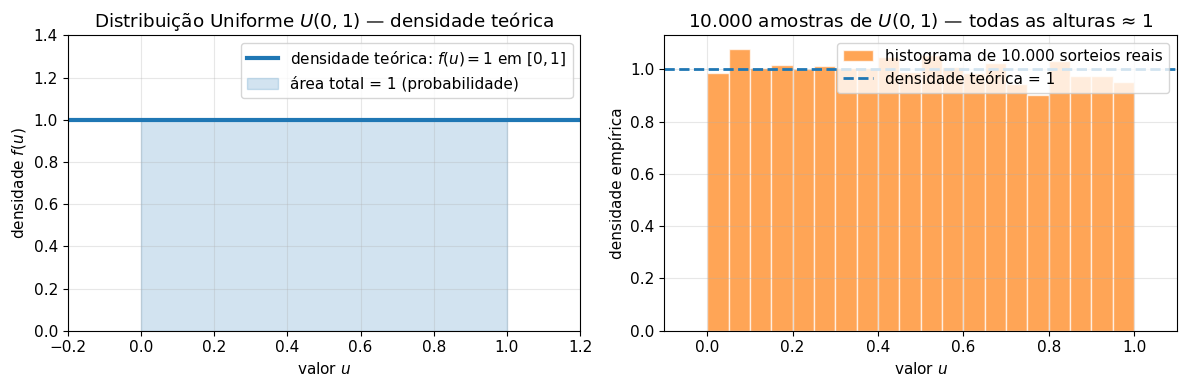

Média amostral:  0.4942  (esperado: 0.5000)
Desvio-padrão:   0.2876   (esperado: 0.2887)
Frequência de u < 0.3: 0.305  (esperado: 0.300)
Frequência de u < 0.7: 0.711  (esperado: 0.700)


In [ ]:
# Gráfico da densidade uniforme U(0,1) vs. histograma de amostras reais
np.random.seed(42)
amostras = np.random.uniform(0, 1, 10000)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# (1) Densidade teórica: retângulo de altura 1 em [0,1]
ax1.axhline(1.0, xmin=0, xmax=1, color='#1f77b4', linewidth=3,
            label=r'densidade teórica: $f(u)=1$ em $[0,1]$')
ax1.fill_between([0, 1], [1, 1], alpha=0.2, color='#1f77b4',
                 label='área total = 1 (probabilidade)')
ax1.set_xlim(-0.2, 1.2)
ax1.set_ylim(0, 1.4)
ax1.set_xlabel('valor $u$')
ax1.set_ylabel('densidade $f(u)$')
ax1.set_title(r'Distribuição Uniforme $U(0,1)$ — densidade teórica')
ax1.legend(loc='upper right')

# (2) Histograma de 10000 amostras reais
ax2.hist(amostras, bins=20, density=True, alpha=0.7,
         color='#ff7f0e', edgecolor='white',
         label='histograma de 10.000 sorteios reais')
ax2.axhline(1.0, color='#1f77b4', linewidth=2, linestyle='--',
            label='densidade teórica = 1')
ax2.set_xlim(-0.1, 1.1)
ax2.set_xlabel('valor $u$')
ax2.set_ylabel('densidade empírica')
ax2.set_title(r'10.000 amostras de $U(0,1)$ — todas as alturas ≈ 1')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

# Estatísticas descritivas que confirmam o comportamento uniforme
print(f"Média amostral:  {amostras.mean():.4f}  (esperado: 0.5000)")
print(f"Desvio-padrão:   {amostras.std():.4f}   (esperado: {1/np.sqrt(12):.4f})")
print(f"Frequência de u < 0.3: {np.mean(amostras < 0.3):.3f}  (esperado: 0.300)")
print(f"Frequência de u < 0.7: {np.mean(amostras < 0.7):.3f}  (esperado: 0.700)")

## A.5 O que é uma distribuição normal $\mathcal{N}(0,\sigma^2)$ — do zero

**Em termos simples:** é um sorteio de número ao acaso, mas **não uniforme**: valores próximos da média são muito mais prováveis do que valores distantes. É a famosa "curva do sino".

### A notação

Quando escrevemos:

$$
\Delta \sim \mathcal{N}(0, \sigma^2)
$$

Estamos dizendo: "$\Delta$ (delta) é um número sorteado de uma distribuição **N**ormal com **média 0** e **variância** $\sigma^2$". O símbolo $\mathcal{N}$ vem de "Normal".

- **Média = 0:** o valor em torno do qual os sorteios se concentram é 0.
- **Variância = $\sigma^2$:** o quadrado do desvio-padrão $\sigma$. Controla o "espalhamento".

### O que é desvio-padrão $\sigma$

$\sigma$ é a letra grega **sigma**. Ela mede o quanto os valores se afastam da média em média.

- $\sigma$ **pequeno** → curva **estreita e alta** → valores quase sempre perto de 0
- $\sigma$ **grande** → curva **larga e baixa** → valores podem se afastar mais de 0

Execute a célula de código a seguir para **ver** essa diferença num gráfico real.

### A regra 68-95-99.7

Para qualquer distribuição normal:

- ~68% dos sorteios caem entre $-\sigma$ e $+\sigma$
- ~95% caem entre $-2\sigma$ e $+2\sigma$
- ~99.7% caem entre $-3\sigma$ e $+3\sigma$

Isso significa que, se $\sigma = 0.3$, valores como $+0.1$, $-0.2$, $0.05$ são muito comuns, mas $+1.5$ é raro, e $+3.0$ é quase impossível.

### Por que usamos normal na mutação

Queremos que mutações sejam geralmente **pequenas** (refinar) mas ocasionalmente **médias** (explorar). A curva gaussiana faz exatamente isso: alta probabilidade para perturbações pequenas, baixa para perturbações grandes.

### Como sortear na prática

Em JavaScript não existe função nativa para distribuição normal, mas há várias formas de simular (ex.: transformação de Box-Muller). Não precisamos nos preocupar agora com isso — ficará para a Fase 1.

### Exemplo numérico — Seção A.5

**Entrada:** $\sigma = 0.3$

**Passo 1:** 3 sorteios → $\Delta_1 = 0.12$, $\Delta_2 = -0.31$, $\Delta_3 = 0.08$

**Passo 2:** todos os três estão entre $-0.3$ e $0.3$ (dentro de $\pm 1\sigma$), o esperado em ~68% das vezes

**Resultado:** valores típicos: pequenas perturbações.

**Se $\sigma$ fosse $2.0$ em vez de $0.3$:** os mesmos sorteios poderiam ser $\Delta_1 = 0.8$, $\Delta_2 = -2.1$, $\Delta_3 = 0.5$ — perturbações muito maiores.

**Efeito prático:**
- **Aumentar $\sigma$** → mutações maiores, mais exploração, menos refinamento (o algoritmo "pula" mais).
- **Diminuir $\sigma$** → mutações finas, mais refinamento, menos exploração.

**Resumo da seção:** $\mathcal{N}(0,\sigma^2)$ é a curva do sino. Sorteia valores concentrados perto de zero. $\sigma$ controla o espalhamento. Usamos na mutação para pequenas perturbações serem comuns e grandes serem raras.

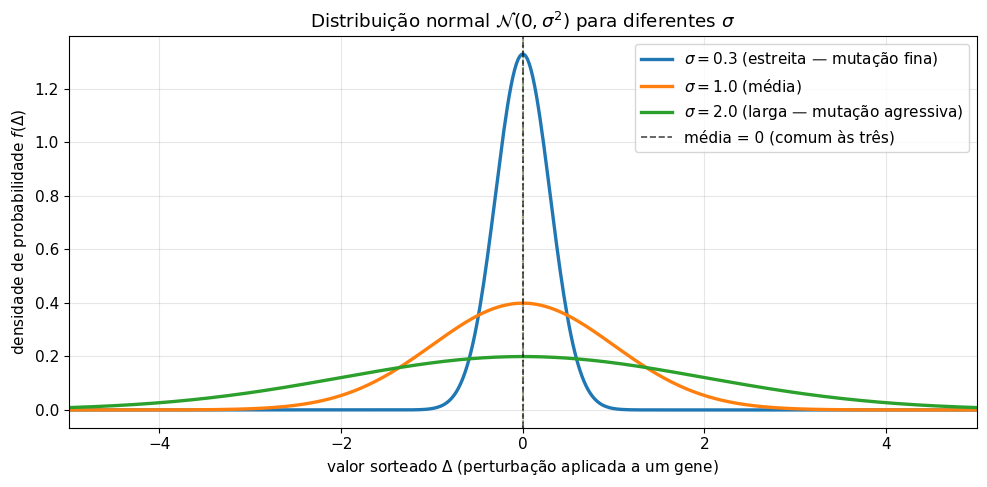

Altura do pico (densidade em Δ=0) para cada σ:
  σ = 0.3  →  pico = 1.330  |  P(|Δ| ≤ 1σ) = 68.3%
  σ = 1.0  →  pico = 0.399  |  P(|Δ| ≤ 1σ) = 68.3%
  σ = 2.0  →  pico = 0.199  |  P(|Δ| ≤ 1σ) = 68.3%


In [ ]:
# Comparação de três distribuições normais com σ diferentes
x = np.linspace(-5, 5, 500)

fig, ax = plt.subplots(figsize=(10, 5))

configs = [
    (0.3, '#1f77b4', r'$\sigma = 0.3$ (estreita — mutação fina)'),
    (1.0, '#ff7f0e', r'$\sigma = 1.0$ (média)'),
    (2.0, '#2ca02c', r'$\sigma = 2.0$ (larga — mutação agressiva)'),
]

for sigma, cor, label in configs:
    ax.plot(x, norm.pdf(x, 0, sigma), linewidth=2.4, color=cor, label=label)
    # linha vertical no pico (média = 0) com a altura correspondente
    ax.axvline(0, color=cor, linestyle=':', alpha=0.35)

ax.axvline(0, color='black', linestyle='--', alpha=0.7, linewidth=1.2,
           label='média = 0 (comum às três)')

ax.set_title(r'Distribuição normal $\mathcal{N}(0,\sigma^2)$ para diferentes $\sigma$')
ax.set_xlabel(r'valor sorteado $\Delta$ (perturbação aplicada a um gene)')
ax.set_ylabel('densidade de probabilidade $f(\Delta)$')
ax.legend(loc='upper right')
ax.set_xlim(-5, 5)

plt.tight_layout()
plt.show()

# Estatística numérica para complementar o gráfico
print("Altura do pico (densidade em Δ=0) para cada σ:")
for sigma, _, _ in configs:
    pico = norm.pdf(0, 0, sigma)
    frac_1sigma = norm.cdf(sigma, 0, sigma) - norm.cdf(-sigma, 0, sigma)
    print(f"  σ = {sigma:.1f}  →  pico = {pico:.3f}  |  "
          f"P(|Δ| ≤ 1σ) = {frac_1sigma:.1%}")

### A regra 68-95-99.7 — visualização

A regra 68-95-99.7 é uma propriedade **universal** de qualquer distribuição normal: independente do valor de $\sigma$ e da média, a proporção de amostras dentro de $k$ desvios-padrão é sempre a mesma.

| Intervalo | Proporção de sorteios | Interpretação prática com $\sigma = 0.3$ |
|-----------|----------------------|-------------------------------------------|
| $[\mu-\sigma, \mu+\sigma]$ | ~68% | ~68% das mutações ficam entre $-0.3$ e $+0.3$ |
| $[\mu-2\sigma, \mu+2\sigma]$ | ~95% | ~95% das mutações ficam entre $-0.6$ e $+0.6$ |
| $[\mu-3\sigma, \mu+3\sigma]$ | ~99.7% | ~99.7% das mutações ficam entre $-0.9$ e $+0.9$ |

**Consequência importante para o GA:** se você escolhe $\sigma = 0.3$, então mutações "gigantes" (por exemplo, um gene saltando de $0.5$ para $1.5$) são **extremamente raras** — só acontecem 0.3% das vezes. Isso é bom: o gene não muda radicalmente por acaso, apenas refina.

**Por outro lado,** se você **quiser** exploração agressiva (saltos grandes ocasionais para descobrir regiões novas do espaço de busca), precisa **aumentar** $\sigma$. Com $\sigma = 1.0$, um salto de $+1.5$ já é bem mais provável (~13% dos casos).

**Regra mnemônica:** $\sigma$ pequeno = evolução **conservadora**; $\sigma$ grande = evolução **aventureira**.

**Resumo da seção:** A regra 68-95-99.7 diz que, em qualquer normal, 68% dos valores ficam dentro de $\pm 1\sigma$, 95% dentro de $\pm 2\sigma$ e 99.7% dentro de $\pm 3\sigma$. Isso nos permite raciocinar sobre a "personalidade" da mutação: quanto menor o $\sigma$, mais conservadora é a perturbação.

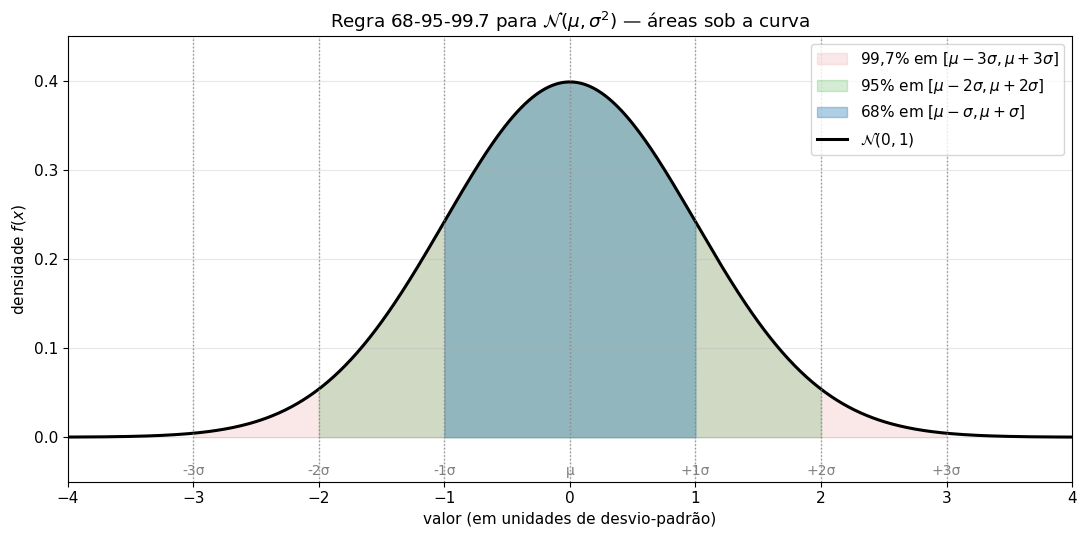

Verificação numérica exata para N(0,1):
  P(|X| ≤ 1σ) =  68.27%  (esperado ≈ 68.27%)
  P(|X| ≤ 2σ) =  95.45%  (esperado ≈ 95.45%)
  P(|X| ≤ 3σ) =  99.73%  (esperado ≈ 99.73%)

Para σ = 0.3, em termos absolutos:
  P(Δ ∈ [-0.30, +0.30]) =  68.27%
  P(Δ ∈ [-0.60, +0.60]) =  95.45%
  P(Δ ∈ [-0.90, +0.90]) =  99.73%


In [ ]:
# Ilustração das áreas sob a curva normal padrão N(0,1)
x = np.linspace(-4, 4, 500)
y = norm.pdf(x, 0, 1)

fig, ax = plt.subplots(figsize=(11, 5.5))

# Camadas de área, do mais largo para o mais estreito (para empilhamento visual correto)
camadas = [
    (-3, 3, '#d62728', 0.10, r'$99{,}7\%$ em $[\mu - 3\sigma, \mu + 3\sigma]$'),
    (-2, 2, '#2ca02c', 0.20, r'$95\%$ em $[\mu - 2\sigma, \mu + 2\sigma]$'),
    (-1, 1, '#1f77b4', 0.35, r'$68\%$ em $[\mu - \sigma, \mu + \sigma]$'),
]

for lo, hi, cor, alpha, rotulo in camadas:
    xs = np.linspace(lo, hi, 300)
    ax.fill_between(xs, norm.pdf(xs, 0, 1), alpha=alpha, color=cor, label=rotulo)

# Curva por cima das áreas
ax.plot(x, y, color='black', linewidth=2.2, label=r'$\mathcal{N}(0,1)$')

# Marcações dos desvios-padrão
for k in [-3, -2, -1, 0, 1, 2, 3]:
    ax.axvline(k, color='gray', linestyle=':', linewidth=1, alpha=0.8)
    ax.text(k, -0.03, f'{k:+d}σ' if k != 0 else 'μ',
            ha='center', va='top', fontsize=10, color='gray')

ax.set_title(r'Regra 68-95-99.7 para $\mathcal{N}(\mu,\sigma^2)$ — áreas sob a curva')
ax.set_xlabel('valor (em unidades de desvio-padrão)')
ax.set_ylabel('densidade $f(x)$')
ax.set_xlim(-4, 4)
ax.set_ylim(-0.05, 0.45)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

# Verificação numérica exata (deve bater com 68-95-99.7)
print("Verificação numérica exata para N(0,1):")
for k, esperado in [(1, 68.27), (2, 95.45), (3, 99.73)]:
    real = (norm.cdf(k, 0, 1) - norm.cdf(-k, 0, 1)) * 100
    print(f"  P(|X| ≤ {k}σ) = {real:6.2f}%  (esperado ≈ {esperado:.2f}%)")

print("\nPara σ = 0.3, em termos absolutos:")
for k in [1, 2, 3]:
    lo, hi = -k * 0.3, k * 0.3
    real = (norm.cdf(hi, 0, 0.3) - norm.cdf(lo, 0, 0.3)) * 100
    print(f"  P(Δ ∈ [{lo:+.2f}, {hi:+.2f}]) = {real:6.2f}%")

## A.6 O que é somatório $\sum$ — do zero

**Em termos simples:** o símbolo $\Sigma$ (sigma maiúsculo grego) significa "some tudo". É uma forma abreviada de escrever uma soma comprida.

### A notação

$$
\sum_{i=1}^{n} a_i
$$

Lê-se: "somatório de $a_i$, para $i$ de 1 até $n$".

Significa: pegue $a_1$, mais $a_2$, mais $a_3$, ..., até $a_n$.

Equivale a escrever:

$$
a_1 + a_2 + a_3 + \dots + a_n
$$

### Termos da notação

| Símbolo | Significado |
|---------|-------------|
| $\Sigma$ | "Some" |
| $i$ | O índice (contador) que muda a cada termo |
| $i=1$ | Comece com $i$ valendo 1 |
| $n$ | Termine quando $i$ valer $n$ |
| $a_i$ | O termo que está sendo somado (muda conforme $i$ muda) |

### Exemplo passo a passo

Suponha que queremos calcular:

$$
\sum_{i=1}^{4} i^2
$$

Lê-se: "somatório de $i$ ao quadrado, para $i$ de 1 até 4".

Passo a passo:

- $i=1$: $1^2 = 1$
- $i=2$: $2^2 = 4$
- $i=3$: $3^2 = 9$
- $i=4$: $4^2 = 16$

Soma: $1 + 4 + 9 + 16 = 30$.

### Notação alternativa mais curta

Também podemos ver $\sum_i$ ou $\sum_{i}$ sem limites explícitos: significa "some sobre todos os valores de $i$ do contexto". No GA, geralmente é óbvio pelo contexto.

### Exemplo numérico — Seção A.6

**Entrada:** vetor $a = [2, 5, 3, 1]$

**Passo 1:** $i=1 \to a_1 = 2$

**Passo 2:** $i=2 \to a_2 = 5$

**Passo 3:** $i=3 \to a_3 = 3$

**Passo 4:** $i=4 \to a_4 = 1$

**Passo 5:** somar → $2 + 5 + 3 + 1 = 11$

**Resultado:** $\sum_i a_i = 11$.

**Se $a_4$ fosse $10$ em vez de $1$:** a soma seria $2 + 5 + 3 + 10 = 20$.

**Efeito prático:** sempre que você vê $\sum$, sabe que vai somar vários termos. É atalho de escrita, não conceito novo.

**Resumo da seção:** $\sum$ significa "some todos os termos". Os limites embaixo e em cima dizem de onde até onde. É só abreviação de uma soma comprida.

## A.7 O que é uma função de ativação e por que precisamos dela

**Em termos simples:** uma função de ativação pega um número qualquer (pode ser negativo, positivo, enorme) e "aperta" ele para um intervalo controlado — normalmente entre 0 e 1. Ela existe porque decisões práticas são binárias (pular ou não pular) e precisamos transformar contas em decisão.

### Por que precisamos

Nosso pássaro vai calcular uma soma ponderada $z$ (que pode dar qualquer número real). Mas a decisão final é **binária**: pular ou não pular. Como converter $-3.7$ ou $+12.4$ em "sim" ou "não"?

Uma função de ativação resolve isso. Ela recebe $z$ e devolve um número em $[0, 1]$ que interpretamos como "probabilidade de pular". Se for $> 0.5$, pulamos; se não, não.

### Por que não usar só "se $z > 0$, pula"

Poderíamos. Mas a **sigmoide** (a função que usaremos) tem uma vantagem: ela é **suave**. Pequenas mudanças em $z$ produzem pequenas mudanças na saída. Isso ajuda o GA, porque permite que pequenas mutações nos pesos gerem pequenas mudanças de comportamento — o que é ótimo para refinamento.

Se usássemos "se $z > 0$", um gene mudando de $0.001$ para $-0.001$ mudaria o comportamento radicalmente. Isso é ruim para evolução.

### A sigmoide (que será detalhada em B.4)

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

O gráfico dela é uma curva em forma de "S" (execute a célula de código a seguir para visualizar).

- $z$ muito negativo → saída ≈ 0
- $z = 0$ → saída = 0.5
- $z$ muito positivo → saída ≈ 1
- Sempre suave, sempre entre 0 e 1

### Exemplo numérico — Seção A.7

**Entrada:** $z = 0$

**Passo 1:** $e^{-0} = e^{0} = 1$

**Passo 2:** $1 + 1 = 2$

**Passo 3:** $1 / 2 = 0.5$

**Resultado:** $\sigma(0) = 0.5$.

**Se $z$ fosse $-2$ em vez de $0$:**

**Passo 1:** $e^{-(-2)} = e^{2} \approx 7.389$

**Passo 2:** $1 + 7.389 = 8.389$

**Passo 3:** $1 / 8.389 \approx 0.119$

**Resultado:** $\sigma(-2) \approx 0.119$.

**Efeito prático:** quanto maior $z$, mais próximo de 1 fica a saída (mais chance de pular). Quanto menor $z$, mais próximo de 0 (menos chance).

**Resumo da seção:** Função de ativação transforma um número qualquer em um número entre 0 e 1. Usamos a sigmoide porque é suave. Isso permite decisões binárias a partir de contas complexas, e permite que pequenas mutações gerem pequenas mudanças de comportamento — o que é essencial para o GA evoluir bem.

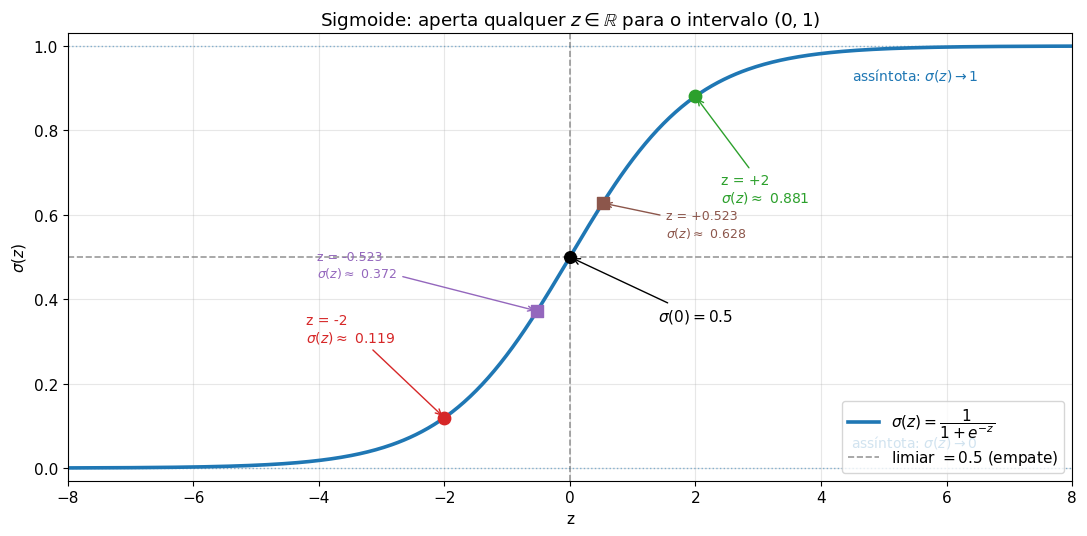

Valores da sigmoide em pontos-chave:
     z |     σ(z)
--------------------
-4.000 |   0.0180
-3.000 |   0.0474
-2.000 |   0.1192
-1.000 |   0.2689
-0.523 |   0.3722
 0.000 |   0.5000
 0.523 |   0.6278
 1.000 |   0.7311
 2.000 |   0.8808
 3.000 |   0.9526
 4.000 |   0.9820


In [ ]:
# Gráfico da sigmoide com pontos de exemplo anotados
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

z = np.linspace(-8, 8, 500)

fig, ax = plt.subplots(figsize=(11, 5.5))

ax.plot(z, sigmoid(z), color='#1f77b4', linewidth=2.6,
        label=r'$\sigma(z) = \dfrac{1}{1+e^{-z}}$')
ax.axhline(0.5, color='gray', linestyle='--', alpha=0.8, linewidth=1.2,
           label=r'limiar $= 0.5$ (empate)')
ax.axvline(0, color='gray', linestyle='--', alpha=0.8, linewidth=1.2)

# Ponto central σ(0) = 0.5
ax.scatter([0], [0.5], color='black', s=70, zorder=5)
ax.annotate(r'$\sigma(0) = 0.5$',
            xy=(0, 0.5), xytext=(1.4, 0.35),
            arrowprops=dict(arrowstyle='->', color='black'),
            fontsize=11)

# Exemplos da seção A.7: z = 0, z = -2, z = +2
for zv, cor in [(-2, '#d62728'), (2, '#2ca02c')]:
    ax.scatter([zv], [sigmoid(zv)], color=cor, s=80, zorder=5)
    ax.annotate(
        f'z = {zv:+d}\n$\\sigma(z) \\approx$ {sigmoid(zv):.3f}',
        xy=(zv, sigmoid(zv)),
        xytext=(zv + (-2.2 if zv < 0 else 0.4),
                sigmoid(zv) + (0.18 if zv < 0 else -0.25)),
        arrowprops=dict(arrowstyle='->', color=cor),
        fontsize=10, color=cor,
    )

# Exemplo da seção B.4: z = ±0.523
for zv, cor in [(-0.523, '#9467bd'), (0.523, '#8c564b')]:
    ax.scatter([zv], [sigmoid(zv)], color=cor, s=70, zorder=5, marker='s')
    ax.annotate(
        f'z = {zv:+.3f}\n$\\sigma(z) \\approx$ {sigmoid(zv):.3f}',
        xy=(zv, sigmoid(zv)),
        xytext=(zv + (-3.5 if zv < 0 else 1.0),
                sigmoid(zv) + (0.08 if zv < 0 else -0.08)),
        arrowprops=dict(arrowstyle='->', color=cor),
        fontsize=9, color=cor,
    )

# Anotações das assíntotas
ax.axhline(1.0, color='#1f77b4', linestyle=':', alpha=0.5, linewidth=1)
ax.axhline(0.0, color='#1f77b4', linestyle=':', alpha=0.5, linewidth=1)
ax.text(6.5, 0.92, r'assíntota: $\sigma(z) \to 1$', fontsize=10,
        color='#1f77b4', ha='right')
ax.text(6.5, 0.05, r'assíntota: $\sigma(z) \to 0$', fontsize=10,
        color='#1f77b4', ha='right')

ax.set_title(r'Sigmoide: aperta qualquer $z \in \mathbb{R}$ para o intervalo $(0,1)$')
ax.set_xlabel('z')
ax.set_ylabel(r'$\sigma(z)$')
ax.set_ylim(-0.03, 1.03)
ax.set_xlim(-8, 8)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

# Tabela de valores para reforçar a intuição
print("Valores da sigmoide em pontos-chave:")
print(f"{'z':>6} | {'σ(z)':>8}")
print("-" * 20)
for zv in [-4, -3, -2, -1, -0.523, 0, 0.523, 1, 2, 3, 4]:
    print(f"{zv:>6.3f} | {sigmoid(zv):>8.4f}")

# PARTE B — REPRESENTAÇÃO DO PÁSSARO

Agora aplicamos a matemática da Parte A para representar um pássaro. Cada pássaro terá um "cérebro" minúsculo com 6 números.

---

## B.1 O genoma (vetor de 6 genes)

**Em termos simples:** cada pássaro tem uma "receita" de 6 números que define como ele decide pular. Esses 6 números são seu DNA.

### A fórmula

$$
g = [w_1, w_2, w_3, w_4, w_5, b]
$$

### Cada símbolo

| Símbolo | Significado |
|---------|-------------|
| $g$ | Genoma (o vetor inteiro do pássaro) |
| $w_1$ | Peso para a **posição vertical** |
| $w_2$ | Peso para a **velocidade vertical** |
| $w_3$ | Peso para a **distância horizontal ao próximo cano** |
| $w_4$ | Peso para a **altura do centro do vão** |
| $w_5$ | Peso para a **diferença entre a altura do pássaro e o centro do vão** |
| $b$ | Bias (viés): tendência base do pássaro pular ou não |

### O que é "peso"

Um **peso** é um multiplicador. Ele diz "quanta importância essa entrada tem para a decisão final". Se $w_2$ for grande e positivo, a velocidade vertical influencia muito a decisão. Se $w_2$ for zero, a velocidade é ignorada. Se for negativo, a velocidade tem efeito invertido (quanto mais rápido caindo, menos chance de pular — o que é contraintuitivo e provavelmente será descartado pela seleção).

### O que é "bias"

O bias é uma constante somada no final, independente das entradas. Ele permite que o pássaro tenha uma "tendência" básica: se $b$ for muito positivo, ele tende a pular mesmo sem estímulo. Se for muito negativo, tende a não pular.

### Valores iniciais

No início do algoritmo, cada peso é sorteado aleatoriamente em $[-1, 1]$. Não é regra universal — alguns autores usam $[-0.5, 0.5]$ ou $[-2, 2]$ — mas $[-1, 1]$ é um bom ponto de partida.

### Exemplo numérico — Seção B.1

**Entrada:** sortear 6 valores em $[-1, 1]$

**Passo 1:** $w_1 = 0.31$

**Passo 2:** $w_2 = -0.87$

**Passo 3:** $w_3 = 0.54$

**Passo 4:** $w_4 = 0.12$

**Passo 5:** $w_5 = -0.66$

**Passo 6:** $b = 0.08$

**Resultado:** $g = [0.31, -0.87, 0.54, 0.12, -0.66, 0.08]$.

**Se a faixa fosse $[-5, 5]$ em vez de $[-1, 1]$:** os valores poderiam ser bem maiores, tipo $[3.2, -4.1, 1.8, 0.4, -2.9, 1.1]$. Isso permitiria decisões mais extremas, mas a convergência inicial seria mais caótica.

**Efeito prático:**
- Faixa muito pequena (ex.: $[-0.1, 0.1]$) → todos pássaros começam quase iguais → pouca diversidade inicial.
- Faixa muito grande (ex.: $[-100, 100]$) → todos pássaros começam extremos → caos inicial.
- Faixa $[-1, 1]$ é um bom equilíbrio para começar.

**Resumo da seção:** O genoma é o vetor de 6 números do pássaro: 5 pesos (um por entrada sensorial) e 1 bias. Esses números começam aleatórios em $[-1, 1]$ e evoluem ao longo das gerações.

## B.2 As 5 entradas sensoriais (o que o pássaro "vê") + normalização

**Em termos simples:** o pássaro precisa de informação do ambiente para decidir. Definimos 5 informações que ele "vê" a cada frame. Antes de usar, "esprememos" todas para o intervalo $[0, 1]$ para que o cálculo fique consistente.

### A fórmula da normalização

$$
x_i = \frac{\text{valor}_{\text{bruto}} - \text{mínimo}}{\text{máximo} - \text{mínimo}}
$$

### Cada símbolo

| Símbolo | Significado |
|---------|-------------|
| $x_i$ | Valor normalizado, entre 0 e 1 |
| $\text{valor}_{\text{bruto}}$ | Valor real medido no jogo |
| $\text{mínimo}$ | Menor valor possível daquele dado |
| $\text{máximo}$ | Maior valor possível daquele dado |

**O que isso faz:** transforma qualquer número em um número entre 0 e 1, onde 0 = "está no mínimo" e 1 = "está no máximo". Meio = "está no meio".

### As 5 entradas

| Símbolo | Significado | Faixa bruta | Como normalizar |
|---------|-------------|-------------|------------------|
| $x_1$ | Posição vertical do pássaro | $[0, H]$ (altura da tela) | $x_1 = y / H$ |
| $x_2$ | Velocidade vertical | $[-v_{\max}, +v_{\max}]$ | $x_2 = (v_y + v_{\max}) / (2 v_{\max})$ |
| $x_3$ | Distância horizontal ao próximo cano | $[0, W]$ (largura) | $x_3 = d_x / W$ |
| $x_4$ | Altura do centro do vão do cano | $[0, H]$ | $x_4 = y_{\text{vão}} / H$ |
| $x_5$ | Diferença entre altura do pássaro e centro do vão | $[-H, +H]$ | $x_5 = (y - y_{\text{vão}} + H) / (2H)$ |

### Por que normalizar

Imagine que $x_3$ (distância horizontal) assume valores de 0 a 500, mas $x_1$ (posição vertical) assume 0 a 1. Se multiplicássemos pelos pesos sem normalizar, qualquer peso de $x_3$ dominaria completamente. Normalizar coloca todas as entradas em pé de igualdade — o peso decide a importância, não a escala.

### Exemplo numérico — Seção B.2

**Entrada:**
- $y = 200$ (posição do pássaro), $H = 400$
- $v_y = 5$, $v_{\max} = 10$
- $d_x = 100$, $W = 500$
- $y_{\text{vão}} = 250$
- $x_5^{\text{bruto}} = y - y_{\text{vão}} = -50$

**Passo 1:** $x_1 = 200 / 400 = 0.50$

**Passo 2:** $x_2 = (5 + 10) / (2 \cdot 10) = 15 / 20 = 0.75$

**Passo 3:** $x_3 = 100 / 500 = 0.20$

**Passo 4:** $x_4 = 250 / 400 = 0.625$

**Passo 5:** $x_5 = (-50 + 400) / 800 = 350 / 800 = 0.4375$

**Resultado:** $[0.50, 0.75, 0.20, 0.625, 0.4375]$.

**Se a posição $y$ fosse $50$ em vez de $200$:** $x_1 = 50 / 400 = 0.125$ → pássaro perto do topo. $x_5 = (50 - 250 + 400) / 800 = 200 / 800 = 0.25$ → diferença com o vão é maior.

**Efeito prático:**
- Entradas sempre em $[0, 1]$ → o pássaro "enxerga" o mundo de forma padronizada.
- Se você esquecer a normalização, o GA ainda funciona, mas fica muito mais difícil de evoluir porque pesos precisam ser ajustados em escalas muito diferentes.

**Resumo da seção:** O pássaro vê 5 informações do ambiente. Todas são normalizadas para $[0, 1]$ antes de usar. Normalização é fundamental para que pesos sejam comparáveis entre si e a evolução funcione.

## B.3 A soma ponderada $z$ — termo por termo, com exemplo numérico completo

**Em termos simples:** a soma ponderada $z$ é o "rascunho" da decisão. Ela combina as 5 entradas sensoriais, cada uma multiplicada pelo peso correspondente, e soma mais o bias.

### A fórmula

$$
z = w_1 x_1 + w_2 x_2 + w_3 x_3 + w_4 x_4 + w_5 x_5 + b
$$

Que pode ser escrita com somatório:

$$
z = \sum_{i=1}^{5} w_i x_i + b
$$

### Cada símbolo

| Símbolo | Significado |
|---------|-------------|
| $z$ | Resultado da soma ponderada (número real qualquer) |
| $w_i$ | Peso do gene $i$ |
| $x_i$ | Entrada sensorial $i$ (já normalizada, entre 0 e 1) |
| $b$ | Bias |

### Leitura intuitiva

Cada parcela $w_i x_i$ é "a contribuição da entrada $i$" para a decisão. Se $w_i$ é positivo, a entrada empurra para pular (aumenta $z$). Se $w_i$ é negativo, empurra contra. Se $x_i = 0$, a entrada não contribui (não importa quanto o peso vale).

### Exemplo numérico — Seção B.3

**Entrada:**
- $g = [0.31, -0.87, 0.54, 0.12, -0.66, 0.08]$ (pesos $w_1 \dots w_5$ e bias $b$)
- $x = [0.50, 0.75, 0.20, 0.625, 0.4375]$

**Passo 1:** $w_1 x_1 = 0.31 \cdot 0.50 = 0.155$

**Passo 2:** $w_2 x_2 = -0.87 \cdot 0.75 = -0.6525$

**Passo 3:** $w_3 x_3 = 0.54 \cdot 0.20 = 0.108$

**Passo 4:** $w_4 x_4 = 0.12 \cdot 0.625 = 0.075$

**Passo 5:** $w_5 x_5 = -0.66 \cdot 0.4375 = -0.28875$

**Passo 6:** somar tudo = $0.155 - 0.6525 + 0.108 + 0.075 - 0.28875 = -0.60325$

**Passo 7:** somar bias $b = 0.08 \to -0.60325 + 0.08 = -0.52325$

**Resultado:** $z \approx -0.523$.

**Se $w_2$ fosse $-0.2$ em vez de $-0.87$:** $w_2 x_2 = -0.2 \cdot 0.75 = -0.15$. $z = 0.155 - 0.15 + 0.108 + 0.075 - 0.28875 + 0.08 = -0.02075 \approx -0.021$ → quase zero, praticamente empatando.

**Efeito prático:**
- $z > 0$ → pássaro tende a pular
- $z < 0$ → pássaro tende a não pular
- $z = 0$ → empate
- **Aumentar o peso positivo** → empurra $z$ para cima → mais chance de pular
- **Aumentar o peso negativo** (mais negativo) → empurra $z$ para baixo → menos chance de pular

**Resumo da seção:** $z$ combina entradas e pesos por multiplicação e soma. É a "opinião bruta" do pássaro antes de decidir. Pode dar qualquer número real. Valores positivos indicam inclinação a pular.

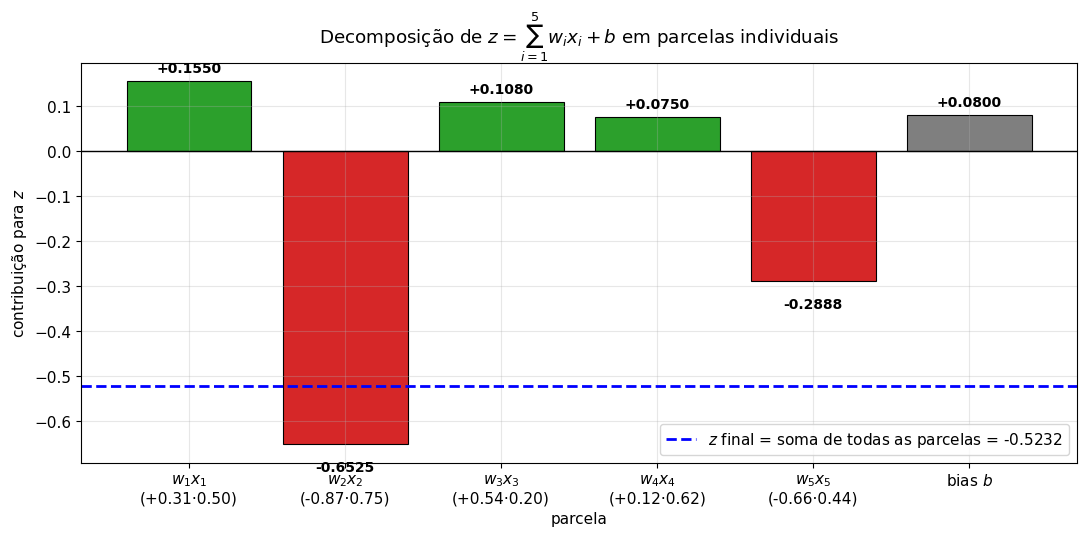

Parcela a parcela:
  w1·x1 = +0.310 × 0.5000 = +0.1550  (verde)
  w2·x2 = -0.870 × 0.7500 = -0.6525  (vermelho)
  w3·x3 = +0.540 × 0.2000 = +0.1080  (verde)
  w4·x4 = +0.120 × 0.6250 = +0.0750  (verde)
  w5·x5 = -0.660 × 0.4375 = -0.2888  (vermelho)
  bias b = +0.0800
  ----------------------------------
  z = soma das parcelas = -0.5232

σ(z) = σ(-0.5232) = 0.3721
Decisão: NÃO PULA


In [ ]:
# Decomposição de z = Σ w_i x_i + b em parcelas individuais
# Usa os valores exatos do exemplo da seção B.3

w = np.array([0.31, -0.87, 0.54, 0.12, -0.66])
x = np.array([0.50, 0.75, 0.20, 0.625, 0.4375])
b = 0.08

parcelas = w * x
rotulos = [f'$w_{i+1} x_{i+1}$\n({w[i]:+.2f}·{x[i]:.2f})' for i in range(5)]

fig, ax = plt.subplots(figsize=(11, 5.5))

cores = ['#2ca02c' if p >= 0 else '#d62728' for p in parcelas]
bars = ax.bar(
    rotulos + ['bias $b$'],
    list(parcelas) + [b],
    color=cores + ['#7f7f7f'],
    edgecolor='black',
    linewidth=0.8,
)

ax.axhline(0, color='black', linewidth=1.0)

# Rótulo com o valor de cada barra
for bar, val in zip(bars, list(parcelas) + [b]):
    offset = 0.02 if val >= 0 else -0.06
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        val + offset,
        f'{val:+.4f}',
        ha='center',
        fontsize=10,
        fontweight='bold',
    )

# Linha horizontal indicando o z final
z_total = parcelas.sum() + b
ax.axhline(
    z_total, color='blue', linestyle='--', linewidth=2,
    label=f'$z$ final = soma de todas as parcelas = {z_total:.4f}',
)

ax.set_title(r'Decomposição de $z = \sum_{i=1}^{5} w_i x_i + b$ em parcelas individuais')
ax.set_ylabel('contribuição para $z$')
ax.set_xlabel('parcela')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

# Impressão numérica para reforçar
print("Parcela a parcela:")
for i in range(5):
    sinal = '+' if parcelas[i] >= 0 else '-'
    cor = 'verde' if parcelas[i] >= 0 else 'vermelho'
    print(f"  w{i+1}·x{i+1} = {w[i]:+.3f} × {x[i]:.4f} = {parcelas[i]:+.4f}  ({cor})")
print(f"  bias b = {b:+.4f}")
print(f"  ----------------------------------")
print(f"  z = soma das parcelas = {z_total:+.4f}")

# Sigmoide do z final
p = sigmoid(z_total)
print(f"\nσ(z) = σ({z_total:.4f}) = {p:.4f}")
print(f"Decisão: {'PULA' if p > 0.5 else 'NÃO PULA'}")

## B.4 A função sigmoide — fórmula, propriedades, por que ela e não outra

**Em termos simples:** a sigmoide "aperta" o valor $z$ para o intervalo entre 0 e 1, de forma suave. É a função de ativação que usaremos.

### A fórmula

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

### Cada símbolo

| Símbolo | Significado |
|---------|-------------|
| $\sigma$ | Sigma minúsculo (nome da função sigmoide) |
| $z$ | O número de entrada (pode ser qualquer real) |
| $e$ | Número de Euler ≈ 2.71828 (constante matemática) |
| $e^{-z}$ | Exponencial de $-z$ |
| $1 + e^{-z}$ | Uma soma de 1 com a exponencial |
| $\dfrac{1}{\dots}$ | Inverso (1 dividido por...) |

### O que é a exponencial $e^x$

Antes de continuar, precisamos explicar o que é $e^x$. É a função "exponencial". Ela pega um número $x$ e devolve um número positivo que cresce rápido conforme $x$ cresce.

Valores concretos para você ter intuição:

| $x$ | $e^x$ (aprox.) |
|-------|-------------------|
| $-3$ | 0.050 |
| $-2$ | 0.135 |
| $-1$ | 0.368 |
| $0$ | 1.000 |
| $1$ | 2.718 |
| $2$ | 7.389 |
| $3$ | 20.09 |

**Regra que importa:** $e^x$ é **sempre positivo**, para qualquer $x$. Isso garante que $1 + e^{-z}$ nunca seja zero (o que causaria divisão por zero).

### Propriedades da sigmoide

| Propriedade | O que significa |
|-------------|-----------------|
| Saída sempre entre 0 e 1 | Nunca sai do intervalo — importante para decisão |
| $\sigma(0) = 0.5$ | Ponto central (empate) |
| Monotônica crescente | Se $z$ aumenta, $\sigma(z)$ aumenta |
| Suave | Pequenas mudanças em $z$ causam pequenas mudanças em $\sigma$ |
| Simétrica em torno de 0.5 | $\sigma(-z) = 1 - \sigma(z)$ |
| Satura | Para $z > 4$, $\sigma(z) \approx 1$; para $z < -4$, $\sigma(z) \approx 0$ |

### Por que sigmoide e não outra

Existem várias funções de ativação possíveis:

- **Degrau** (se $z > 0$ pula, senão não): simples mas "duro" — pequenas mudanças em $z$ causam mudanças bruscas de comportamento. Ruim para evolução suave.
- **ReLU** ($z$ se $z > 0$, senão 0): usada em redes grandes, mas para problemas pequenos como o nosso, a sigmoide funciona igual e é mais fácil de interpretar.
- **Tangente hiperbólica** ($\tanh$): parecida com a sigmoide mas em $[-1, 1]$. Válida, mas menos intuitiva para "probabilidade".
- **Sigmoide**: dá valores em $[0, 1]$, interpretação direta como "probabilidade de pular", suave, simples de calcular. É a escolha natural.

### Exemplo numérico — Seção B.4

**Entrada:** $z = -0.523$ (do exemplo da seção B.3)

**Passo 1:** $-z = 0.523$

**Passo 2:** $e^{0.523} \approx 1.687$

**Passo 3:** $1 + e^{0.523} \approx 1 + 1.687 = 2.687$

**Passo 4:** $\sigma(-0.523) = 1 / 2.687 \approx 0.372$

**Resultado:** $\sigma(z) \approx 0.372$. Interpretação: $0.372 < 0.5$ → o pássaro **NÃO pula**.

**Se $z$ fosse $+0.523$ em vez de $-0.523$:**

**Passo 1:** $-z = -0.523$

**Passo 2:** $e^{-0.523} \approx 0.593$

**Passo 3:** $1 + 0.593 = 1.593$

**Passo 4:** $\sigma(0.523) = 1 / 1.593 \approx 0.628$

**Resultado:** $\sigma(z) \approx 0.628 > 0.5$ → o pássaro **PULA**. (Observação: $0.372 + 0.628 = 1.000$, confirmando a simetria $\sigma(-z) = 1 - \sigma(z)$.)

**Efeito prático:**
- Se você **aumentar** $\sigma$, o pássaro pula com mais facilidade em situações ambíguas.
- Se você **diminuir**, ele precisa de "convicção mais forte" (mais sinais positivos) para pular.

**Resumo da seção:** A sigmoide transforma qualquer $z$ em um valor entre 0 e 1. É suave, simétrica, e $\sigma(0) = 0.5$. Escolhemos ela porque permite decisão binária a partir de contas complexas, mantendo suavidade — o que é bom para evoluir.

## B.5 A regra de decisão (pular / não pular)

**Em termos simples:** depois de calcular $\sigma(z)$, comparamos com $0.5$. Se for maior, pula; se for menor ou igual, não pula.

### A fórmula

$$
\text{decisão} =
\begin{cases}
\text{pular}, & \text{se } \sigma(z) > 0.5 \\
\text{não pular}, & \text{caso contrário}
\end{cases}
$$

### Cada símbolo

| Símbolo | Significado |
|---------|-------------|
| $\sigma(z)$ | Saída da sigmoide (probabilidade de pular) |
| $0.5$ | Limiar (threshold) de decisão |

### Por que 0.5

Porque $0.5$ é o ponto central da sigmoide. Significa "nem inclinado a pular, nem contra". O limiar $0.5$ é o mais natural. Poderia ser $0.3$ ou $0.7$, mas isso seria equivalente a alterar o bias — não vale a pena complicar.

### Exemplo numérico — Seção B.5

**Entrada:** $\sigma(z) = 0.372$ (do exemplo B.4)

**Passo 1:** $0.372 > 0.5$? → NÃO

**Resultado:** decisão = **NÃO pular**.

**Se $\sigma(z)$ fosse $0.628$:**

**Passo 1:** $0.628 > 0.5$? → SIM

**Resultado:** decisão = **PULAR**.

**Efeito prático:**
- Limiar $> 0.5$ (ex.: $0.7$) → pássaro mais conservador, pula menos.
- Limiar $< 0.5$ (ex.: $0.3$) → pássaro pula mais frequentemente.

**Resumo da seção:** Decisão vem da comparação de $\sigma(z)$ com $0.5$. Simples e direto. É a ponte final entre contas e ação no jogo.

## B.6 Exemplo completo: dado um genoma concreto e um estado concreto, calcular se o pássaro pula

**Em termos simples:** vamos pegar um genoma, um estado de jogo, e simular o cálculo de uma decisão do início ao fim.

### O cenário

- Genoma: $g = [0.42, -0.75, 0.61, -0.14, 0.88, 0.05]$
- Tela: $H = 400$, $W = 500$
- Estado do jogo:
  - $y = 220$ (posição vertical do pássaro)
  - $v_y = 3$ (velocidade vertical)
  - $v_{\max} = 10$
  - $d_x = 120$ (distância horizontal ao próximo cano)
  - $y_{\text{vão}} = 280$ (centro do vão do próximo cano)

### Passo 1 — Normalizar as entradas

$$
x_1 = 220 / 400 = 0.550
$$

$$
x_2 = (3 + 10) / (2 \cdot 10) = 13 / 20 = 0.650
$$

$$
x_3 = 120 / 500 = 0.240
$$

$$
x_4 = 280 / 400 = 0.700
$$

$$
x_5 = (220 - 280 + 400) / 800 = 340 / 800 = 0.425
$$

### Passo 2 — Calcular $z$

$$
\begin{aligned}
w_1 x_1 &= 0.42 \cdot 0.550 = 0.231 \\
w_2 x_2 &= -0.75 \cdot 0.650 = -0.4875 \\
w_3 x_3 &= 0.61 \cdot 0.240 = 0.1464 \\
w_4 x_4 &= -0.14 \cdot 0.700 = -0.098 \\
w_5 x_5 &= 0.88 \cdot 0.425 = 0.374 \\
b &= 0.05 \\
\text{soma} &= 0.231 - 0.4875 + 0.1464 - 0.098 + 0.374 + 0.05 = 0.2159
\end{aligned}
$$

### Passo 3 — Aplicar a sigmoide

$$
-z = -0.2159
$$

$$
e^{-0.2159} \approx 0.806
$$

$$
1 + 0.806 = 1.806
$$

$$
\sigma(z) = 1 / 1.806 \approx 0.5538
$$

### Passo 4 — Decisão

$$
0.5538 > 0.5? \to \text{SIM}
$$

**Decisão:** **PULAR**.

### Variação — se $v_y$ fosse $-6$ em vez de $+3$

$$
x_2 = (-6 + 10) / 20 = 4 / 20 = 0.200
$$

$$
w_2 x_2 = -0.75 \cdot 0.200 = -0.150 \quad \text{(bem menos negativo)}
$$

$$
z = 0.231 - 0.150 + 0.1464 - 0.098 + 0.374 + 0.05 = 0.5534
$$

$$
\sigma(z) = 1 / (1 + e^{-0.5534}) \approx 0.635
$$

$$
0.635 > 0.5 \to \text{PULAR também}
$$

Note que, neste caso, o pássaro pulou nas duas situações. Isso pode ser bom (se ele está abaixo do vão) ou ruim (se já está subindo forte e pulou de novo). A evolução é justamente o que ajusta os pesos para que as decisões fiquem corretas em cada situação.

**Resumo da seção:** Fazer uma decisão envolve 4 passos: normalizar entradas, calcular $z$, aplicar sigmoide, comparar com 0.5. É o "cérebro" completo do pássaro em ação.

EXEMPLO PRINCIPAL (v_y = +3)
── Passo 1: normalização das entradas ──
  x1 = 0.5500
  x2 = 0.6500
  x3 = 0.2400
  x4 = 0.7000
  x5 = 0.4250

── Passo 2: parcelas w_i·x_i ──
  w1·x1 = +0.420 × 0.5500 = +0.2310
  w2·x2 = -0.750 × 0.6500 = -0.4875
  w3·x3 = +0.610 × 0.2400 = +0.1464
  w4·x4 = -0.140 × 0.7000 = -0.0980
  w5·x5 = +0.880 × 0.4250 = +0.3740
  bias b = +0.0500
  z = soma = +0.2159

── Passo 3: sigmoide ──
  -z = -0.2159
  e^(-z) = 0.8058
  1 + e^(-z) = 1.8058
  σ(z) = 1 / (1+e^(-z)) = 0.5538

── Passo 4: decisão ──
  0.5538 > 0.5? → SIM
  → PULAR

VARIAÇÃO (v_y = -6, em vez de +3)
── Passo 1: normalização das entradas ──
  x1 = 0.5500
  x2 = 0.2000
  x3 = 0.2400
  x4 = 0.7000
  x5 = 0.4250

── Passo 2: parcelas w_i·x_i ──
  w1·x1 = +0.420 × 0.5500 = +0.2310
  w2·x2 = -0.750 × 0.2000 = -0.1500
  w3·x3 = +0.610 × 0.2400 = +0.1464
  w4·x4 = -0.140 × 0.7000 = -0.0980
  w5·x5 = +0.880 × 0.4250 = +0.3740
  bias b = +0.0500
  z = soma = +0.5534

── Passo 3: sigmoide ──
  -z = -0.5534

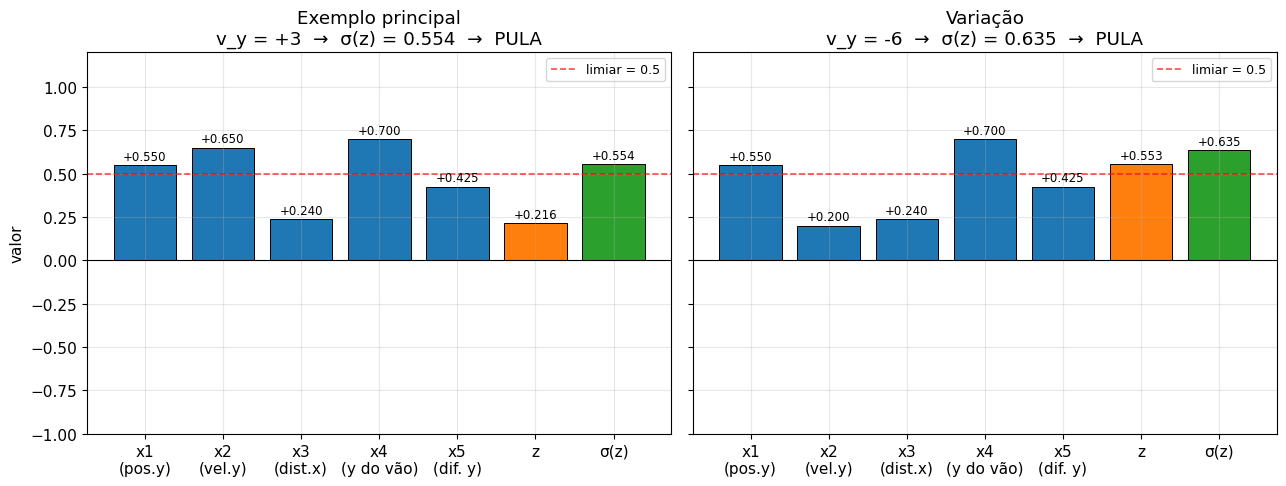

In [ ]:
# Simulação passo a passo de UMA decisão do pássaro (Seção B.6)
# Mostra: entradas normalizadas → z → σ(z) → decisão

def decidir(genoma, estado, H=400, W=500, v_max=10, verbose=False):
    """
    genoma = [w1, w2, w3, w4, w5, b]
    estado = dict com y, v_y, d_x, y_vao
    Devolve dict com entradas, z, sigma, decisão.
    """
    w1, w2, w3, w4, w5, b = genoma
    y, v_y, d_x, y_vao = estado['y'], estado['v_y'], estado['d_x'], estado['y_vao']

    # Normalização
    x1 = y / H
    x2 = (v_y + v_max) / (2 * v_max)
    x3 = d_x / W
    x4 = y_vao / H
    x5 = (y - y_vao + H) / (2 * H)

    # Soma ponderada
    parcelas = np.array([w1*x1, w2*x2, w3*x3, w4*x4, w5*x5])
    z = parcelas.sum() + b

    # Sigmoide e decisão
    p = sigmoid(z)
    decisao = p > 0.5

    if verbose:
        print("── Passo 1: normalização das entradas ──")
        for i, xi in enumerate([x1, x2, x3, x4, x5], 1):
            print(f"  x{i} = {xi:.4f}")
        print("\n── Passo 2: parcelas w_i·x_i ──")
        for i in range(5):
            print(f"  w{i+1}·x{i+1} = {genoma[i]:+.3f} × "
                  f"{[x1,x2,x3,x4,x5][i]:.4f} = {parcelas[i]:+.4f}")
        print(f"  bias b = {b:+.4f}")
        print(f"  z = soma = {z:+.4f}")
        print("\n── Passo 3: sigmoide ──")
        print(f"  -z = {-z:+.4f}")
        print(f"  e^(-z) = {np.exp(-z):.4f}")
        print(f"  1 + e^(-z) = {1 + np.exp(-z):.4f}")
        print(f"  σ(z) = 1 / (1+e^(-z)) = {p:.4f}")
        print("\n── Passo 4: decisão ──")
        print(f"  {p:.4f} > 0.5? → {'SIM' if decisao else 'NÃO'}")
        print(f"  → {'PULAR' if decisao else 'NÃO PULAR'}")

    return dict(x=[x1, x2, x3, x4, x5], parcelas=parcelas,
                z=z, sigma=p, decisao=decisao)


# ---- Execução do exemplo da Seção B.6 ----
genoma = [0.42, -0.75, 0.61, -0.14, 0.88, 0.05]
estado = {'y': 220, 'v_y': 3, 'd_x': 120, 'y_vao': 280}

print("=" * 55)
print("EXEMPLO PRINCIPAL (v_y = +3)")
print("=" * 55)
r = decidir(genoma, estado, verbose=True)

print("\n" + "=" * 55)
print("VARIAÇÃO (v_y = -6, em vez de +3)")
print("=" * 55)
estado_alt = dict(estado, v_y=-6)
r_alt = decidir(genoma, estado_alt, verbose=True)

# ---- Visualização lado a lado ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

rotulos = ['x1\n(pos.y)', 'x2\n(vel.y)', 'x3\n(dist.x)',
           'x4\n(y do vão)', 'x5\n(dif. y)', 'z', 'σ(z)']
valores_1 = r['x'] + [r['z'], r['sigma']]
valores_2 = r_alt['x'] + [r_alt['z'], r_alt['sigma']]

cores_1 = ['#1f77b4'] * 5 + ['#ff7f0e', '#2ca02c']
cores_2 = ['#1f77b4'] * 5 + ['#ff7f0e', '#2ca02c']

for ax, valores, cores, titulo, sub in [
    (ax1, valores_1, cores_1, 'Exemplo principal',
     f"v_y = +3  →  σ(z) = {r['sigma']:.3f}  →  "
     f"{'PULA' if r['decisao'] else 'NÃO PULA'}"),
    (ax2, valores_2, cores_2, 'Variação',
     f"v_y = -6  →  σ(z) = {r_alt['sigma']:.3f}  →  "
     f"{'PULA' if r_alt['decisao'] else 'NÃO PULA'}"),
]:
    bars = ax.bar(rotulos, valores, color=cores, edgecolor='black', linewidth=0.7)
    ax.axhline(0.5, color='red', linestyle='--', alpha=0.7, linewidth=1.2,
               label='limiar = 0.5')
    ax.axhline(0, color='black', linewidth=0.8)
    for b_, v in zip(bars, valores):
        offset = 0.03 if v >= 0 else -0.07
        ax.text(b_.get_x() + b_.get_width()/2, v + offset,
                f'{v:+.3f}', ha='center', fontsize=8.5)
    ax.set_title(f'{titulo}\n{sub}')
    ax.set_ylim(-1.0, 1.2)
    ax.legend(loc='upper right', fontsize=9)

ax1.set_ylabel('valor')
plt.tight_layout()
plt.show()

# PARTE C — FÍSICA DO JOGO

O cérebro do pássaro decide "pular" ou "não pular". Quem traduz isso em movimento é a física do jogo. Esta parte é sobre ela.

---

## C.1 Sistema de coordenadas da tela

**Em termos simples:** precisamos concordar onde é "cima" e "baixo" na tela do computador. Isso parece trivial mas é fonte de erros comuns.

### O padrão da web (canvas HTML)

- Origem $(0, 0)$ fica no **canto superior esquerdo**
- $x$ cresce para a **direita**
- $y$ cresce para **baixo**

Execute a célula de código a seguir para visualizar o sistema de coordenadas do canvas HTML, com um exemplo concreto de pássaro posicionado.

**Consequência:** quando o pássaro "cai" (vai para baixo), seu $y$ **aumenta**. Quando ele "sobe" (pula), seu $y$ **diminui**. Isso é o oposto da intuição matemática de gráfico, mas é o padrão de jogos.

### Constantes do jogo

| Constante | Significado | Valor de exemplo |
|-----------|-------------|-------------------|
| $H$ | Altura da tela | 400 pixels |
| $W$ | Largura da tela | 500 pixels |
| $y_{\min}$ | Menor y possível (topo) | 0 |
| $y_{\max}$ | Maior y possível (chão) | $H$ |

**Efeito prático:** se você programar a gravidade com sinal errado, o pássaro voa para cima eternamente. Precisa ter em mente: **y menor = mais alto; y maior = mais baixo**.

**Resumo da seção:** Tela do navegador tem origem no canto superior esquerdo. Eixo y cresce para baixo. Portanto, "cair" = aumentar y; "subir" = diminuir y. Esse é o padrão de jogos web.

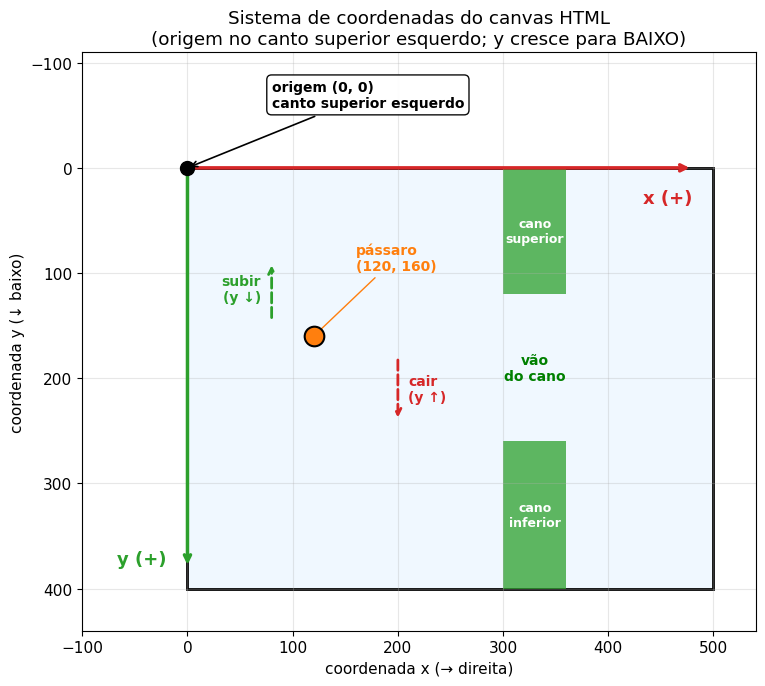

Resumo do sistema de coordenadas:
  Origem (0,0) = canto SUPERIOR ESQUERDO
  x cresce → direita
  y cresce ↓ para BAIXO
  Teto da tela: y = 0
  Chão da tela: y = H = 400


In [ ]:
# Diagrama do sistema de coordenadas do canvas HTML
# Versão corrigida: rótulos reposicionados para evitar sobreposição

H, W = 400, 500

fig, ax = plt.subplots(figsize=(9, 7))

# Fundo da "tela"
ax.add_patch(plt.Rectangle((0, 0), W, H, facecolor='#f0f8ff',
                           edgecolor='black', linewidth=2))

# Eixos com setas
ax.annotate('', xy=(W - 20, 0), xytext=(0, 0),
            arrowprops=dict(arrowstyle='->', color='#d62728', linewidth=2.5))
ax.annotate('', xy=(0, H - 20), xytext=(0, 0),
            arrowprops=dict(arrowstyle='->', color='#2ca02c', linewidth=2.5))

# Labels dos eixos — dentro do canvas, longe da origem
ax.text(W - 20, 20, 'x (+)', color='#d62728', fontsize=13,
        fontweight='bold', ha='right', va='top')
ax.text(-20, H - 20, 'y (+)', color='#2ca02c', fontsize=13,
        fontweight='bold', ha='right', va='bottom')

# Origem — ponto no canto, rótulo ACIMA do canvas com seta
ax.scatter([0], [0], color='black', s=100, zorder=5)
ax.annotate('origem (0, 0)\ncanto superior esquerdo',
            xy=(0, 0), xytext=(80, -55),
            arrowprops=dict(arrowstyle='->', color='black', linewidth=1.2),
            fontsize=10, fontweight='bold', color='black',
            ha='left', va='bottom',
            bbox=dict(boxstyle='round,pad=0.35', facecolor='white',
                      edgecolor='black', alpha=0.95))

# Pássaro — posicionado afastado da origem e da área dos rótulos
px, py = 120, 160
ax.scatter([px], [py], s=200, color='#ff7f0e', zorder=6,
           edgecolor='black', linewidth=1.5)
ax.annotate(f'pássaro\n({px}, {py})',
            xy=(px, py), xytext=(px + 40, py - 60),
            arrowprops=dict(arrowstyle='->', color='#ff7f0e'),
            fontsize=10, color='#ff7f0e', fontweight='bold',
            ha='left', va='bottom')

# Cano de exemplo
x_cano = 300
ax.add_patch(plt.Rectangle((x_cano, 0), 60, 120,
                           facecolor='#2ca02c', alpha=0.75))
ax.add_patch(plt.Rectangle((x_cano, 260), 60, 140,
                           facecolor='#2ca02c', alpha=0.75))
ax.text(x_cano + 30, 60, 'cano\nsuperior', fontsize=9,
        ha='center', va='center', color='white', fontweight='bold')
ax.text(x_cano + 30, 190, 'vão\ndo cano', fontsize=10,
        ha='center', va='center', color='green', fontweight='bold')
ax.text(x_cano + 30, 330, 'cano\ninferior', fontsize=9,
        ha='center', va='center', color='white', fontweight='bold')

# Seta "cair" — à DIREITA do pássaro, apontando para baixo (y crescente)
ax.annotate('', xy=(px + 80, py + 80), xytext=(px + 80, py + 20),
            arrowprops=dict(arrowstyle='->', color='#d62728',
                            linewidth=2, lw=2, ls='--'))
ax.text(px + 90, py + 50, 'cair\n(y ↑)', fontsize=10,
        color='#d62728', fontweight='bold', va='center', ha='left')

# Seta "subir" — à ESQUERDA do pássaro, apontando para cima (y decrescente)
ax.annotate('', xy=(px - 40, py - 70), xytext=(px - 40, py - 15),
            arrowprops=dict(arrowstyle='->', color='#2ca02c',
                            linewidth=2, lw=2, ls='--'))
ax.text(px - 50, py - 45, 'subir\n(y ↓)', fontsize=10,
        color='#2ca02c', fontweight='bold', va='center', ha='right')

ax.set_xlim(-100, W + 40)
ax.set_ylim(H + 40, -110)
ax.set_aspect('equal')
ax.set_xlabel('coordenada x (→ direita)')
ax.set_ylabel('coordenada y (↓ baixo)')
ax.set_title('Sistema de coordenadas do canvas HTML\n'
             '(origem no canto superior esquerdo; y cresce para BAIXO)')
plt.tight_layout()
plt.show()

print("Resumo do sistema de coordenadas:")
print(f"  Origem (0,0) = canto SUPERIOR ESQUERDO")
print(f"  x cresce → direita")
print(f"  y cresce ↓ para BAIXO")
print(f"  Teto da tela: y = 0")
print(f"  Chão da tela: y = H = {H}")

## C.2 Equações de movimento (velocidade, posição, gravidade, pulo)

**Em termos simples:** a cada frame, atualizamos a velocidade (pela gravidade ou pelo pulo) e depois atualizamos a posição (pela velocidade). É simulação simples de movimento.

### As equações

Velocidade no próximo frame:

$$
v_y(t+1) = v_y(t) + a
$$

Posição no próximo frame:

$$
y(t+1) = y(t) + v_y(t+1)
$$

Se o pássaro pula:

$$
v_y(t+1) = -v_{\text{salto}}
$$

### Cada símbolo

| Símbolo | Significado |
|---------|-------------|
| $t$ | Frame atual (índice de tempo discreto) |
| $t+1$ | Próximo frame |
| $v_y(t)$ | Velocidade vertical no frame $t$ |
| $a$ | Aceleração da gravidade (constante positiva, ex.: 0.4) |
| $y(t)$ | Posição vertical no frame $t$ |
| $v_{\text{salto}}$ | Velocidade do pulo (constante positiva, ex.: 7) |
| $-v_{\text{salto}}$ | Negativo porque pular é subir, e subir é y diminuir |

### Ordem dos passos (importante!)

A cada frame, na ordem:

1. Aplicar gravidade: $v_y \leftarrow v_y + a$
2. Se o pássaro decidiu pular: $v_y \leftarrow -v_{\text{salto}}$ (sobrescreve)
3. Atualizar posição: $y \leftarrow y + v_y$

**A ordem importa.** Se atualizar a posição antes da gravidade, o comportamento muda. A ordem acima é a padrão.

### Exemplo numérico — Seção C.2

**Entrada:**
- $a = 0.4$
- $v_{\text{salto}} = 7$
- Estado inicial: $y(0) = 200$, $v_y(0) = 0$
- Decisões: frame 1 = pular, frames 2–5 = não pular

**Frame 1:**
- $v_y = 0 + 0.4 = 0.4$ (gravidade)
- pulou? SIM → $v_y = -7$
- $y = 200 + (-7) = 193$

**Frame 2:**
- $v_y = -7 + 0.4 = -6.6$
- pulou? NÃO
- $y = 193 + (-6.6) = 186.4$

**Frame 3:**
- $v_y = -6.6 + 0.4 = -6.2$
- pulou? NÃO
- $y = 186.4 - 6.2 = 180.2$

**Frame 4:**
- $v_y = -6.2 + 0.4 = -5.8$
- pulou? NÃO
- $y = 180.2 - 5.8 = 174.4$

**Frame 5:**
- $v_y = -5.8 + 0.4 = -5.4$
- pulou? NÃO
- $y = 174.4 - 5.4 = 169.0$

**Resultado:** pássaro subiu de 200 até 169 em 5 frames.

**Se $v_{\text{salto}}$ fosse 5 em vez de 7:**

- Frame 1: $v_y = -5$, $y = 195$
- Frame 2: $v_y = -4.6$, $y = 190.4$
- Frame 3: $v_y = -4.2$, $y = 186.2$
- Frame 4: $v_y = -3.8$, $y = 182.4$
- Frame 5: $v_y = -3.4$, $y = 179.0$

Pulo mais fraco → sobe menos.

**Efeito prático:**
- **Aumentar $a$** → gravidade mais forte → pássaro cai mais rápido → precisa pular mais.
- **Diminuir $a$** → jogo mais fácil.
- **Aumentar $v_{\text{salto}}$** → pulos mais altos.
- **Diminuir $v_{\text{salto}}$** → pulos mais fracos.

**Resumo da seção:** Física é: aplicar gravidade → aplicar pulo (se decidido) → mover. Duas equações, ordem bem definida. y menor = mais alto. Simples, mas é a base de todo o movimento.

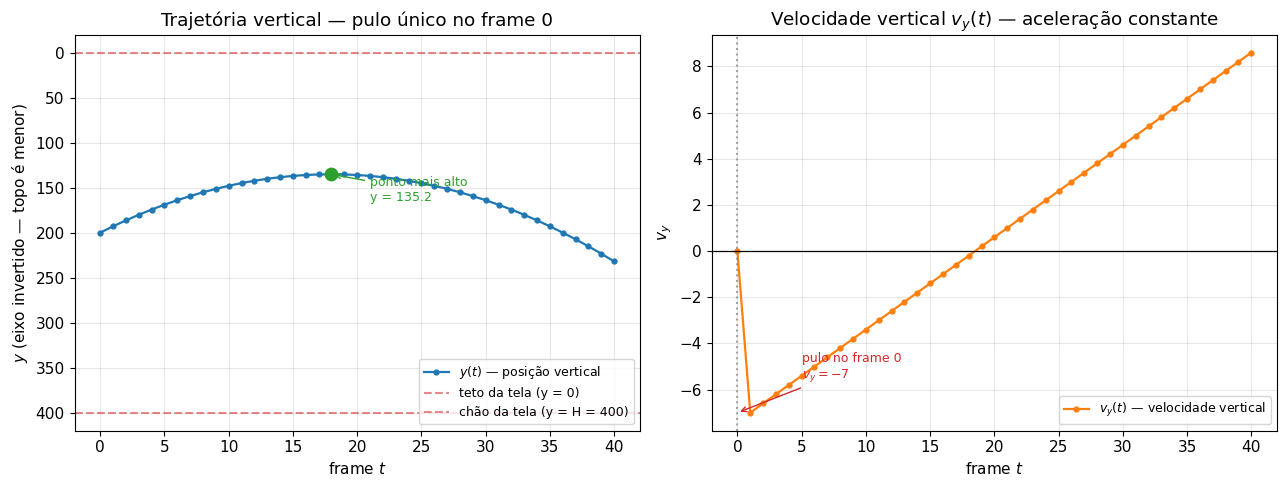

Primeiros 6 frames (t, y, v_y):
  t= 0  y= 200.00  v_y=  +0.00
  t= 1  y= 193.00  v_y=  -7.00
  t= 2  y= 186.40  v_y=  -6.60
  t= 3  y= 180.20  v_y=  -6.20
  t= 4  y= 174.40  v_y=  -5.80
  t= 5  y= 169.00  v_y=  -5.40


In [ ]:
# Trajetória vertical e velocidade vertical ao longo de 40 frames
# Simula um único pulo no frame 0, seguido de queda livre
#
# CORREÇÃO: v_salto e a agora são variáveis globais (definidas antes),
# para que possam ser usadas nas anotações fora da função.

# Parâmetros globais (usados tanto no cálculo quanto nos rótulos dos gráficos)
a_grav = 0.4
v_salto = 7
y0 = 200
n_frames = 40


def simular_trajetoria(a=a_grav, vs=v_salto, y0=y0, n=n_frames,
                       decisao=lambda t: t == 0):
    """Retorna arrays de y(t) e v_y(t)."""
    ys, vs_list = [y0], [0.0]
    for t in range(n):
        v_next = vs_list[-1] + a
        if decisao(t):
            v_next = -vs
        y_next = ys[-1] + v_next
        vs_list.append(v_next)
        ys.append(y_next)
    return np.array(ys), np.array(vs_list)


y, v = simular_trajetoria()
frames = np.arange(len(y))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# --- (1) Posição vertical ---
ax1.plot(frames, y, marker='o', markersize=3.5,
         color='#1f77b4', linewidth=1.6, label='$y(t)$ — posição vertical')
ax1.axhline(0, color='#d62728', linestyle='--', alpha=0.55,
            label='teto da tela (y = 0)')
ax1.axhline(400, color='#d62728', linestyle='--', alpha=0.55,
            label='chão da tela (y = H = 400)')
ax1.invert_yaxis()
ax1.set_title('Trajetória vertical — pulo único no frame 0')
ax1.set_xlabel('frame $t$')
ax1.set_ylabel('$y$ (eixo invertido — topo é menor)')
ax1.legend(loc='lower right', fontsize=9)
ax1.grid(alpha=0.3)

# Marca o vértice (y mínimo) com uma anotação
i_min = np.argmin(y)
ax1.scatter([frames[i_min]], [y[i_min]], color='#2ca02c', s=80, zorder=5)
ax1.annotate(f'ponto mais alto\ny = {y[i_min]:.1f}',
             xy=(frames[i_min], y[i_min]),
             xytext=(frames[i_min] + 3, y[i_min] + 30),
             arrowprops=dict(arrowstyle='->', color='#2ca02c'),
             fontsize=9, color='#2ca02c')

# --- (2) Velocidade vertical ---
ax2.plot(frames, v, marker='o', markersize=3.5,
         color='#ff7f0e', linewidth=1.6,
         label='$v_y(t)$ — velocidade vertical')
ax2.axhline(0, color='black', linewidth=0.9)
ax2.axvline(0, color='gray', linestyle=':', alpha=0.7)
# CORREÇÃO: usa a variável global v_salto, que agora existe fora da função
ax2.annotate(f'pulo no frame 0\n$v_y = {-v_salto:+.0f}$',
             xy=(0, -v_salto), xytext=(5, -v_salto + 1.5),
             arrowprops=dict(arrowstyle='->', color='#d62728'),
             fontsize=9, color='#d62728')
ax2.set_title('Velocidade vertical $v_y(t)$ — aceleração constante')
ax2.set_xlabel('frame $t$')
ax2.set_ylabel('$v_y$')
ax2.legend(loc='lower right', fontsize=9)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Impressão numérica dos primeiros 5 frames para reforçar a seção C.2
print("Primeiros 6 frames (t, y, v_y):")
for i in range(6):
    print(f"  t={frames[i]:>2}  y={y[i]:7.2f}  v_y={v[i]:+7.2f}")

## C.3 Detecção de colisão

**Em termos simples:** verificamos a cada frame se o pássaro bateu em algo. Se bateu, ele morre.

### As regras de colisão

O pássaro morre se qualquer uma dessas condições for verdadeira:

$$
y < 0
$$

$$
y > H - h_{\text{pássaro}}
$$

$$
\text{colidiu com cano}
$$

### Cada símbolo

| Símbolo | Significado |
|---------|-------------|
| $y$ | Posição vertical do topo do pássaro |
| $H$ | Altura da tela |
| $h_{\text{pássaro}}$ | Altura do pássaro em pixels |
| colidiu com cano | Verificação de sobreposição retangular |

### Colisão com cano (simplificada)

Um cano tem duas partes: **superior** e **inferior**, com um vão no meio. O pássaro colide se:

$$
(x_p + w_p > x_c) \;\text{e}\; (x_p < x_c + w_c) \;\text{e}\; (y_p < y_{\text{vão,sup}} \;\text{ou}\; y_p + h_p > y_{\text{vão,inf}})
$$

Onde:

- $x_p, y_p$ = posição do pássaro
- $w_p, h_p$ = largura e altura do pássaro
- $x_c, w_c$ = posição e largura do cano
- $y_{\text{vão,sup}}$ = altura do **final** da parte superior do cano (limite superior do vão)
- $y_{\text{vão,inf}}$ = altura do **início** da parte inferior do cano (limite inferior do vão)

**Leitura em linguagem coloquial:** o pássaro colide se ele está horizontalmente dentro do cano **E** verticalmente acima do vão ou abaixo do vão.

### Exemplo numérico — Seção C.3

**Entrada:**
- pássaro: $x_p = 100$, $y_p = 220$, $w_p = 30$, $h_p = 20$
- cano: $x_c = 120$, $w_c = 50$
- vão: $y_{\text{vão,sup}} = 200$, $y_{\text{vão,inf}} = 320$

**Passo 1:** $x_p + w_p = 130 > x_c = 120$? → SIM

**Passo 2:** $x_p = 100 < x_c + w_c = 170$? → SIM

**Passo 3:** $y_p = 220 < y_{\text{vão,sup}} = 200$? → NÃO

**Passo 4:** $y_p + h_p = 240 > y_{\text{vão,inf}} = 320$? → NÃO

**Resultado:** não colidiu (está dentro do vão horizontal e verticalmente).

**Se $y_p$ fosse 180 em vez de 220:**

**Passo 3:** $180 < 200$? → SIM

**Resultado:** **COLISÃO** (pássaro acima do vão, bateu na parte superior do cano).

**Efeito prático:**
- Aumentar o vão → jogo mais fácil.
- Diminuir o vão → mais difícil.

**Resumo da seção:** Colisão = verificar se o pássaro está fora da tela (y < 0 ou y > H) ou sobreposto ao retângulo do cano. Se sim, o pássaro morre. É só checagem de retângulos.

## C.4 Exemplo numérico: simular 5 frames passo a passo com valores concretos

**Em termos simples:** vamos rodar o jogo em câmera lenta, mostrando o que acontece a cada frame — física, decisão do pássaro, resultado.

### Setup

- $a = 0.4$, $v_{\text{salto}} = 7$
- $H = 400$, $W = 500$
- Genoma: $g = [0.42, -0.75, 0.61, -0.14, 0.88, 0.05]$
- Estado inicial:
  - $y(0) = 200$, $v_y(0) = 0$
  - $d_x = 200$, $y_{\text{vão}} = 280$
- Nenhum cano na colisão nos primeiros 5 frames (para simplificar)

### Frame 0 (estado inicial)

$$
y = 200, \quad v_y = 0
$$

### Frame 1

**Decisão:**
- $x_1 = 200/400 = 0.500$
- $x_2 = (0+10)/20 = 0.500$
- $x_3 = 200/500 = 0.400$
- $x_4 = 280/400 = 0.700$
- $x_5 = (200-280+400)/800 = 0.400$
- $z = 0.42 \cdot 0.5 + (-0.75) \cdot 0.5 + 0.61 \cdot 0.4 + (-0.14) \cdot 0.7 + 0.88 \cdot 0.4 + 0.05$
- $z = 0.21 - 0.375 + 0.244 - 0.098 + 0.352 + 0.05 = 0.383$
- $\sigma(0.383) \approx 0.594 > 0.5$ → **PULA**

**Física:**
- $v_y = 0 + 0.4 = 0.4$
- pulou: $v_y = -7$
- $y = 200 + (-7) = 193$

### Frame 2

**Decisão:**
- $x_1 = 193/400 = 0.4825$
- $x_2 = (-7+10)/20 = 0.150$
- $x_3 \approx 0.400$ (supondo mesmo $d_x$)
- $x_4 = 0.700$
- $x_5 = (193-280+400)/800 = 0.391$
- $z = 0.42 \cdot 0.4825 - 0.75 \cdot 0.150 + 0.61 \cdot 0.400 - 0.14 \cdot 0.700 + 0.88 \cdot 0.391 + 0.05$
- $z = 0.2027 - 0.1125 + 0.244 - 0.098 + 0.344 + 0.05 = 0.630$
- $\sigma(0.630) \approx 0.652 > 0.5$ → **PULA**

**Física:**
- $v_y = -7 + 0.4 = -6.6$
- pulou: $v_y = -7$ (sobrescreve)
- $y = 193 + (-7) = 186$

### Frame 3

**Decisão:**
- $x_1 = 186/400 = 0.465$
- $x_2 = (-7+10)/20 = 0.150$
- $x_5 = (186-280+400)/800 = 0.3825$
- $z = 0.42 \cdot 0.465 - 0.75 \cdot 0.150 + 0.244 - 0.098 + 0.88 \cdot 0.3825 + 0.05$
- $z = 0.1953 - 0.1125 + 0.244 - 0.098 + 0.3366 + 0.05 = 0.615$
- $\sigma \approx 0.649 > 0.5$ → **PULA**

**Física:**
- $v_y = -7 + 0.4 = -6.6$
- pulou: $v_y = -7$
- $y = 186 + (-7) = 179$

### Frame 4

**Decisão:**
- $x_1 = 179/400 = 0.4475$
- $x_5 = (179-280+400)/800 = 0.374$
- $z = 0.42 \cdot 0.4475 - 0.1125 + 0.244 - 0.098 + 0.88 \cdot 0.374 + 0.05$
- $z = 0.188 - 0.1125 + 0.244 - 0.098 + 0.329 + 0.05 = 0.6005$
- $\sigma \approx 0.646 > 0.5$ → **PULA**

**Física:**
- $v_y = -7$, $y = 179 - 7 = 172$

### Frame 5

**Decisão:**
- $x_1 = 172/400 = 0.430$
- $x_5 = (172-280+400)/800 = 0.365$
- $z = 0.42 \cdot 0.430 - 0.1125 + 0.244 - 0.098 + 0.88 \cdot 0.365 + 0.05$
- $z = 0.1806 - 0.1125 + 0.244 - 0.098 + 0.3212 + 0.05 = 0.585$
- $\sigma \approx 0.642 > 0.5$ → **PULA**

**Física:**
- $v_y = -7$, $y = 172 - 7 = 165$

### Observação crítica

Esse genoma **pula em todos os frames**, o que é ruim: ele subirá sem parar, baterá no topo da tela e morrerá. Esse é justamente o tipo de comportamento que **a evolução vai corrigir**: pássaros que pulam obsessivamente têm fitness baixa (morrem rápido) e não se reproduzem. Pássaros que pulam na hora certa sobem na hierarquia.

**Efeito prático:**
- Esse exemplo mostra que genomas aleatórios frequentemente geram comportamento ruim.
- É exatamente o que queremos: começar ruim para depois melhorar.

**Resumo da seção:** Rodar um pássaro passo a passo ilustra como genoma + física + decisão se combinam. Genomas aleatórios frequentemente geram comportamento ruim (pular sempre, nunca pular). O GA vai selecionar os que pulam na hora certa.

Tabela frame a frame do exemplo da seção C.4:
 frame     y  v_y     z  sigma decisao
     0 200.0  0.0 0.383  0.595    PULA
     1 193.0 -7.0 0.630  0.653    PULA
     2 186.0 -7.0 0.615  0.649    PULA
     3 179.0 -7.0 0.600  0.646    PULA
     4 172.0 -7.0 0.585  0.642    PULA
     5 165.0 -7.0 0.570  0.639    PULA


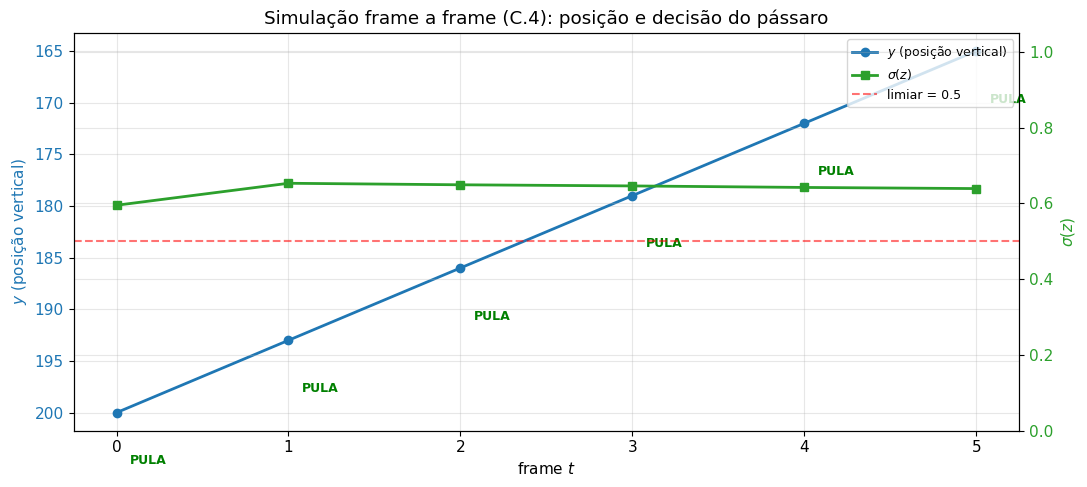

In [ ]:
# Simulação frame a frame dos 5 frames do exemplo da seção C.4.
# Depende da função decidir() da célula 21. Se não existir, redefine.

if 'decidir' not in globals():
    def decidir(genoma, estado, H=400, W=500, v_max=10):
        w1, w2, w3, w4, w5, b = genoma
        y, v_y, d_x, y_vao = (estado['y'], estado['v_y'],
                              estado['d_x'], estado['y_vao'])
        x1 = y / H
        x2 = (v_y + v_max) / (2 * v_max)
        x3 = d_x / W
        x4 = y_vao / H
        x5 = (y - y_vao + H) / (2 * H)
        z = w1*x1 + w2*x2 + w3*x3 + w4*x4 + w5*x5 + b
        p = 1.0 / (1.0 + np.exp(-z))
        return dict(x=[x1, x2, x3, x4, x5], z=z, sigma=p, decisao=p > 0.5)


genoma = [0.42, -0.75, 0.61, -0.14, 0.88, 0.05]
a, v_salto, H, W, v_max = 0.4, 7, 400, 500, 10
y, v_y = 200.0, 0.0
d_x_base, y_vao = 200, 280
historico = []

for t in range(6):  # frames 0 a 5
    estado = {'y': y, 'v_y': v_y, 'd_x': d_x_base, 'y_vao': y_vao}
    r = decidir(genoma, estado, H=H, W=W, v_max=v_max)
    historico.append({
        'frame': t, 'y': round(y, 2), 'v_y': round(v_y, 2),
        'z': round(r['z'], 3), 'sigma': round(r['sigma'], 3),
        'decisao': 'PULA' if r['decisao'] else 'NÃO PULA',
    })
    # Física (ordem: gravidade → pulo → posição)
    v_y = v_y + a
    if r['decisao']:
        v_y = -v_salto
    y = y + v_y


df = pd.DataFrame(historico)
print("Tabela frame a frame do exemplo da seção C.4:")
print(df.to_string(index=False))


# ---- Gráfico: y e σ(z) no mesmo eixo de frames ----
fig, ax1 = plt.subplots(figsize=(11, 5))

# Eixo esquerdo: posição y (invertido)
ax1.plot(df['frame'], df['y'], marker='o', markersize=6,
         color='#1f77b4', linewidth=2, label='$y$ (posição vertical)')
ax1.set_xlabel('frame $t$')
ax1.set_ylabel('$y$ (posição vertical)', color='#1f77b4')
ax1.tick_params(axis='y', labelcolor='#1f77b4')
ax1.invert_yaxis()
ax1.grid(alpha=0.3)

# Eixo direito: σ(z)
ax2 = ax1.twinx()
ax2.plot(df['frame'], df['sigma'], marker='s', markersize=6,
         color='#2ca02c', linewidth=2, label=r'$\sigma(z)$')
ax2.axhline(0.5, color='red', linestyle='--', alpha=0.55,
            label='limiar = 0.5')
ax2.set_ylabel(r'$\sigma(z)$', color='#2ca02c')
ax2.tick_params(axis='y', labelcolor='#2ca02c')
ax2.set_ylim(0, 1.05)

# Marca "PULA" sobre cada frame em que a decisão foi pular
for _, row in df.iterrows():
    if row['decisao'] == 'PULA':
        ax1.annotate('PULA', xy=(row['frame'], row['y']),
                     xytext=(row['frame'] + 0.08, row['y'] + 5),
                     fontsize=9, color='green', fontweight='bold')

# Legenda combinada dos dois eixos
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right', fontsize=9)

ax1.set_title('Simulação frame a frame (C.4): posição e decisão do pássaro')
plt.tight_layout()
plt.show()

# PARTE D — FITNESS

Agora que o pássaro joga, precisamos medir o quão bem ele jogou. Essa medida é o fitness — o coração de todo o GA.

---

## D.1 O que é fitness e por que é o coração do GA

**Em termos simples:** fitness é a "nota" de cada pássaro. É o único critério que a evolução conhece para decidir quem reproduz e quem morre.

### A analogia

Pense num vestibular. Milhares de candidatos fazem a prova. Quem tira nota alta entra; quem tira nota baixa não. A "nota" é o fitness. O GA faz igual: cada pássaro faz sua "prova" (jogar Flappy Bird) e recebe uma nota (fitness). Só os com nota alta viram pais.

### Sem fitness, sem evolução

Se todos os pássaros tivessem fitness igual, todos teriam a mesma chance de reproduzir. Aí os filhos seriam misturas aleatórias de qualquer um — não haveria pressão nenhuma para melhorar. Depois de 100 gerações, a população estaria tão boa quanto no início. **Fitness é o que dá direção à evolução.**

### Características de uma boa fitness

| Característica | Explicação |
|----------------|-----------|
| **Discrimina bem** | Pássaros bons devem ter fitness claramente maior que ruins |
| **Correlaciona com o objetivo** | Se queremos pássaros que sobrevivam mais, fitness deve medir sobrevivência |
| **Não é trivial de maximizar** | Se a fitness for "número de vezes que piscou", o GA encontra pássaros que piscam muito e nada mais |

### Exemplo numérico — Seção D.1

**Entrada:** 3 pássaros jogaram

- Pássaro A: 5 canos, 300 frames vivo
- Pássaro B: 12 canos, 800 frames vivo
- Pássaro C: 0 canos, 50 frames vivo

**Passo 1:** definir fitness (próximas seções)

**Passo 2:** calcular para cada

**Passo 3:** ordenar

**Resultado hipotético:** A = 500, B = 1200, C = 50

B é claramente o melhor; C é o pior.

**Se todos tivessem fitness = 500:** nenhuma pressão evolutiva → seleção seria aleatória → GA não funciona.

**Efeito prático:** escolha mal a fitness, e o GA otimiza a coisa errada. É a decisão mais importante do projeto.

**Resumo da seção:** Fitness é a nota do pássaro. Sem ela, o GA não tem direção. Precisa discriminar bem, correlacionar com o objetivo real, e não ser trivial de maximizar. É o critério que orienta toda a evolução.

## D.2 Fórmula principal e justificativa de cada parcela

**Em termos simples:** nossa fitness vai valorizar principalmente canos ultrapassados (o objetivo real do jogo), com a distância como desempate.

### A fórmula

$$
f(g) = 100 \cdot c + d
$$

### Cada símbolo

| Símbolo | Significado |
|---------|-------------|
| $f(g)$ | Fitness do genoma $g$ |
| $c$ | Número de canos ultrapassados |
| $d$ | Distância horizontal percorrida (em pixels) |
| $100$ | Peso (multiplicador) dos canos |

### Por que 100

Cada cano ultrapassado vale **muito mais** que percorrer 1 pixel. Se o peso fosse $1$, dois pássaros com a mesma distância mas canos diferentes teriam fitness quase igual — o que é errado. Multiplicando por $100$, garantimos que ultrapassar canos domina o fitness.

**Alternativa:** poderíamos usar $1000$ ou $500$. O importante é que canos $\gg$ distância em termos de impacto.

### Por que somar distância

Serve como **desempate**: dois pássaros que ultrapassaram o mesmo número de canos serão comparados por quem sobreviveu mais tempo (mais distância = mais frames vivos). Sem isso, muitos pássaros empatariam e a evolução perderia direção em empates.

### Exemplo numérico — Seção D.2

**Entrada:**
- Pássaro A: $c = 5$, $d = 3000$
- Pássaro B: $c = 12$, $d = 8000$
- Pássaro C: $c = 0$, $d = 500$

**Passo 1:** $f(A) = 100 \cdot 5 + 3000 = 500 + 3000 = 3500$

**Passo 2:** $f(B) = 100 \cdot 12 + 8000 = 1200 + 8000 = 9200$

**Passo 3:** $f(C) = 100 \cdot 0 + 500 = 0 + 500 = 500$

**Resultado:** $B (9200) > A (3500) > C (500)$.

**Se $c$ da A fosse $10$ em vez de $5$:** $f(A) = 100 \cdot 10 + 3000 = 4000$ → A melhora mas ainda abaixo de B.

**Efeito prático:**
- **Aumentar** o peso dos canos (ex.: 1000) → GA prioriza passar canos ainda mais.
- **Diminuir** (ex.: 50) → distância ganha mais peso relativo.
- **Não recomendado:** deixar peso $= 1$ (distância domina, canos se tornam irrelevantes).

**Resumo da seção:** Fitness = 100 × canos + distância. Canos dominam (objetivo real do jogo), distância desempata (quem viveu mais). Peso 100 é razoável; nem tão baixo (distância domina) nem tão alto (fitness explode).

## D.3 Fórmula alternativa com penalidade

**Em termos simples:** versão mais sofisticada que penaliza comportamentos ruins e recompensa tempo vivo.

### A fórmula

$$
f(g) = 100 \cdot c + t - 5 \cdot k
$$

### Cada símbolo

| Símbolo | Significado |
|---------|-------------|
| $c$ | Canos ultrapassados |
| $t$ | Tempo vivo (em frames) |
| $k$ | Número de "colisões" ou "quase-colisões" |
| $5$ | Peso da penalidade |

### Por que penalizar

Se um pássaro fica batendo no teto e sobrevive "raspando", a fórmula principal pode dar fitness alta. A penalidade desencoraja isso, incentivando comportamento mais estável.

### Exemplo numérico — Seção D.3

**Entrada:**
- Pássaro A: $c = 5$, $t = 3000$, $k = 10$
- Pássaro B: $c = 5$, $t = 3000$, $k = 1$

**Passo 1:** $f(A) = 500 + 3000 - 50 = 3450$

**Passo 2:** $f(B) = 500 + 3000 - 5 = 3495$

**Resultado:** $B (3495) > A (3450)$.

B é preferido porque "raspou" menos.

**Se $k$ de A fosse $0$ em vez de $10$:** $f(A) = 500 + 3000 - 0 = 3500$ → A e B empatados no topo.

**Efeito prático:**
- **Aumentar o peso da penalidade** → GA seleciona pássaros mais estáveis (podem demorar a convergir mas ficam mais "limpos").
- **Diminuir** → GA aceita comportamentos "raspando".

**Resumo da seção:** Fórmula alternativa soma tempo vivo e subtrai penalidade por colisões. Produz comportamentos mais estáveis mas é mais complexa. Para iniciante, fique na fórmula principal da D.2.

## D.4 Normalização do fitness em probabilidade (com exemplo)

**Em termos simples:** transformamos fitness em probabilidade de ser escolhido. Fitness alta → probabilidade alta. A soma das probabilidades dá 1.

### A fórmula

$$
p_i = \frac{f(g_i)}{\sum_{j=1}^{N} f(g_j)}
$$

### Cada símbolo

| Símbolo | Significado |
|---------|-------------|
| $p_i$ | Probabilidade de o pássaro $i$ ser escolhido |
| $f(g_i)$ | Fitness do pássaro $i$ |
| $\sum_{j=1}^{N} f(g_j)$ | Soma das fitness de todos os $N$ pássaros |
| $N$ | Tamanho da população |

### Leitura

Cada $p_i$ é a fração do fitness total que o pássaro $i$ contribui. Se ele é 10% da fitness somada, ele tem 10% de chance de ser escolhido.

### Propriedade importante

$$
\sum_{i=1}^{N} p_i = 1
$$

A soma de todas as probabilidades sempre dá 1. Isso é o que se espera de uma distribuição de probabilidade.

### Exemplo numérico — Seção D.4

**Entrada:** fitness de 4 pássaros

- $f(A) = 3500$
- $f(B) = 9200$
- $f(C) = 500$
- $f(D) = 1800$

**Passo 1:** soma $= 3500 + 9200 + 500 + 1800 = 15000$

**Passo 2:** $p(A) = 3500 / 15000 = 0.2333$ (23.33%)

**Passo 3:** $p(B) = 9200 / 15000 = 0.6133$ (61.33%)

**Passo 4:** $p(C) = 500 / 15000 = 0.0333$ (3.33%)

**Passo 5:** $p(D) = 1800 / 15000 = 0.1200$ (12.00%)

**Passo 6:** verificar soma $= 0.2333 + 0.6133 + 0.0333 + 0.1200 = 1.000$

**Resultado:** B domina (61% de chance); C quase nunca é escolhido.

**Se $f(C)$ fosse $2000$ (em vez de $500$):** $p(C) = 2000 / 16500 = 0.1212$ → quase 4× mais chance.

**Efeito prático:**
- **Fitness muito desiguais** → os melhores concentram a probabilidade → alta pressão seletiva.
- **Fitness parecidas** → probabilidades parecidas → baixa pressão seletiva.

**Cuidado:** se um pássaro tem fitness 1000× maior que os outros, ele domina a roleta. Isso pode causar **convergência prematura** — todos os filhos ficam iguais a ele, e a evolução para. É por isso que às vezes se usa torneio em vez de roleta (próxima seção).

**Resumo da seção:** Normalizar = dividir cada fitness pela soma. Resultado são probabilidades que somam 1. Usado na seleção por roleta. Fitness muito desiguais causam pressão forte e podem travar a evolução.

## D.5 Exemplo numérico: 5 pássaros, calcular fitness de cada um e a probabilidade de cada um

**Em termos simples:** rodamos o cenário completo com 5 pássaros fictícios, calculando tudo.

### Dados brutos

| Pássaro | Canos ($c$) | Distância ($d$) |
|---------|---------------|--------------------|
| 1 | 3 | 1500 |
| 2 | 8 | 4000 |
| 3 | 12 | 6000 |
| 4 | 0 | 300 |
| 5 | 6 | 2800 |

### Passo 1 — Calcular fitness

$$
\begin{aligned}
f(1) &= 100 \cdot 3 + 1500 = 300 + 1500 = 1800 \\
f(2) &= 100 \cdot 8 + 4000 = 800 + 4000 = 4800 \\
f(3) &= 100 \cdot 12 + 6000 = 1200 + 6000 = 7200 \\
f(4) &= 100 \cdot 0 + 300 = 300 \\
f(5) &= 100 \cdot 6 + 2800 = 600 + 2800 = 3400
\end{aligned}
$$

### Passo 2 — Ordenar do melhor para o pior

$$
\begin{aligned}
1º&: \text{Pássaro 3} \;(7200) \\
2º&: \text{Pássaro 2} \;(4800) \\
3º&: \text{Pássaro 5} \;(3400) \\
4º&: \text{Pássaro 1} \;(1800) \\
5º&: \text{Pássaro 4} \;(300)
\end{aligned}
$$

### Passo 3 — Somar e calcular probabilidades

$$
\text{Soma} = 7200 + 4800 + 3400 + 1800 + 300 = 17500
$$

$$
\begin{aligned}
p(3) &= 7200 / 17500 \approx 0.4114 \;(41.14\%) \\
p(2) &= 4800 / 17500 \approx 0.2743 \;(27.43\%) \\
p(5) &= 3400 / 17500 \approx 0.1943 \;(19.43\%) \\
p(1) &= 1800 / 17500 \approx 0.1029 \;(10.29\%) \\
p(4) &= 300 / 17500 \approx 0.0171 \;(1.71\%)
\end{aligned}
$$

**Verificação:** soma $= 1.0000$ ✓

### Passo 4 — Interpretar

- Se escolhermos 100 pais por roleta, o pássaro 3 será escolhido ~41 vezes, o 2 ~27, etc.
- O pássaro 4 (pior) tem chance pequena mas não zero → **diversidade preservada**.
- Se o pássaro 3 fosse escolhido com probabilidade 1.0, o pássaro 4 nunca reproduziria → população colapsaria para descendentes de 3 apenas.

**Efeito prático:** a roleta mantém diversidade, mas se a diferença de fitness é gigante (pior fitness $= 1$, melhor $= 1000000$), o pior nunca é escolhido. Aí entra a decisão de usar torneio em vez de roleta.

**Resumo da seção:** 5 pássaros, fitness calculadas, ordenadas, probabilidades proporcionais. O melhor tem ~41% de chance, o pior ~2%. Verificação: soma = 1. Esse é o insumo para a seleção por roleta.

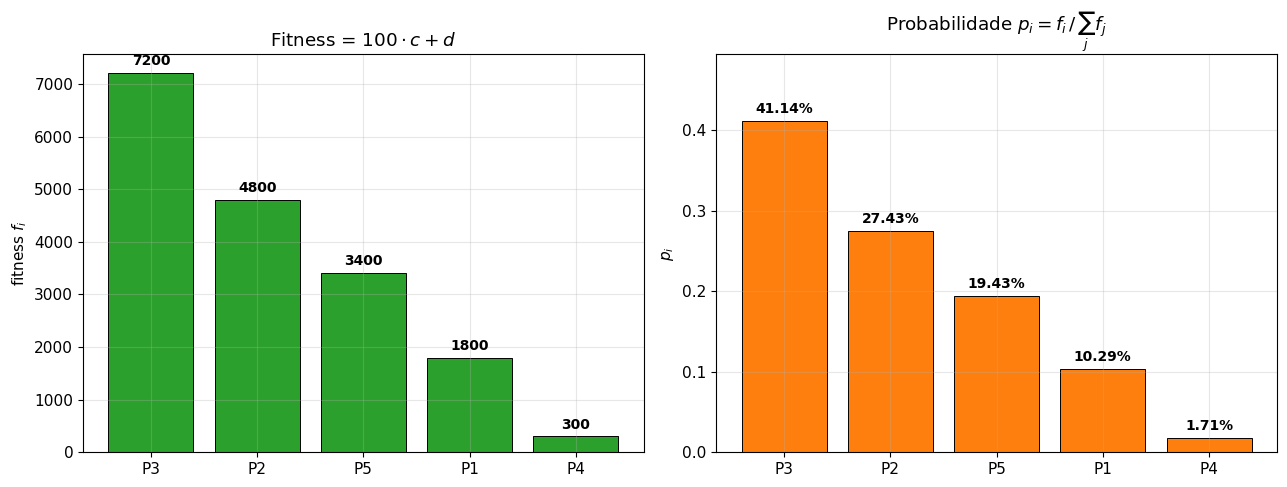

Fitness e probabilidades:
  P3: fitness =  7200   p =  0.4114  (41.14%)
  P2: fitness =  4800   p =  0.2743  (27.43%)
  P5: fitness =  3400   p =  0.1943  (19.43%)
  P1: fitness =  1800   p =  0.1029  (10.29%)
  P4: fitness =   300   p =  0.0171  ( 1.71%)
  Soma das probabilidades = 1.000000


In [ ]:
# Fitness e probabilidades normalizadas dos 5 pássaros do exemplo D.5
# Também serve de insumo visual para a roleta da célula 38.

passaros = ['P3', 'P2', 'P5', 'P1', 'P4']
canos    = [12, 8, 6, 3, 0]
distancias = [6000, 4000, 2800, 1500, 300]

fitness = [100 * c + d for c, d in zip(canos, distancias)]
total = sum(fitness)
probs = [f / total for f in fitness]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# --- (1) Fitness bruta ---
bars1 = ax1.bar(passaros, fitness, color='#2ca02c',
                edgecolor='black', linewidth=0.7)
ax1.set_title('Fitness = $100 \\cdot c + d$')
ax1.set_ylabel('fitness $f_i$')
ax1.grid(alpha=0.3, axis='y')
for b, f in zip(bars1, fitness):
    ax1.text(b.get_x() + b.get_width()/2, f + 150,
             f'{f}', ha='center', fontsize=10, fontweight='bold')

# --- (2) Probabilidade de seleção ---
bars2 = ax2.bar(passaros, probs, color='#ff7f0e',
                edgecolor='black', linewidth=0.7)
ax2.set_title(r'Probabilidade $p_i = f_i \,/\, \sum_j f_j$')
ax2.set_ylabel('$p_i$')
ax2.set_ylim(0, max(probs) * 1.2)
ax2.grid(alpha=0.3, axis='y')
for b, p in zip(bars2, probs):
    ax2.text(b.get_x() + b.get_width()/2, p + 0.01,
             f'{p:.2%}', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

# Verificação numérica
print("Fitness e probabilidades:")
for p, f, pr in zip(passaros, fitness, probs):
    print(f"  {p}: fitness = {f:5d}   p = {pr:7.4f}  ({pr*100:5.2f}%)")
print(f"  Soma das probabilidades = {sum(probs):.6f}")

# PARTE E — MORTE E SELEÇÃO

Como decidir quem vira pai? Existem várias técnicas. Aqui apresentamos as duas principais (elitismo e torneio) e uma alternativa (roleta).

---

## E.1 Diferença entre morte física (no jogo) e morte evolutiva (na seleção)

**Em termos simples:** há duas mortes no GA. Uma acontece **durante** o jogo (colisão). A outra acontece **na hora de escolher quem reproduz**. São coisas diferentes e é fundamental não confundir.

### A morte física

Acontece no jogo: quando o pássaro bate no chão, teto ou cano, ele **para de jogar**. Sua fitness é **congelada** no valor acumulado até ali. Ele **não é retirado** da população — só tem fitness registrada.

### A morte evolutiva

Acontece depois que todos jogaram: escolhemos quais indivíduos serão **pais**. Os não escolhidos não geram descendentes — morrem evolutivamente.

### Tabela comparativa

| Aspecto | Morte física | Morte evolutiva |
|---------|--------------|-----------------|
| Quando acontece | Durante a simulação | Após a simulação |
| Quem morre | O pássaro bate em algo | O pássaro não é escolhido como pai |
| Consequência | Fitness congela | Não gera descendentes |
| É total? | Sim, o pássaro não joga mais | Depende: pode reproduzir 0, 1, ou várias vezes |
| Como é implementado | Condição de colisão | Seleção por fitness |

### Exemplo numérico — Seção E.1

**Entrada:** 3 pássaros

- Pássaro A: morreu no cano 2, fitness = 500
- Pássaro B: morreu no cano 15, fitness = 6200
- Pássaro C: morreu no cano 5, fitness = 1200

**Passo 1:** morte física — todos pararam quando colidiram

**Passo 2:** morte evolutiva — apenas B e C são escolhidos como pais

**Passo 3:** A não gera descendentes

**Resultado:** A teve morte física + morte evolutiva. B e C só física.

**Efeito prático:** confundir as duas mortes causa bugs. Um pássaro com fitness baixa ainda tem um genoma — pode ser usado para análise. Um pássaro com fitness alta não "sobrevive" magicamente; só se for escolhido para reproduzir.

**Resumo da seção:** Morte física = colisão (congela fitness). Morte evolutiva = não virar pai (não gera descendentes). São independentes e ambas precisam ser tratadas corretamente no código.

## E.2 Elitismo — o que é, por que existe, quantos usar, o que acontece se usar 0 ou muitos

**Em termos simples:** elitismo é garantir que os **melhores pássaros** passem intactos para a próxima geração. Mesmo que os filhos gerados sejam todos ruins, os melhores do passado permanecem.

### Como funciona

1. Ordenar a população por fitness (do maior para o menor)
2. Copiar os $E$ primeiros **intactos** (sem cruzamento, sem mutação) para a próxima geração
3. O resto da nova geração é preenchido com filhos

### A fórmula simbólica

$$
P_{t+1} \supset \{ g_{(1)}, g_{(2)}, \dots, g_{(E)} \}
$$

### Cada símbolo

| Símbolo | Significado |
|---------|-------------|
| $P_{t+1}$ | Nova população |
| $\supset$ | "Contém como subconjunto" (os elites estão dentro da nova população) |
| $g_{(1)}$ | Genoma com maior fitness (1º colocado) |
| $g_{(E)}$ | Genoma com fitness na posição $E$ |
| $E$ | Número de elites |

### Por que elitismo existe

Imagine que os melhores da geração $t$ tinham fitness $1000$. Mas os filhos gerados são todos ruins (fitness $100$). Sem elitismo, a nova geração teria fitness máxima $100$ → retrocesso. Com elitismo, o melhor ($1000$) permanece, e o pior caso é "não melhorar" — nunca piorar.

### Quantos usar

Valores típicos: $E = 1$ ou $E = 2$, para populações de 30-100.

| $E$ | Efeito |
|-------|--------|
| 0 | Sem elitismo: pode piorar a cada geração |
| 1-2 | **Recomendado**: garante não-regressão sem prejudicar diversidade |
| 5+ | Começa a ficar conservador: menos espaço para novidade |
| 50% da população | Convergência prematura: metade é cópia |

### Exemplo numérico — Seção E.2

**Entrada:** população ordenada por fitness

- 1º: $g_1$ (fitness 7200)
- 2º: $g_2$ (fitness 4800)
- 3º: $g_3$ (fitness 3400)
- 4º: $g_4$ (fitness 1800)
- 5º: $g_5$ (fitness 300)

$E = 2$ (elites = 2)

**Passo 1:** nova população $P_{t+1}$ começa com $[g_1, g_2]$ (intactos)

**Passo 2:** filhos serão adicionados até ter $N = 5$

**Passo 3:** gerar 3 filhos por cruzamento + mutação

**Resultado:** $P_{t+1} = [g_1, g_2, \text{filho}_1, \text{filho}_2, \text{filho}_3]$

**Se $E = 0$:** $P_{t+1} = [\text{filho}_1, \text{filho}_2, \text{filho}_3, \text{filho}_4, \text{filho}_5]$ → risco de piorar.

**Se $E = 4$:** $P_{t+1} = [g_1, g_2, g_3, g_4, \text{filho}_1]$ → quase nenhuma novidade por geração.

**Efeito prático:**
- **Aumentar $E$** → progresso mais seguro mas mais lento (menos filhos = menos exploração).
- **Diminuir $E$** → progresso mais rápido mas pode regredir.
- **Regra:** $E = 1$ para populações pequenas ($N \leq 20$); $E = 2$ para populações médias (20-100); $E$ = 5% de $N$ para populações grandes.

**Resumo da seção:** Elitismo copia os melhores intactos. Garante que a evolução não piora. Use $E=1$ ou $2$. Sem elitismo, pode regredir. Com muito elitismo, fica conservador demais.

## E.3 Seleção por torneio — algoritmo passo a passo, exemplo numérico com $k=3$

**Em termos simples:** para escolher um pai, sorteamos $k$ pássaros aleatórios e o de maior fitness dentro do grupo vence. Repetimos até ter pais suficientes.

### Algoritmo

```
função torneio(P, k):
    1. Sortear k índices aleatórios de P
    2. Pegar os k indivíduos correspondentes
    3. Devolver o de maior fitness
```

### Parâmetro $k$

| $k$ | Efeito |
|-------|--------|
| 1 | Sorteio aleatório puro (nenhuma pressão) |
| 2 | Pressão baixa (melhor só ganha do par) |
| 3-4 | **Recomendado** para nosso caso |
| 5+ | Pressão alta (melhor quase sempre vence) |

### Exemplo numérico — Seção E.3

**Entrada:** 5 pássaros com fitness

- $P_1$: 7200
- $P_2$: 4800
- $P_3$: 3400
- $P_4$: 1800
- $P_5$: 300

$k = 3$

**Rodada 1:** sortear 3 índices → $\{2, 4, 1\}$
- Fitness sorteadas: $4800, 1800, 7200$
- Vencedor: $P_1$ (7200)

**Rodada 2:** sortear 3 índices → $\{5, 2, 3\}$
- Fitness sorteadas: $300, 4800, 3400$
- Vencedor: $P_2$ (4800)

**Rodada 3:** sortear 3 índices → $\{3, 5, 4\}$
- Fitness sorteadas: $3400, 300, 1800$
- Vencedor: $P_3$ (3400)

**Resultado:** pais escolhidos = $[P_1, P_2, P_3]$.

**Se $k = 1$:** pais seriam totalmente aleatórios (nenhuma pressão).

**Se $k = 5$:** em toda rodada, os 5 pássaros entram no torneio → $P_1$ sempre vence → pressão máxima → convergência prematura para descendentes de $P_1$.

### Por que torneio é preferido

- **Controla a pressão seletiva** via $k$ (diferente da roleta, onde é difícil controlar)
- **Escala bem** se a fitness for muito desigual
- **Simples de implementar**
- **Matematicamente robusto** — funciona com fitness negativas, zeros, o que for

**Efeito prático:** use torneio com $k = 3$. Se a evolução parecer lenta, aumente $k$ para 4. Se parecer que convergiu cedo demais, diminua para 2.

**Resumo da seção:** Torneio sorteia $k$ e escolhe o melhor. Controla pressão via $k$. $k=3$ é bom padrão. Simples e robusto, melhor que roleta para nosso caso.

## E.4 Seleção por roleta — fórmula, exemplo numérico, comparação com torneio

**Em termos simples:** sorteamos um número $U(0,1)$ e percorremos a lista acumulando probabilidades até passar o número sorteado. Pássaros com fitness alta têm mais "fatias" da roleta.

### Algoritmo

```
função roleta(P, p):
    u = sortear U(0,1)
    acumulado = 0
    para cada pássaro i em P:
        acumulado = acumulado + p[i]
        se acumulado >= u:
            devolver i
```

### A fórmula da probabilidade

Como visto em D.4:

$$
p_i = \frac{f(g_i)}{\sum_{j} f(g_j)}
$$

### Exemplo numérico — Seção E.4

**Entrada:** 5 pássaros com probabilidades normalizadas

- $P_1$: 0.4114
- $P_2$: 0.2743
- $P_3$: 0.1943
- $P_4$: 0.1029
- $P_5$: 0.0171

**Sorteio 1:** $u = 0.6234$
- acumulado após $P_1 = 0.4114 < 0.6234$ (não)
- acumulado após $P_2 = 0.4114 + 0.2743 = 0.6857 > 0.6234$ (SIM)
- Vencedor: $P_2$

**Sorteio 2:** $u = 0.1500$
- acumulado após $P_1 = 0.4114 > 0.1500$ (SIM)
- Vencedor: $P_1$

**Sorteio 3:** $u = 0.9500$
- acumulado após $P_1 = 0.4114$ (não)
- acumulado após $P_2 = 0.6857$ (não)
- acumulado após $P_3 = 0.8800$ (não)
- acumulado após $P_4 = 0.9829 > 0.9500$ (SIM)
- Vencedor: $P_4$

**Resultado:** pais escolhidos = $[P_2, P_1, P_4]$.

Observação: $P_4$ (fitness baixa) foi escolhido porque o sorteio caiu na fatia dele. Isso é a "diversidade" da roleta funcionando.

### Comparação com torneio

| Aspecto | Roleta | Torneio |
|---------|--------|---------|
| Pressão seletiva | Difícil controlar (depende da distribuição) | Fácil (controlada por $k$) |
| Com fitness desiguais | Um indivíduo domina | Cada rodada tem chance de outro ganhar |
| Sensível a fitness negativa | Quebra (probabilidade negativa) | Funciona normalmente |
| Complexidade | Um pouco mais de aritmética | Mais simples |
| Uso recomendado | Problemas didáticos | **Problemas reais** |

**Efeito prático:** para o nosso Flappy Bird, prefira torneio. Se quiser comparar nos experimentos, roleta é uma alternativa válida mas pode ter problemas.

**Resumo da seção:** Roleta escolhe proporcionalmente ao fitness usando $U(0,1)$ acumulado. Funciona mas é sensível a fitness muito desiguais. Torneio é geralmente melhor. Roleta é bom para comparação didática.

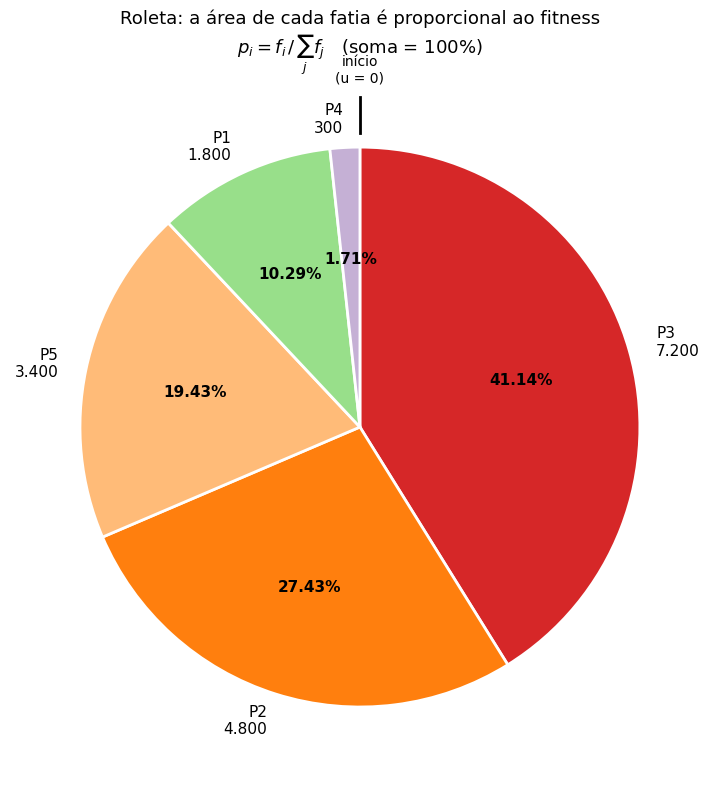

Probabilidades de seleção por roleta:
  P3: p = 0.4114  → acumulado = 0.4114
  P2: p = 0.2743  → acumulado = 0.6857
  P5: p = 0.1943  → acumulado = 0.8800
  P1: p = 0.1029  → acumulado = 0.9829
  P4: p = 0.0171  → acumulado = 1.0000
  Soma total = 1.000000  (deve ser 1.000000)


In [ ]:
# Roleta visual: fatias proporcionais ao fitness (mesmos dados da célula 33)
passaros = ['P3', 'P2', 'P5', 'P1', 'P4']
canos    = [12, 8, 6, 3, 0]
distancias = [6000, 4000, 2800, 1500, 300]

fitness = [100 * c + d for c, d in zip(canos, distancias)]
total = sum(fitness)
probs = [f / total for f in fitness]

# Paleta: as fatias maiores ficam com cores mais "quentes"
cores = ['#d62728', '#ff7f0e', '#ffbb78', '#98df8a', '#c5b0d5']

fig, ax = plt.subplots(figsize=(8, 8))

wedges, textos_ext, textos_auto = ax.pie(
    probs,
    labels=[f'{p}\n{f:,}'.replace(',', '.') for p, f in zip(passaros, fitness)],
    colors=cores,
    autopct=lambda pct: f'{pct:.2f}%',
    startangle=90,
    counterclock=False,
    textprops=dict(fontsize=11),
    wedgeprops=dict(edgecolor='white', linewidth=2),
)

# Realça o autopct em negrito
for t in textos_auto:
    t.set_fontweight('bold')
    t.set_color('black')

ax.set_title(
    'Roleta: a área de cada fatia é proporcional ao fitness\n'
    '$p_i = f_i \\,/\\, \\sum_j f_j$   (soma = 100%)',
    fontsize=13,
)

# Linha vertical no topo indicando "início da roleta" (u = 0)
ax.plot([0, 0], [1.05, 1.18], color='black', linewidth=2)
ax.text(0, 1.22, 'início\n(u = 0)', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

# Impressão numérica de controle
print("Probabilidades de seleção por roleta:")
acumulado = 0.0
for p, pr in zip(passaros, probs):
    acumulado += pr
    print(f"  {p}: p = {pr:.4f}  → acumulado = {acumulado:.4f}")
print(f"  Soma total = {acumulado:.6f}  (deve ser 1.000000)")

## E.5 Pressão seletiva: o que é, como $k$ controla isso

**Em termos simples:** pressão seletiva é "o quanto favorecemos os melhores sobre os piores". Alta pressão = melhores dominam. Baixa = todos têm chance.

### A definição informal

Pressão seletiva mede a diferença média entre pais escolhidos e a média da população.

- **Pressão alta:** pais são quase sempre os melhores
- **Pressão baixa:** pais têm fitness parecida com a média da população

### Como controlar

No **torneio**, o controle é direto via $k$:

| $k$ | Pressão | Efeito |
|-------|---------|--------|
| 1 | Nula | Aleatório |
| 2 | Baixa | Convergência lenta, muita diversidade |
| 3 | Média | **Recomendado** |
| 4-5 | Alta | Convergência rápida, risco de estagnar |
| 10 | Muito alta | Melhor sempre vence → colapso de diversidade |

Na **roleta**, o controle é indireto. Se fitness são parecidas, pressão baixa. Se muito desiguais, pressão alta.

### Trade-off da pressão seletiva

- **Pressão muito baixa:** evolução lenta, parece aleatório
- **Pressão muito alta:** evolução rápida nas primeiras gerações, mas converge para um ótimo local ruim e não sai mais

### Exemplo numérico — Seção E.5

**Entrada:** 5 pássaros com fitness $[7200, 4800, 3400, 1800, 300]$

$$
\text{Média} = 17500 / 5 = 3500
$$

**Torneio com $k=2$ (baixa pressão):**
- Rodada 1: sortear 2 → $\{4, 5\}$ → $P_4$ vence ($1800 > 300$)
- $P_4$ (1800) está **abaixo da média**. Baixa pressão.

**Torneio com $k=4$ (alta pressão):**
- Rodada 1: sortear 4 → $\{1, 2, 3, 4\}$ → $P_1$ vence (7200)
- $P_1$ está **bem acima da média**. Alta pressão.

**Diferença prática:** com $k=2$, pais vêm de regiões variadas do espaço de genes. Com $k=4$, pais vêm quase sempre do topo.

**Efeito prático:** ajuste $k$ para calibrar. Se a evolução estagnar, aumente levemente. Se pássaros ficarem todos iguais muito cedo, diminua.

**Resumo da seção:** Pressão seletiva = quanto favorecemos os melhores. No torneio, controlada por $k$. Baixa → diversidade; alta → convergência. $k=3$ é bom padrão. Alta demais causa estagnação em ótimo local.

## E.6 O que NÃO fazer (erros comuns de iniciante)

**Em termos simples:** uma lista de armadilhas comuns, para você não cair nelas.

### Erro 1 — Usar somente elitismo e nenhum filho

Se você copia só os 100% melhores, cada geração é idêntica. Nenhuma novidade é introduzida. Nenhuma melhora acontece.

### Erro 2 — Não usar elitismo nenhum

Sem elites, uma geração ruim pode destruir todo o progresso. O melhor de antes pode desaparecer.

### Erro 3 — Selecionar apenas os 10% melhores e descartar o resto

Aí não há variação. Todos os filhos são de poucos pais → convergência extrema. Perde-se diversidade. Se aquele "ótimo" não for realmente o melhor, a população fica presa.

### Erro 4 — Roleta com fitness negativas

Se por acaso uma fitness ficar negativa (por bug ou fórmula mal escolhida), a probabilidade fica negativa → quebra. **Use torneio** para evitar isso.

### Erro 5 — Normalizar o fitness errado

Se esquecer de somar tudo ou dividir pelo total errado, as probabilidades somam mais ou menos que 1 → roleta quebra.

### Erro 6 — Confundir "melhor fitness" com "melhor comportamento"

Um pássaro pode ter fitness alta **por sorte** (foi longe sem colidir por acaso). Não é necessariamente bom jogador. Na arguição, é bom saber: **fitness é proxy, não perfeito**.

### Erro 7 — Comparar fitness de diferentes "tamanhos de população"

Fitness não é comparável entre execuções diferentes. Compare apenas dentro da mesma população.

### Erro 8 — Ignorar empates

Se dois pássaros têm fitness idêntica, precisa haver desempate (por exemplo, distância percorrida, tempo vivo). Sem desempate, ordenação pode ser aleatória.

**Efeito prático:** esses erros são os mais comuns. Se você encontrá-los no seu projeto, volte aqui.

**Resumo da seção:** erros comuns: só elitismo, nenhum elitismo, poucos pais (convergência prematura), roleta com fitness negativa, normalização errada, confundir sorte com mérito, comparar entre execuções, ignorar empates. Evite todos.

# PARTE F — CRUZAMENTO

Depois de escolher os pais, precisamos gerar filhos. Isso é feito pelo cruzamento.

---

## F.1 O que é cruzamento e por que ele mistura "boas ideias" dos pais

**Em termos simples:** cruzamento é pegar parte dos genes de um pai e parte da mãe, montando um filho novo. A intuição biológica é que boas combinações de genes podem se juntar em um indivíduo ainda melhor.

### Por que funciona

Se pai A é bom em "subir cedo" e pai B é bom em "descer tarde", talvez um filho com metade dos genes de cada um combine os dois comportamentos. Claro, também pode dar errado — daí a necessidade de seleção depois.

### Metáfora

Imagine duas receitas de bolo. Uma é boa no recheio, outra é boa na massa. Cruzar = pegar o recheio da primeira e a massa da segunda. Talvez produza um bolo excelente; talvez produza um desastre. A seleção decide depois.

### Sem cruzamento

Se só houver mutação, cada filho é uma cópia ligeiramente modificada de um único pai. A evolução fica muito mais lenta — ela só refina localmente, não combina ideias distantes.

### Exemplo numérico — Seção F.1

**Entrada:**
- Pai A: $g_A = [0.3, -1.2, 0.8, 0.5, -0.1, 0.2]$
- Pai B: $g_B = [1.1, 0.4, -0.2, 0.9, 0.7, -0.3]$

**Sem cruzamento (só mutação a partir de A):**
- Filho $=$ A $+$ pequeno ruído → continua "parecido" com A
- Nunca explora combinações de A com B

**Com cruzamento (uniforme, ver F.2):**
- Filho $=$ mistura de A e B → pode ter $[0.3, 0.4, 0.8, 0.9, -0.1, -0.3]$
- Combina genes que estavam em pais diferentes.

**Efeito prático:** cruzamento acelera muito a evolução em problemas onde "boas partes" existem em pais diferentes. No nosso Flappy Bird, permite combinar "pular quando perto do vão" (gene de A) com "não pular quando subindo rápido" (gene de B).

**Resumo da seção:** Cruzamento mistura genes de dois pais. Combina boas "ideias" de indivíduos diferentes. Sem cruzamento, evolução é lenta. Com cruzamento, muito mais rápida — desde que as combinações sejam boas (e a seleção decide).

## F.2 Cruzamento uniforme — fórmula, exemplo gene a gene com valores concretos

**Em termos simples:** para cada gene do filho, sorteia-se de qual pai ele vem (50% A, 50% B). Decisão independente para cada posição.

### A fórmula

$$
g_f[j] =
\begin{cases}
g_A[j], & \text{se } r_j < 0.5 \\
g_B[j], & \text{caso contrário}
\end{cases}
$$

### Cada símbolo

| Símbolo | Significado |
|---------|-------------|
| $g_f[j]$ | Gene $j$ do filho |
| $g_A[j]$ | Gene $j$ do pai A |
| $g_B[j]$ | Gene $j$ do pai B |
| $r_j$ | Número sorteado $U(0,1)$ para o gene $j$ |
| $0.5$ | Limiar: 50% de chance de vir de cada pai |

### Propriedade

Cada gene tem 50% de vir de A e 50% de B, **independentemente** dos outros. Isso significa que o filho pode ser idêntico a um dos pais (probabilidade $1/64$ para 6 genes) ou completamente misturado.

### Exemplo numérico — Seção F.2

**Entrada:**
- $g_A = [0.3, -1.2, 0.8, 0.5, -0.1, 0.2]$
- $g_B = [1.1, 0.4, -0.2, 0.9, 0.7, -0.3]$
- Sorteios: $r = [0.4, 0.7, 0.2, 0.6, 0.3, 0.9]$

**Gene 1:** $r_1 = 0.4 < 0.5$ → de A → $0.3$

**Gene 2:** $r_2 = 0.7 \geq 0.5$ → de B → $0.4$

**Gene 3:** $r_3 = 0.2 < 0.5$ → de A → $0.8$

**Gene 4:** $r_4 = 0.6 \geq 0.5$ → de B → $0.9$

**Gene 5:** $r_5 = 0.3 < 0.5$ → de A → $-0.1$

**Gene 6:** $r_6 = 0.9 \geq 0.5$ → de B → $-0.3$

**Filho:** $g_f = [0.3, 0.4, 0.8, 0.9, -0.1, -0.3]$.

**Se $r_2$ fosse $0.3$ em vez de $0.7$:** Gene 2 viria de A → $g_f[2] = -1.2$. Filho: $[0.3, -1.2, 0.8, 0.9, -0.1, -0.3]$.

**Efeito prático:**
- **Cruzamento uniforme** é bom quando se quer exploração máxima (cada gene independente).
- Preserva estrutura de pais em diferentes genes simultaneamente.
- É o mais simples de implementar.

**Resumo da seção:** Cruzamento uniforme sorteia cada gene independentemente (50% de cada pai). Simples e explora bem o espaço. É a escolha recomendada para começar.

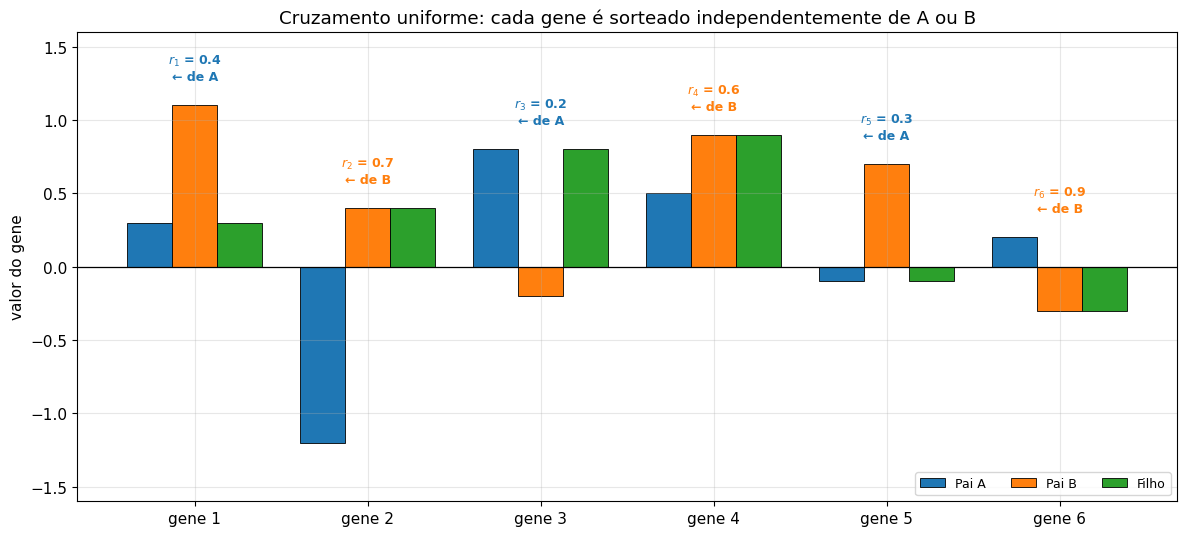

Gene |  Pai A   |  Pai B   |   r_j   |  Origem  |  Filho
--------------------------------------------------------------
  1  |  +0.30   |  +1.10   |  0.40   |    A     |  +0.30
  2  |  -1.20   |  +0.40   |  0.70   |    B     |  +0.40
  3  |  +0.80   |  -0.20   |  0.20   |    A     |  +0.80
  4  |  +0.50   |  +0.90   |  0.60   |    B     |  +0.90
  5  |  -0.10   |  +0.70   |  0.30   |    A     |  -0.10
  6  |  +0.20   |  -0.30   |  0.90   |    B     |  -0.30


In [ ]:
# Cruzamento uniforme gene a gene: visualização do exemplo da seção F.2
pai_A = np.array([0.3, -1.2, 0.8, 0.5, -0.1, 0.2])
pai_B = np.array([1.1, 0.4, -0.2, 0.9, 0.7, -0.3])
r = np.array([0.4, 0.7, 0.2, 0.6, 0.3, 0.9])
filho = np.where(r < 0.5, pai_A, pai_B)

fig, ax = plt.subplots(figsize=(12, 5.5))
idx = np.arange(6)
larg = 0.26

b1 = ax.bar(idx - larg, pai_A, larg, label='Pai A',
            color='#1f77b4', edgecolor='black', linewidth=0.6)
b2 = ax.bar(idx,          pai_B, larg, label='Pai B',
            color='#ff7f0e', edgecolor='black', linewidth=0.6)
b3 = ax.bar(idx + larg, filho, larg, label='Filho',
            color='#2ca02c', edgecolor='black', linewidth=0.6)

# Anotação de cada gene: mostra r_j e de qual pai veio
for i in range(6):
    origem = 'A' if r[i] < 0.5 else 'B'
    cor = '#1f77b4' if origem == 'A' else '#ff7f0e'
    y_max = max(pai_A[i], pai_B[i], filho[i])
    ax.text(i, y_max + 0.15,
            f'$r_{i+1}$ = {r[i]:.1f}\n← de {origem}',
            ha='center', va='bottom', fontsize=9,
            color=cor, fontweight='bold')

ax.axhline(0, color='black', linewidth=0.9)
ax.set_xticks(idx)
ax.set_xticklabels([f'gene {i+1}' for i in range(6)])
ax.set_title('Cruzamento uniforme: cada gene é sorteado independentemente de A ou B')
ax.set_ylabel('valor do gene')
ax.set_ylim(-1.6, 1.6)
ax.legend(loc='lower right', ncol=3, fontsize=9)
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

# Impressão numérica
print("Gene |  Pai A   |  Pai B   |   r_j   |  Origem  |  Filho")
print("-" * 62)
for i in range(6):
    origem = 'A' if r[i] < 0.5 else 'B'
    print(f"  {i+1}  |  {pai_A[i]:+5.2f}   |  {pai_B[i]:+5.2f}   |"
          f"  {r[i]:.2f}   |    {origem}     |  {filho[i]:+5.2f}")

## F.3 Cruzamento aritmético — fórmula, exemplo, prós e contras

**Em termos simples:** o filho é uma média ponderada dos pais. Cada gene vira uma "mistura" dos genes correspondentes dos pais.

### A fórmula

$$
g_f[j] = \lambda \cdot g_A[j] + (1 - \lambda) \cdot g_B[j]
$$

### Cada símbolo

| Símbolo | Significado |
|---------|-------------|
| $\lambda$ | Número sorteado $U(0,1)$ (peso do pai A) |
| $1 - \lambda$ | Complemento (peso do pai B) |
| $g_A[j], g_B[j]$ | Genes dos pais |

### Propriedade

Os valores gerados **não existiam** nos pais. Se pai A tem 0.3 e pai B tem 1.1, o filho pode ter 0.7 (média). Isso explora o espaço contínuo.

### Exemplo numérico — Seção F.3

**Entrada:**
- $g_A = [0.3, -1.2, 0.8, 0.5, -0.1, 0.2]$
- $g_B = [1.1, 0.4, -0.2, 0.9, 0.7, -0.3]$
- Sorteio: $\lambda = 0.35$

**Gene 1:** $0.35 \cdot 0.3 + 0.65 \cdot 1.1 = 0.105 + 0.715 = 0.82$

**Gene 2:** $0.35 \cdot (-1.2) + 0.65 \cdot 0.4 = -0.42 + 0.26 = -0.16$

**Gene 3:** $0.35 \cdot 0.8 + 0.65 \cdot (-0.2) = 0.28 - 0.13 = 0.15$

**Gene 4:** $0.35 \cdot 0.5 + 0.65 \cdot 0.9 = 0.175 + 0.585 = 0.76$

**Gene 5:** $0.35 \cdot (-0.1) + 0.65 \cdot 0.7 = -0.035 + 0.455 = 0.42$

**Gene 6:** $0.35 \cdot 0.2 + 0.65 \cdot (-0.3) = 0.07 - 0.195 = -0.125$

**Filho:** $g_f = [0.82, -0.16, 0.15, 0.76, 0.42, -0.125]$.

**Se $\lambda$ fosse $0.9$ em vez de $0.35$:** Gene 1: $0.9 \cdot 0.3 + 0.1 \cdot 1.1 = 0.27 + 0.11 = 0.38$. Filho ficaria muito mais próximo de A.

### Prós e contras

| Prós | Contras |
|------|---------|
| Explora valores intermediários | Pode "diluir" genes extremos que eram bons |
| Suave (mutações pequenas) | Converge mais rápido (menos diversidade) |
| Bom em espaços contínuos | Difícil de garantir diversidade estrutural |

### Comparação com uniforme

- **Uniforme** preserva genes originais → mantém "blocos" bons
- **Aritmético** mistura tudo → pode perder genes extremos mas bons

**Efeito prático:**
- Comece com **uniforme** (mais robusto).
- Se quiser explorar, experimente aritmético **na Fase 2** e compare resultados.

**Resumo da seção:** Aritmético é média ponderada dos pais por $\lambda$ sorteado. Gera valores novos. Bom para exploração de espaço contínuo, ruim para preservar genes extremos. Use uniforme primeiro; aritmético é experimento opcional.

## F.4 Taxa de cruzamento $p_c$ — o que significa, exemplo de sorteio

**Em termos simples:** às vezes, dois pais escolhidos **não** cruzam — o filho é uma cópia direta de um deles. A probabilidade de cruzar é $p_c$.

### A regra

1. Selecionar pai A e pai B
2. Sortear $u \sim U(0,1)$
3. Se $u < p_c$: cruzar (usar fórmula de F.2 ou F.3)
4. Se $u \geq p_c$: filho = cópia de um dos pais (geralmente A)

### Cada símbolo

| Símbolo | Significado |
|---------|-------------|
| $p_c$ | Taxa de cruzamento |
| $u$ | Sorteio uniforme $U(0,1)$ |

### Valores típicos

- $p_c = 1.0$: sempre cruza (nenhuma cópia direta)
- $p_c = 0.9$: 10% das vezes, filho é cópia
- $p_c = 0.7$: 30% cópias
- $p_c = 0$: nunca cruza (equivalente a só mutação)

### Exemplo numérico — Seção F.4

**Entrada:** $p_c = 0.9$

**Rodada 1:** pais A e B escolhidos
- $u = 0.42 < 0.9$ → **CRUZA**
- Filho = cruzamento uniforme de A e B

**Rodada 2:** pais C e D escolhidos
- $u = 0.95 \geq 0.9$ → **NÃO CRUZA**
- Filho = cópia de C (ou D, escolha aleatória)

**Resultado:** 90% dos filhos são cruzamentos; 10% são cópias.

**Se $p_c$ fosse $0.5$:** 50% dos filhos seriam cópias (mais conservador, mais diversidade via cópia).

**Efeito prático:**
- $p_c$ **alto** (0.9) → filhos são sempre misturas → exploração combinatória.
- $p_c$ **baixo** (0.6) → muitos filhos são cópias → mantém mais "estrutura" dos pais.

**Recomendação:** $p_c = 0.9$.

**Resumo da seção:** $p_c$ é a chance de cruzar. 90% é padrão. Se não cruzar, filho é cópia de um pai. Isso mantém alguma inércia para não perder boas estruturas por recombinação excessiva.

## F.5 Quando usar cada tipo

**Em termos simples:** qual cruzamento usar depende do problema e do comportamento observado.

### Guia rápido

| Situação | Escolha |
|----------|---------|
| Iniciante | Uniforme |
| Poucos genes (5-10) | Uniforme |
| Genes contínuos | Ambos |
| Convergência muito rápida | Aritmético (mais suave) |
| Precisa explorar muito | Uniforme |
| Quer refinar uma solução já boa | Aritmético com $\lambda$ próximo de 0 ou 1 |

### Recomendação para o Flappy Bird

- **Fase 1 (primeira versão):** uniforme com $p_c = 0.9$
- **Fase 2 (experimentos):** compare com aritmético. Se uniforme estagna antes da geração 30, tente aritmético.

**Resumo da seção:** Comece com uniforme. Se o algoritmo estagnar rápido, teste aritmético. Não tem "melhor universal" — depende do problema.

# PARTE G — MUTAÇÃO

Mesmo com cruzamento, os filhos são combinações lineares dos pais. Para descobrir genes que **nenhum dos pais tinha**, precisamos de mutação.

---

## G.1 Por que mutar (diversidade, fugir de ótimo local)

**Em termos simples:** mutação é um pequeno "erro" intencional introduzido nos genes do filho. Sem ela, os valores só podem ser combinações dos que já existem — nunca surgem valores radicalmente novos.

### Dois motivos principais

**Motivo 1 — Diversidade:** manter variação na população. Se todos os genes são apenas misturas, depois de muitas gerações todos ficam parecidos. Mutação impede esse colapso.

**Motivo 2 — Fugir de ótimo local:** se a população está presa num comportamento "razoável mas não ótimo", uma mutação pode gerar um gene que leva a um comportamento muito melhor. Sem mutação, essa descoberta não aconteceria.

### O que é "ótimo local"

É uma solução boa dentro de uma vizinhança, mas não a melhor global. Analogia: você está numa montanha e só consegue subir. Chega no topo de um morro pequeno. A solução global pode estar em outra montanha mais alta, mas você não consegue ver nem ir até lá **descendo**. Mutação é um "teleporte" pequeno que pode jogar você na montanha maior.

### Exemplo numérico — Seção G.1

**Entrada:** população de 50 pássaros, todos com gene $w_2 \approx -0.75$ (valor bom mas não ótimo)

**Sem mutação:**
- Genes $w_2$ nos filhos: todos próximos de $-0.75$ (médias de $-0.75$)
- Após 20 gerações: $w_2 \approx -0.75$ ainda
- Nunca descobre que $w_2 = -1.8$ seria muito melhor

**Com mutação $\sigma = 0.3$:**
- Às vezes um filho tem $w_2 = -1.5$, outro $-2.0$, outro $-0.3$
- Se algum tiver $w_2 = -1.8$ (o ótimo), a fitness dele será maior
- Ele será selecionado, e a população inteira migra para $-1.8$

**Efeito prático:** sem mutação, evolução estagna. Com mutação excessiva, evolução vira busca aleatória. O equilíbrio é essencial.

**Resumo da seção:** Mutação introduz valores novos nos genes. Sem ela, a população fica homogênea e presa em ótimos locais. Com ela, o GA pode descobrir soluções que ninguém tinha. É o motor da descoberta.

## G.2 Mutação gaussiana — fórmula, exemplo numérico

**Em termos simples:** com certa probabilidade, perturba-se cada gene por um ruído gaussiano (a curva do sino). Perturbações pequenas são comuns; grandes são raras.

### A fórmula

$$
g_f[j] = g_f[j] + \Delta, \quad \Delta \sim \mathcal{N}(0, \sigma^2) \text{ se } u < p_m
$$

### Cada símbolo

| Símbolo | Significado |
|---------|-------------|
| $g_f[j]$ | Gene $j$ do filho (após cruzamento) |
| $\Delta$ | Perturbação sorteada de uma normal com média 0 e desvio $\sigma$ |
| $p_m$ | Probabilidade de mutação **por gene** |
| $u$ | Sorteio $U(0,1)$ para decidir se este gene muta |

### Leitura

Para cada gene $j$:
1. Sortear $u \sim U(0,1)$
2. Se $u < p_m$: perturbar por $\Delta \sim \mathcal{N}(0, \sigma^2)$
3. Caso contrário: não mutar

### Valores típicos

- $p_m = 0.05$: 5% dos genes mutam
- $p_m = 0.1$: 10% dos genes mutam (recomendado para 6 genes)
- $p_m = 0.2$: 20% dos genes mutam (alta mutação)

### Exemplo numérico — Seção G.2

**Entrada:**
- Filho (após cruzamento): $[0.3, 0.4, 0.8, 0.9, -0.1, -0.3]$
- $p_m = 0.1$
- $\sigma = 0.3$

**Sorteios $u$:** $[0.05, 0.42, 0.03, 0.85, 0.08, 0.91]$

**Gene 1:** $u = 0.05 < 0.1$ → **MUTA**
- $\Delta_1 = 0.12$ → novo gene $= 0.3 + 0.12 = 0.42$

**Gene 2:** $u = 0.42 \geq 0.1$ → não muta → $0.4$

**Gene 3:** $u = 0.03 < 0.1$ → **MUTA**
- $\Delta_3 = -0.18$ → novo gene $= 0.8 - 0.18 = 0.62$

**Gene 4:** $u = 0.85 \geq 0.1$ → não muta → $0.9$

**Gene 5:** $u = 0.08 < 0.1$ → **MUTA**
- $\Delta_5 = 0.05$ → novo gene $= -0.1 + 0.05 = -0.05$

**Gene 6:** $u = 0.91 \geq 0.1$ → não muta → $-0.3$

**Filho após mutação:** $[0.42, 0.4, 0.62, 0.9, -0.05, -0.3]$.

**Se $p_m$ fosse $0.5$ em vez de $0.1$:** mais genes mutariam (a maioria) → mais exploração, menos refinamento.

**Efeito prático:**
- **Aumentar $p_m$** → mais mutação → mais diversidade → convergência mais lenta.
- **Diminuir $p_m$** → menos mutação → refinamento → risco de estagnar.

**Resumo da seção:** Mutação gaussiana perturba cada gene com probabilidade $p_m$ por $\Delta$ gaussiano. $p_m = 0.1$ e $\sigma = 0.3$ são bons padrões. Mais mutação = exploração; menos = refinamento.

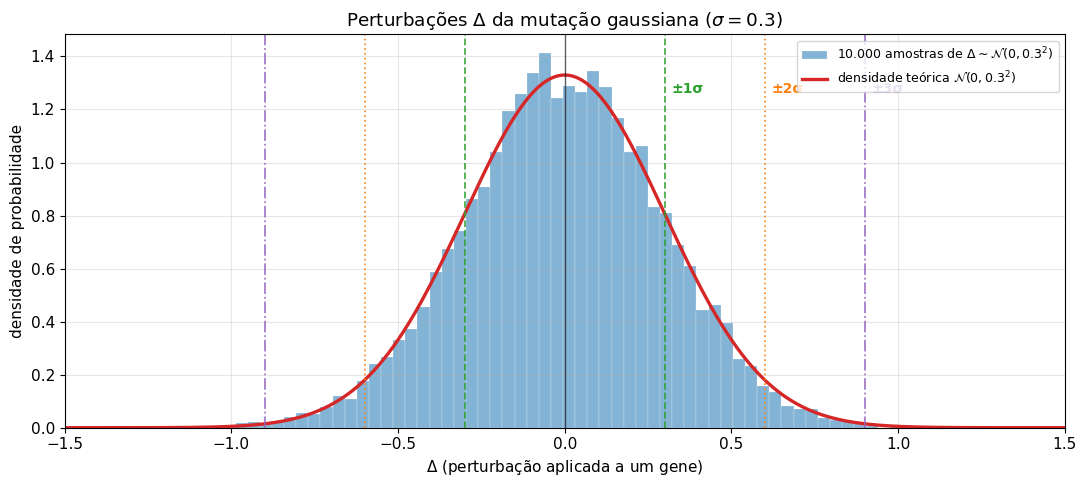

Proporção empírica de |Δ| dentro de k·σ:
  |Δ| ≤ 1σ (0.3): 68.92%   (esperado ~68%)
  |Δ| ≤ 2σ (0.6): 95.62%   (esperado ~95%)
  |Δ| ≤ 3σ (0.9): 99.68%   (esperado ~99.7%)

Perturbação média:  -0.0027  (esperado ≈ 0)
Desvio-padrão real: 0.2977  (esperado = 0.3000)


In [ ]:
# Distribuição empírica das perturbações Δ ~ N(0, σ²) com σ = 0.3
# Mostra que a maioria cai perto de zero (refinamento) e poucas são grandes (exploração)

np.random.seed(7)
sigma = 0.3
amostras = np.random.normal(0, sigma, 10000)

fig, ax = plt.subplots(figsize=(11, 5))

# Histograma das amostras reais
ax.hist(amostras, bins=60, density=True, alpha=0.55,
        color='#1f77b4', edgecolor='white', linewidth=0.3,
        label=r'10.000 amostras de $\Delta \sim \mathcal{N}(0, 0.3^2)$')

# Curva teórica por cima
xs = np.linspace(-1.5, 1.5, 400)
ax.plot(xs, norm.pdf(xs, 0, sigma), color='#d62728', linewidth=2.4,
        label=r'densidade teórica $\mathcal{N}(0, 0.3^2)$')

# Linhas-guia: ±σ, ±2σ, ±3σ
for k, cor, ls in [(1, '#2ca02c', '--'),
                   (2, '#ff7f0e', ':'),
                   (3, '#9467bd', '-.')]:
    for sinal in [-1, +1]:
        ax.axvline(sinal * k * sigma, color=cor, linestyle=ls,
                   linewidth=1.3, alpha=0.85)
    # rótulo no topo
    ax.text(k * sigma + 0.02, ax.get_ylim()[1] * 0.85,
            f'±{k}σ', color=cor, fontsize=10, fontweight='bold')

ax.axvline(0, color='black', linestyle='-', linewidth=1, alpha=0.6)

ax.set_title(r'Perturbações $\Delta$ da mutação gaussiana ($\sigma = 0.3$)')
ax.set_xlabel(r'$\Delta$ (perturbação aplicada a um gene)')
ax.set_ylabel('densidade de probabilidade')
ax.set_xlim(-1.5, 1.5)
ax.legend(loc='upper right', fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Verificação numérica da regra 68-95-99.7
print("Proporção empírica de |Δ| dentro de k·σ:")
for k, esperado in [(1, '~68%'), (2, '~95%'), (3, '~99.7%')]:
    frac = np.mean(np.abs(amostras) <= k * sigma)
    print(f"  |Δ| ≤ {k}σ ({k*sigma:.1f}): {frac*100:5.2f}%   (esperado {esperado})")

print(f"\nPerturbação média:  {amostras.mean():+.4f}  (esperado ≈ 0)")
print(f"Desvio-padrão real: {amostras.std():.4f}  (esperado = 0.3000)")

## G.3 Clipping (limite dos genes) — por quê, exemplo

**Em termos simples:** se um gene muta repetidamente, pode virar um valor absurdo (ex.: $1000$). Isso quebra o comportamento. **Clipping** força cada gene a ficar dentro de um intervalo.

### A fórmula

$$
g_f[j] = \max(-5, \min(5, g_f[j]))
$$

### Cada símbolo

| Símbolo | Significado |
|---------|-------------|
| $\max(-5, \cdot)$ | O maior entre $-5$ e o resultado → garante que não fique abaixo de $-5$ |
| $\min(5, \cdot)$ | O menor entre $5$ e o resultado → garante que não fique acima de $5$ |
| $5$ | Limite máximo (positivo) |
| $-5$ | Limite mínimo (negativo) |

### Por que

Sem clipping, uma sequência de mutações positivas pode fazer um gene crescer sem parar:

- Mutação 1: $1.0 \to 1.5$
- Mutação 2: $1.5 \to 2.0$
- Mutação 3: $2.0 \to 2.7$
- ...
- Mutação 20: $\to 15$

Com gene em $15$, o comportamento do pássaro fica saturado (sempre pula ou nunca pula, dependendo da entrada). Não há evolução útil.

### Exemplo numérico — Seção G.3

**Entrada:** gene após mutação bruta $= 7.2$

**Passo 1:** $\max(-5, \min(5, 7.2)) = \max(-5, 5) = 5$

**Resultado:** gene final $= 5$.

**Entrada:** gene após mutação bruta $= -8.5$

**Passo 1:** $\max(-5, \min(5, -8.5)) = \max(-5, -8.5) = -5$

**Resultado:** gene final $= -5$.

**Entrada:** gene após mutação bruta $= 1.3$

**Passo 1:** $\max(-5, \min(5, 1.3)) = \max(-5, 1.3) = 1.3$

**Resultado:** gene final $= 1.3$ (inalterado, estava dentro do limite).

**Efeito prático:**
- **Limites mais apertados** (ex.: $[-2, 2]$) → menos exploração mas convergência mais rápida.
- **Limites mais largos** (ex.: $[-10, 10]$) → mais exploração mas mais caos.

**Recomendação:** $[-5, 5]$ é um bom equilíbrio para nosso caso.

**Resumo da seção:** Clipping limita cada gene a um intervalo fixo. Evita que genes explodam após muitas mutações. Use $[-5, 5]$. Sem clipping, genes podem virar números absurdos e quebrar o comportamento.

## G.4 Mutação reset — quando usar

**Em termos simples:** ocasionalmente, ao invés de perturbar um gene, **substitui-se** ele por um valor completamente novo (sorteado em $[-1, 1]$). É uma "mutação radical".

### A fórmula

Com probabilidade $p_{\text{reset}}$ (diferente de $p_m$):

$$
g_f[j] \sim U(-1, 1)
$$

### Quando usar

- **GA preso em ótimo local:** todas as pequenas perturbações não saem do local. Reset joga o gene longe, forçando descoberta.
- **Populações muito homogêneas:** todos genes parecidos. Reset quebra homogeneidade.
- **Problemas multimodais:** com múltiplas "montanhas" de soluções boas.

### Quando NÃO usar

- **Fase inicial de convergência:** reset destrói progresso.
- **Problemas simples com ótimo único:** não ajuda.

### Exemplo numérico — Seção G.4

**Entrada:**
- Filho: $[0.3, 0.4, 0.8, 0.9, -0.1, -0.3]$
- $p_{\text{reset}} = 0.02$ (2% por gene)

**Sorteios $u_{\text{reset}}$:** $[0.05, 0.02, 0.5, 0.8, 0.5, 0.5]$

**Sorteios $u_m$:** $[0.5, 0.5, 0.5, 0.5, 0.08, 0.5]$

**Gene 1:** $u_{\text{reset}} = 0.05 \geq 0.02$ → não reset

**Gene 2:** $u_{\text{reset}} = 0.02 < 0.02$? Não (é igual) → não reset

**Gene 5:** $u_m = 0.08 < 0.1$ → muta gaussiana ($0.05$ de perturbação). Gene 5 novo $= -0.1 + 0.05 = -0.05$

**Cenário hipotético** se $u_{\text{reset}}$ fosse $0.01$ para o gene 3:
- Gene 3: $u_{\text{reset}} = 0.01 < 0.02$ → **RESET**
- novo gene 3 = sortear $U(-1, 1) = 0.71$ → $g_f[3] = 0.71$

**Efeito prático:** reset é uma "ferramenta extra" para GA preso. Use com $p_{\text{reset}}$ baixa (0.01-0.05) e só quando perceber estagnação. Não é essencial na primeira versão.

**Resumo da seção:** Reset substitui gene por valor novo. Útil para fugir de ótimos locais e quebrar homogeneidade. Não use como padrão; ative quando perceber estagnação.

## G.5 Escolha de $p_m$ e $\sigma$ — tabela de efeitos

**Em termos simples:** os dois parâmetros da mutação controlam o trade-off exploração vs refinamento.

### Tabela de efeitos

| $p_m$ | $\sigma$ | Efeito |
|---------|-----------|--------|
| 0.01 | 0.1 | Muito conservador: convergência muito lenta |
| 0.05 | 0.2 | Conservador: refinamento alto |
| **0.10** | **0.3** | **Equilibrado (recomendado)** |
| 0.20 | 0.5 | Explorador: divergência possível |
| 0.50 | 1.0 | Caótico: quase busca aleatória |

### Como calibrar

1. **Comece com $p_m = 0.1, \sigma = 0.3$**
2. Se após 20 gerações fitness não melhora → **aumentar** $p_m$ ou $\sigma$ (mais exploração)
3. Se após 20 gerações fitness oscila muito (sobe e desce) → **diminuir** $p_m$ ou $\sigma$ (mais refinamento)

### Regra mnemônica

- $\sigma$ grande = **saltos grandes** (busca longe)
- $p_m$ grande = **saltos frequentes** (busca sempre)

**Resumo da seção:** $p_m$ é a frequência de mutação; $\sigma$ é o tamanho. $p_m=0.1, \sigma=0.3$ é o padrão. Aumente se estagnar; diminua se oscilar.

## G.6 Exemplo numérico completo de uma mutação gene a gene

**Em termos simples:** vamos fazer todo o processo de mutação num único filho, gene a gene, com todos os parâmetros definidos.

### Setup

- Filho (após cruzamento): $g = [0.3, 0.4, 0.8, 0.9, -0.1, -0.3]$
- $p_m = 0.1$
- $\sigma = 0.3$
- Limite: $[-5, 5]$

### Passo a passo

**Gene 1:**
- Sorteio $u = 0.07 < 0.1$ → **MUTA**
- Sorteio $\Delta = 0.15$
- Novo $= 0.3 + 0.15 = 0.45$

**Gene 2:**
- Sorteio $u = 0.31 \geq 0.1$ → não muta
- Novo $= 0.4$

**Gene 3:**
- Sorteio $u = 0.04 < 0.1$ → **MUTA**
- Sorteio $\Delta = 0.55$ (raro mas acontece)
- Novo $= 0.8 + 0.55 = 1.35$

**Gene 4:**
- Sorteio $u = 0.60 \geq 0.1$ → não muta
- Novo $= 0.9$

**Gene 5:**
- Sorteio $u = 0.09 < 0.1$ → **MUTA**
- Sorteio $\Delta = -0.28$
- Novo $= -0.1 - 0.28 = -0.38$

**Gene 6:**
- Sorteio $u = 0.88 \geq 0.1$ → não muta
- Novo $= -0.3$

**Passo final — clipping em todos:**
- $[0.45, 0.4, 1.35, 0.9, -0.38, -0.3]$
- Todos dentro de $[-5, 5]$ → inalterados

**Filho final:** $[0.45, 0.4, 1.35, 0.9, -0.38, -0.3]$.

### Comparação antes vs. depois

| Gene | Antes | Depois | $\Delta$ |
|------|-------|--------|----------|
| 1 | 0.3 | 0.45 | +0.15 |
| 2 | 0.4 | 0.4 | 0 |
| 3 | 0.8 | 1.35 | +0.55 |
| 4 | 0.9 | 0.9 | 0 |
| 5 | -0.1 | -0.38 | -0.28 |
| 6 | -0.3 | -0.3 | 0 |

Três genes mutaram (50% da população de genes — mas isso é só porque $p_m = 0.1$ é probabilidade por gene; neste exemplo, 3 de 6 mutaram por sorte; em média, seria $\approx 0.6$ gene por filho).

### Variação — se $p_m = 0.3$ e $\sigma = 0.5$

- Sorteios $u$: $[0.07, 0.31, 0.04, 0.60, 0.09, 0.88]$
- Genes mutados: 1, 3, 5 (mesmos 3)
- Mas com $\sigma = 0.5$, os $\Delta$ seriam maiores:
  - $\Delta_1 \approx 0.25$ (em vez de 0.15)
  - $\Delta_3 \approx 0.90$ (em vez de 0.55)
  - $\Delta_5 \approx -0.45$ (em vez de -0.28)

**Filho:** $[0.55, 0.4, 1.7, 0.9, -0.55, -0.3]$. Mais mudança, mais exploração.

**Resumo da seção:** Mutação é feita gene a gene: sorteia $u$, se $u < p_m$, soma um $\Delta \sim \mathcal{N}(0, \sigma^2)$, depois aplica clipping. Cada gene é independente. No exemplo, 3 genes mutaram por sorte. Mais $p_m$ e $\sigma$ = mais mudança = mais exploração.

# PARTE H — NOVA GERAÇÃO

Agora juntamos tudo: pegar elites, gerar filhos, montar a nova população.

---

## H.1 Algoritmo de montagem da nova população (elites + filhos)

**Em termos simples:** a nova população é feita de **elites** (os melhores copiados intactos) mais **filhos** (gerados por cruzamento + mutação até preencher).

### Pseudocódigo

```
função montar_nova_populacao(P, N, E, k, p_c, p_m, σ):
    # 1. Ordenar por fitness decrescente
    P_ordenada = ordenar_por_fitness(P)

    # 2. Começar com elites
    P_nova = primeiros_E_de(P_ordenada)

    # 3. Preencher com filhos
    enquanto tamanho(P_nova) < N:
        pai_A = torneio(P_ordenada, k)
        pai_B = torneio(P_ordenada, k)

        # Cruzamento com probabilidade p_c
        u_c = sortear_U(0,1)
        se u_c < p_c:
            filho = cruzar(pai_A, pai_B)
        senão:
            filho = copiar(pai_A)

        # Mutação
        filho = mutar(filho, p_m, σ)

        # Clipping
        filho = clip(filho, -5, 5)

        adicionar(P_nova, filho)

    devolver P_nova
```

### Exemplo numérico — Seção H.1

**Entrada:** $N = 6$, $E = 2$, $k = 3$, $p_c = 0.9$

**População atual ordenada por fitness:**
- $P_1$ (7200), $P_2$ (4800), $P_3$ (3400), $P_4$ (1800), $P_5$ (300), $P_6$ (150)

**Passo 1:** ordenada = $[P_1, P_2, P_3, P_4, P_5, P_6]$

**Passo 2:** elites = $[P_1, P_2]$

**Passo 3:** gerar 4 filhos

**Filho 1:**
- $pai_A$ = torneio → sorteia $\{2, 5, 3\}$ → $P_2$ (4800)
- $pai_B$ = torneio → sorteia $\{1, 4, 6\}$ → $P_1$ (7200)
- $u_c = 0.42 < 0.9$ → cruzar
- cruzar($P_2$, $P_1$) com uniforme → genes misturados
- mutar → genes com pequenas perturbações

**Filho 2:**
- $pai_A$ = torneio → $P_3$
- $pai_B$ = torneio → $P_5$
- $u_c = 0.95 \geq 0.9$ → **NÃO cruzar**
- filho = cópia de $P_3$

**Filho 3:**
- $pai_A = P_1$, $pai_B = P_2$
- $u_c = 0.30 < 0.9$ → cruzar

**Filho 4:**
- $pai_A = P_4$, $pai_B = P_2$
- $u_c = 0.65 < 0.9$ → cruzar

**Passo 4:** nova população = $[P_1, P_2, F_1, F_2, F_3, F_4]$ (tamanho = 6 ✓)

**Efeito prático:** a nova geração tem sempre tamanho $N$, começando com os melhores intactos e preenchendo com filhos.

**Resumo da seção:** A nova geração é montada em dois passos: copiar os $E$ melhores intactos, depois gerar filhos até encher. Filhos vêm de dois pais escolhidos por torneio, eventualmente cruzados, sempre mutados. Elites garantem não-regressão.

## H.2 Tabela de parâmetros típicos com justificativa de cada valor

**Em termos simples:** um ponto de partida sólido para você não ter que adivinhar.

| Parâmetro | Símbolo | Valor | Por quê |
|-----------|---------|-------|---------|
| Tamanho da população | $N$ | 50 | 30-50 é suficiente para diversidade; >100 fica lento sem ganho |
| Elites | $E$ | 2 | Garante não-regressão sem inibir diversidade |
| Tamanho do torneio | $k$ | 3 | Pressão média; nem tão baixa nem tão alta |
| Taxa de cruzamento | $p_c$ | 0.9 | 10% de cópias diretas mantém boas estruturas |
| Prob. de mutação por gene | $p_m$ | 0.1 | 10% dos genes mutam; bom para 6 genes |
| Desvio da mutação | $\sigma$ | 0.3 | Perturbações pequenas-médias |
| Limite dos genes | — | $[-5, 5]$ | Evita explosão sem restringir demais |
| Máx. de gerações | $G$ | 100 | Suficiente para convergir; mais que isso é luxo |
| Canos para "vitória" | $C_{\max}$ | 50 | Um pássaro que passa 50 já é muito bom |
| Gerações sem melhora | $K$ | 20 | Se em 20 gerações não melhora, parar |

### Como ajustar

- **População pequena ($N=20$):** reduz custo; pode não convergir tão bem.
- **População grande ($N=100$):** mais robusto; mais lento.
- **Elites maior ($E=5$):** progresso mais seguro; menos exploração.

**Resumo da seção:** $N=50, E=2, k=3, p_c=0.9, p_m=0.1, \sigma=0.3$, limite $[-5, 5]$, $G=100$. Esses valores são o padrão. Ajuste conforme comportamento observado.

## H.3 Critérios de parada (3 tipos) e o que cada um evita

**Em termos simples:** quando parar o loop? Três critérios, três propósitos.

### 1. Meta atingida (sucesso)

Parar quando um pássaro ultrapassar $C_{\max}$ canos (ex.: 50).

- **Evita:** ficar iterando depois que o problema já está resolvido.
- **Significa:** vitória.

### 2. Limite de gerações (segurança)

Parar após $G$ gerações (ex.: 100).

- **Evita:** loop infinito em caso de problema impossível ou bug.
- **Significa:** "parar de tentar, é o que temos".

### 3. Estagnação (sabedoria)

Parar quando o melhor fitness não melhora há $K$ gerações (ex.: 20).

- **Evita:** gastar tempo quando a evolução já convergiu (para o bem ou para o mal).
- **Significa:** "acho que já deu o que tinha que dar".

### Exemplo numérico — Seção H.3

**Entrada:**
- $C_{\max} = 50$
- $G = 100$
- $K = 20$

**Geração 1:** melhor fitness = 500

**Geração 2:** melhor fitness = 800

...

**Geração 15:** melhor fitness = 5000 (passou 50 canos) → **PARAR (sucesso)**

**Geração 25:** melhor fitness = 3000

**Geração 45:** melhor fitness = 3000 (sem melhora há 20 gerações) → **PARAR (estagnação)**

**Geração 100:** melhor fitness = 4500 (ainda melhorando) → **PARAR (limite de gerações)**

**Recomendação:** ative **os três**. O primeiro termina com sucesso, os dois últimos evitam loop infinito.

**Resumo da seção:** pare quando: atingir $C_{\max}$ canos (sucesso), atingir $G$ gerações (limite), ou estagnar $K$ gerações. Use os três simultaneamente. Cada um evita um problema diferente.

## H.4 Exemplo numérico: montar uma geração completa de $N=6$ a partir da anterior

**Em termos simples:** vamos montar uma geração inteira, do zero, com todos os números explícitos.

### Setup

- $N = 6$
- $E = 2$
- $k = 3$
- $p_c = 0.9$
- $p_m = 0.1$
- $\sigma = 0.3$
- Limite: $[-5, 5]$

### População atual (geração $t$)

| Índice | Genoma | Fitness |
|--------|--------|---------|
| $P_1$ | $[0.5, -0.8, 0.6, 0.1, 0.4, 0.05]$ | 7200 |
| $P_2$ | $[0.3, -0.5, 0.4, 0.2, 0.3, 0.1]$ | 4800 |
| $P_3$ | $[0.2, -0.6, 0.7, 0.1, 0.5, 0.0]$ | 3400 |
| $P_4$ | $[0.4, -0.7, 0.5, 0.3, 0.2, 0.1]$ | 1800 |
| $P_5$ | $[0.6, -0.9, 0.3, 0.0, 0.1, 0.2]$ | 300 |
| $P_6$ | $[0.1, -0.4, 0.2, 0.4, 0.6, -0.1]$ | 150 |

### Passo 1 — Ordenar

Já está ordenada de $P_1$ a $P_6$.

### Passo 2 — Elites

$P_1$ e $P_2$ são copiados intactos para a nova geração.

$$
P_{\text{nova}} = [P_1, P_2]
$$

### Passo 3 — Gerar filhos (4 filhos)

#### Filho 1

- $pai_A$: torneio($k=3$) → sortear 3 índices $\{2, 5, 3\}$ → $P_2$ (4800) vence
- $pai_B$: torneio($k=3$) → sortear 3 índices $\{1, 4, 6\}$ → $P_1$ (7200) vence
- $u_c = 0.42 < 0.9$ → **CRUZA**

Cruzamento uniforme:

- $pai_A$ ($P_2$): $[0.3, -0.5, 0.4, 0.2, 0.3, 0.1]$
- $pai_B$ ($P_1$): $[0.5, -0.8, 0.6, 0.1, 0.4, 0.05]$
- Sorteios $r$: $[0.3, 0.7, 0.4, 0.2, 0.8, 0.6]$

Filho 1 (antes mutação):
- $g[1] = 0.3 < 0.5$ → de A → $0.3$
- $g[2] = 0.7 \geq 0.5$ → de B → $-0.8$
- $g[3] = 0.4 < 0.5$ → de A → $0.4$
- $g[4] = 0.2 < 0.5$ → de A → $0.2$
- $g[5] = 0.8 \geq 0.5$ → de B → $0.4$
- $g[6] = 0.6 \geq 0.5$ → de B → $0.05$

$$
\text{Filho}_1 = [0.3, -0.8, 0.4, 0.2, 0.4, 0.05]
$$

Mutação ($p_m = 0.1$):
- Sorteios $u$: $[0.05, 0.5, 0.08, 0.5, 0.7, 0.5]$
- Gene 1: $u=0.05 < 0.1$ → $\Delta=0.12$ → $0.3 + 0.12 = 0.42$
- Gene 3: $u=0.08 < 0.1$ → $\Delta=-0.09$ → $0.4 - 0.09 = 0.31$
- Genes 2, 4, 5, 6: não mutam

Clipping: $[0.42, -0.8, 0.31, 0.2, 0.4, 0.05]$ — todos dentro de $[-5, 5]$

$$
\text{Filho}_1^{\text{final}} = [0.42, -0.8, 0.31, 0.2, 0.4, 0.05]
$$

#### Filho 2

- $pai_A$: torneio → $\{3, 5, 6\}$ → $P_3$ (3400) vence
- $pai_B$: torneio → $\{4, 2, 5\}$ → $P_2$ (4800) vence
- $u_c = 0.95 \geq 0.9$ → **NÃO CRUZA**
- Filho 2 (antes mutação) = cópia de $P_3 = [0.2, -0.6, 0.7, 0.1, 0.5, 0.0]$

Mutação:
- Sorteios $u$: $[0.5, 0.5, 0.5, 0.5, 0.5, 0.5]$ (todos $\geq 0.1$)
- Nenhum gene muta.

$$
\text{Filho}_2^{\text{final}} = [0.2, -0.6, 0.7, 0.1, 0.5, 0.0]
$$

#### Filho 3

- $pai_A$: torneio → $\{1, 2, 4\}$ → $P_1$ (7200)
- $pai_B$: torneio → $\{2, 3, 5\}$ → $P_2$ (4800)
- $u_c = 0.30 < 0.9$ → **CRUZA**

Cruzamento uniforme:
- $pai_A$ ($P_1$): $[0.5, -0.8, 0.6, 0.1, 0.4, 0.05]$
- $pai_B$ ($P_2$): $[0.3, -0.5, 0.4, 0.2, 0.3, 0.1]$
- Sorteios $r$: $[0.6, 0.4, 0.7, 0.3, 0.5, 0.2]$

Filho 3 (antes mutação):
- $g[1] = 0.6 \geq 0.5$ → de B → $0.3$
- $g[2] = 0.4 < 0.5$ → de A → $-0.8$
- $g[3] = 0.7 \geq 0.5$ → de B → $0.4$
- $g[4] = 0.3 < 0.5$ → de A → $0.1$
- $g[5] = 0.5 \geq 0.5$ → de B → $0.3$
- $g[6] = 0.2 < 0.5$ → de A → $0.05$

$$
\text{Filho}_3 = [0.3, -0.8, 0.4, 0.1, 0.3, 0.05]
$$

Mutação:
- Sorteios $u$: $[0.08, 0.5, 0.5, 0.5, 0.5, 0.5]$
- Gene 1: $u=0.08 < 0.1$ → $\Delta=0.06$ → $0.3 + 0.06 = 0.36$

$$
\text{Filho}_3^{\text{final}} = [0.36, -0.8, 0.4, 0.1, 0.3, 0.05]
$$

#### Filho 4

- $pai_A$: torneio → $\{4, 6, 1\}$ → $P_1$ (7200)
- $pai_B$: torneio → $\{5, 3, 4\}$ → $P_3$ (3400)
- $u_c = 0.65 < 0.9$ → **CRUZA**

Cruzamento uniforme:
- $pai_A$ ($P_1$): $[0.5, -0.8, 0.6, 0.1, 0.4, 0.05]$
- $pai_B$ ($P_3$): $[0.2, -0.6, 0.7, 0.1, 0.5, 0.0]$
- Sorteios $r$: $[0.5, 0.5, 0.5, 0.5, 0.5, 0.5]$ (sorteio exatamente 0.5 vira de B por regra $\geq 0.5$)

$$
\text{Filho}_4 = [0.2, -0.6, 0.7, 0.1, 0.5, 0.0]
$$

Mutação:
- Sorteios $u$: $[0.5, 0.5, 0.5, 0.5, 0.5, 0.5]$ → nenhum muta

$$
\text{Filho}_4^{\text{final}} = [0.2, -0.6, 0.7, 0.1, 0.5, 0.0]
$$

### Passo 4 — Nova população

$$
P_{\text{nova}} = [P_1, P_2, \text{Filho}_1, \text{Filho}_2, \text{Filho}_3, \text{Filho}_4]
$$

$$
P_{\text{nova}} =
\begin{bmatrix}
0.5 & -0.8 & 0.6 & 0.1 & 0.4 & 0.05 \\
0.3 & -0.5 & 0.4 & 0.2 & 0.3 & 0.1 \\
0.42 & -0.8 & 0.31 & 0.2 & 0.4 & 0.05 \\
0.2 & -0.6 & 0.7 & 0.1 & 0.5 & 0.0 \\
0.36 & -0.8 & 0.4 & 0.1 & 0.3 & 0.05 \\
0.2 & -0.6 & 0.7 & 0.1 & 0.5 & 0.0
\end{bmatrix}
$$

Tamanho = 6 ✓

Observação: Filho 2 e Filho 4 ficaram idênticos (ambos cópias de $P_3$ com sorteios de não-mutação). Isso é normal e não é problema — próxima geração resolve (pela seleção, ou pela mutação se acontecer).

**Resumo da seção:** Para montar uma geração: ordenar, copiar elites, gerar filhos (torneio + cruzamento + mutação + clipping). Filhos podem eventualmente ficar idênticos se não mutarem e vierem do mesmo pai; isso é OK. O ciclo se repete por $G$ gerações.

# PARTE I — CICLO COMPLETO

Agora juntamos tudo num fluxo único.

---

## I.1 Pseudocódigo em português do loop inteiro

**Em termos simples:** a "espinha dorsal" do programa, em português, sem se prender a linguagem.

```
PROGRAMA PRINCIPAL:

1. Definir parâmetros:
   N = 50 (tamanho da população)
   E = 2 (elites)
   k = 3 (tamanho do torneio)
   p_c = 0.9 (taxa de cruzamento)
   p_m = 0.1 (mutação por gene)
   σ = 0.3 (desvio da mutação)
   limite = 5 (clipping)
   G = 100 (máx. gerações)
   C_max = 50 (canos para sucesso)
   K = 20 (gerações sem melhora para estagnar)

2. Inicializar população:
   para i de 1 até N:
     genes[i][1..6] = sortear U(-1, 1) para cada gene

3. Loop de gerações (t de 0 até G):

   a. AVALIAR:
      para cada pássaro da população:
        rodar jogo do Flappy Bird com esse genoma
        fitness[i] = 100 * canos + distância

   b. VERIFICAR PARADA:
      se max(fitness) atinge C_max * 100 → PARAR (SUCESSO)
      se t ≥ G → PARAR (LIMITE)
      se melhor fitness não melhora há K gerações → PARAR (ESTAGNAÇÃO)

   c. ORDENAR:
      ordenar população por fitness decrescente

   d. NOVA POPULAÇÃO:
      nova_pop = primeiros_E_da_população_ordenada

      enquanto tamanho(nova_pop) < N:
        pai_A = torneio(população_ordenada, k)
        pai_B = torneio(população_ordenada, k)

        u_c = sortear U(0,1)
        se u_c < p_c:
          filho = cruzar_uniforme(pai_A, pai_B)
        senão:
          filho = copiar(pai_A)

        filho = mutar_gaussiana(filho, p_m, σ)
        filho = clip(filho, -limite, limite)

        adicionar nova_pop, filho

      população = nova_pop

   e. REGISTRAR:
      salvar em .csv: geração t, fitness de cada indivíduo, genes, mutações

4. FIM. Retornar melhor genoma encontrado.
```

**Resumo da seção:** O programa é um loop: avaliar, verificar parada, ordenar, gerar nova população, registrar. Repete até parar. Esse pseudocódigo é o mapa para o código JS da Fase 1.

## I.2 Uma geração completa narrada passo a passo com números concretos do início ao fim

**Em termos simples:** uma "novela" de uma geração, com tudo acontecendo.

### Setup

- População inicial de 4 pássaros (para simplificar visualização; na prática $N = 50$)
- $E = 1$, $k = 2$, $p_c = 0.9$, $p_m = 0.2$, $\sigma = 0.2$, limite $[-5, 5]$

### População inicial (geração 0)

| ID | Genoma | Fitness |
|----|--------|---------|
| A | $[0.1, -0.3, 0.5, 0.2, 0.1, 0.0]$ | 500 |
| B | $[0.4, -0.7, 0.3, 0.1, 0.6, 0.1]$ | 1800 |
| C | $[0.2, -0.4, 0.6, 0.3, 0.2, 0.05]$ | 900 |
| D | $[-0.1, -0.2, 0.4, 0.5, 0.3, 0.1]$ | 300 |

### Ordenar

1º B (1800), 2º C (900), 3º A (500), 4º D (300)

### Elites ($E = 1$)

B é copiado intacto para a nova população.

$$
P_{\text{nova}} = [B]
$$

### Gerar filhos até $N = 4$ → 3 filhos

#### Filho 1

- $pai_A$: torneio($k=2$) → sortear $\{B, D\}$ → B (1800) vence
- $pai_B$: torneio($k=2$) → sortear $\{C, A\}$ → C (900) vence
- $u_c = 0.35 < 0.9$ → **CRUZA**

Cruzamento uniforme:
- $pai_A$ (B): $[0.4, -0.7, 0.3, 0.1, 0.6, 0.1]$
- $pai_B$ (C): $[0.2, -0.4, 0.6, 0.3, 0.2, 0.05]$
- Sorteios $r$: $[0.3, 0.6, 0.4, 0.7, 0.2, 0.8]$

Filho (pré-mutação):
- $g[1] = 0.3 < 0.5$ → de A → $0.4$
- $g[2] = 0.6 \geq 0.5$ → de B → $-0.4$
- $g[3] = 0.4 < 0.5$ → de A → $0.3$
- $g[4] = 0.7 \geq 0.5$ → de B → $0.3$
- $g[5] = 0.2 < 0.5$ → de A → $0.6$
- $g[6] = 0.8 \geq 0.5$ → de B → $0.05$

$$
\text{Filho}_1 = [0.4, -0.4, 0.3, 0.3, 0.6, 0.05]
$$

Mutação ($p_m = 0.2$):
- $u = [0.15, 0.5, 0.5, 0.5, 0.5, 0.5]$
- Gene 1: $0.15 < 0.2$ → $\Delta=0.10$ → $0.4 + 0.10 = 0.50$

$$
\text{Filho}_1^{\text{final}} = [0.50, -0.4, 0.3, 0.3, 0.6, 0.05]
$$

#### Filho 2

- $pai_A$: torneio → $\{A, B\}$ → B (1800)
- $pai_B$: torneio → $\{C, D\}$ → C (900)
- $u_c = 0.90 \geq 0.9$ (igual a $p_c$) → **NÃO CRUZA** (regra $u \geq p_c$)
- Filho 2 (pré-mutação) = cópia de B = $[0.4, -0.7, 0.3, 0.1, 0.6, 0.1]$

Mutação:
- $u = [0.5, 0.1, 0.5, 0.5, 0.15, 0.5]$
- Gene 2: $0.1 < 0.2$ → $\Delta=0.05$ → $-0.7 + 0.05 = -0.65$
- Gene 5: $0.15 < 0.2$ → $\Delta=-0.08$ → $0.6 - 0.08 = 0.52$

$$
\text{Filho}_2^{\text{final}} = [0.4, -0.65, 0.3, 0.1, 0.52, 0.1]
$$

#### Filho 3

- $pai_A$: torneio → $\{A, D\}$ → A (500)
- $pai_B$: torneio → $\{B, C\}$ → B (1800)
- $u_c = 0.62 < 0.9$ → **CRUZA**

Cruzamento uniforme:
- $pai_A$ (A): $[0.1, -0.3, 0.5, 0.2, 0.1, 0.0]$
- $pai_B$ (B): $[0.4, -0.7, 0.3, 0.1, 0.6, 0.1]$
- Sorteios $r$: $[0.5, 0.5, 0.5, 0.5, 0.5, 0.5]$ (todos exatamente $0.5$ → todos de B pela regra $\geq 0.5$)

$$
\text{Filho}_3 = [0.4, -0.7, 0.3, 0.1, 0.6, 0.1] = B
$$

Mutação:
- $u = [0.5, 0.5, 0.5, 0.5, 0.5, 0.5]$ → nenhum muta

$$
\text{Filho}_3^{\text{final}} = [0.4, -0.7, 0.3, 0.1, 0.6, 0.1]
$$

### Nova geração (geração 1)

$$
P_{\text{nova}} = \begin{bmatrix}
B & [0.4, -0.7, 0.3, 0.1, 0.6, 0.1] & \text{(elite)} \\
\text{Filho}_1 & [0.50, -0.4, 0.3, 0.3, 0.6, 0.05] & \\
\text{Filho}_2 & [0.4, -0.65, 0.3, 0.1, 0.52, 0.1] & \\
\text{Filho}_3 & [0.4, -0.7, 0.3, 0.1, 0.6, 0.1] & \text{(cópia de B)}
\end{bmatrix}
$$

### Avaliação da geração 1 (fictícia)

Digamos que após rodar o jogo:

| ID | Genoma | Fitness |
|----|--------|---------|
| Elite B | $[0.4, -0.7, 0.3, 0.1, 0.6, 0.1]$ | 1800 (mesmo de antes) |
| Filho 1 | $[0.50, -0.4, 0.3, 0.3, 0.6, 0.05]$ | 2200 (melhorou!) |
| Filho 2 | $[0.4, -0.65, 0.3, 0.1, 0.52, 0.1]$ | 1500 (piorou) |
| Filho 3 | $[0.4, -0.7, 0.3, 0.1, 0.6, 0.1]$ | 1800 (igual ao pai) |

### Melhor fitness da geração 1

Melhor = Filho 1 (2200) > melhor da geração 0 = B (1800). **Progresso!**

### Próxima geração

A geração 2 vai usar esses 4 como pais. O Filho 1 (agora como "melhor") será elite. Filhos ruins (Filho 2) provavelmente não serão escolhidos como pais.

### Progresso esperado ao longo de gerações

- Geração 0: melhor 1800
- Geração 1: melhor 2200 (progresso, graças ao Filho 1)
- Geração 2: melhor 2500 (esperado)
- Geração 5: melhor 4000
- Geração 10: melhor 8000 (passa muitos canos)
- Geração 20: melhor convergiu (~9500, sem mais progresso)
- Estagnação detectada → parar

**Resumo da seção:** Uma geração completa narrada: população inicial, ordenação, elitismo, seleção, cruzamento, mutação, nova população, avaliação. Filhos podem melhorar (como o Filho 1 no exemplo) ou piorar. O melhor global de cada geração nunca regride (por causa do elitismo). O progresso é visível numericamente geração após geração.

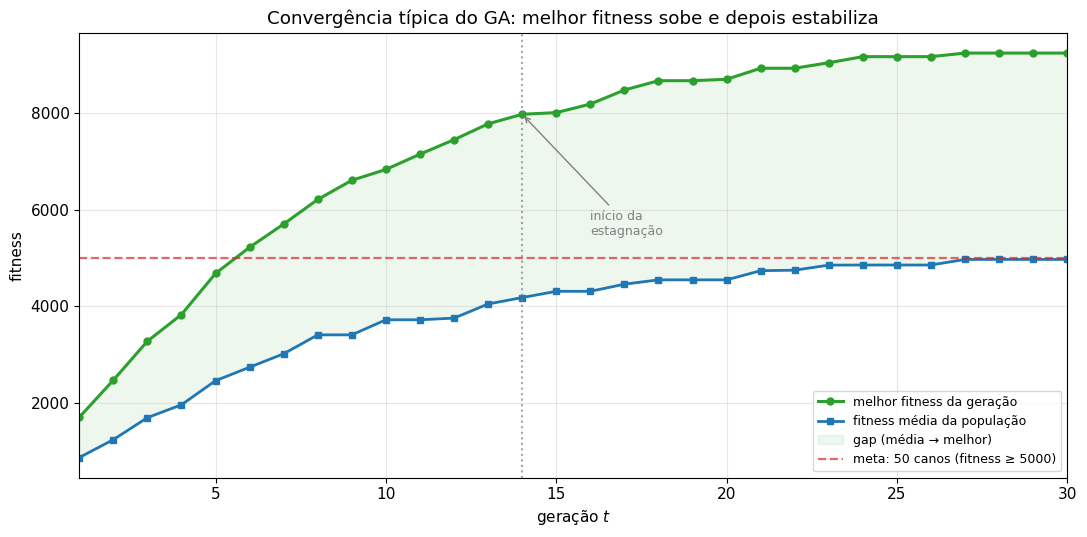

Melhor fitness final:   9251
Fitness média final:    4971
Gap final (melhor−média): 4279

Progresso por fase:
  geração  1: melhor =   1697   média =    864
  geração  5: melhor =   4682   média =   2456
  geração 10: melhor =   6836   média =   3720
  geração 15: melhor =   8015   média =   4310
  geração 20: melhor =   8707   média =   4547
  geração 30: melhor =   9251   média =   4971


In [ ]:
# Curva de convergência simulada ao longo de 30 gerações
# Mostra o comportamento típico: melhor fitness sobe e estabiliza,
# média da população também sobe mas com mais ruído.

np.random.seed(11)
geracoes = np.arange(1, 31)

# Melhor fitness: crescimento do tipo saturação (1 - exp(-t/τ))
melhor = 500 + 9000 * (1 - np.exp(-geracoes / 8))
# Ruído pequeno sobre a curva ideal para parecer real
melhor = melhor + np.random.normal(0, 80, len(geracoes))
# Força monotonicidade não-decrescente (elitismo garante que nunca piora)
melhor = np.maximum.accumulate(melhor)

# Média: proporcional ao melhor, com mais ruído
media = melhor * 0.55 + np.random.normal(0, 120, len(geracoes))
media = np.maximum.accumulate(media * 0.95)  # leve suavização + monotonicidade

fig, ax = plt.subplots(figsize=(11, 5.5))

ax.plot(geracoes, melhor, marker='o', markersize=5,
        label='melhor fitness da geração', color='#2ca02c', linewidth=2.2)
ax.plot(geracoes, media, marker='s', markersize=4.5,
        label='fitness média da população', color='#1f77b4', linewidth=2)

# Faixa sombreada entre média e melhor (representa "gap" de diversidade)
ax.fill_between(geracoes, media, melhor, color='#2ca02c', alpha=0.08,
                label='gap (média → melhor)')

# Linha da meta (50 canos × 100)
ax.axhline(100 * 50, color='#d62728', linestyle='--', alpha=0.7,
           linewidth=1.6, label='meta: 50 canos (fitness ≥ 5000)')

# Anotação no ponto onde a curva começa a estabilizar (visual)
idx_estagnacao = np.argmax(np.diff(melhor) < 100)  # primeira geração em que melhora < 100
if idx_estagnacao > 0:
    ax.axvline(geracoes[idx_estagnacao], color='gray',
               linestyle=':', alpha=0.7)
    ax.annotate('início da\nestagnação',
                xy=(geracoes[idx_estagnacao], melhor[idx_estagnacao]),
                xytext=(geracoes[idx_estagnacao] + 2,
                        melhor[idx_estagnacao] - 2500),
                arrowprops=dict(arrowstyle='->', color='gray'),
                fontsize=9, color='gray')

ax.set_title('Convergência típica do GA: melhor fitness sobe e depois estabiliza')
ax.set_xlabel('geração $t$')
ax.set_ylabel('fitness')
ax.set_xlim(1, 30)
ax.legend(loc='lower right', fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Estatísticas resumidas
print(f"Melhor fitness final:   {melhor[-1]:.0f}")
print(f"Fitness média final:    {media[-1]:.0f}")
print(f"Gap final (melhor−média): {(melhor[-1]-media[-1]):.0f}")
print(f"\nProgresso por fase:")
for g in [1, 5, 10, 15, 20, 30]:
    idx = g - 1
    print(f"  geração {g:>2}: melhor = {melhor[idx]:6.0f}   "
          f"média = {media[idx]:6.0f}")

# PARTE J — GLOSSÁRIO

---

## J.1 Tabela de todos os símbolos usados no documento

| Símbolo | Nome | Significado resumido |
|---------|------|----------------------|
| $g$ | Genoma | Vetor de 6 números do pássaro |
| $g_i$ | Genoma do indivíduo $i$ | |
| $g[j]$ | Gene $j$ | Elemento na posição $j$ do vetor |
| $w_1, \dots, w_5$ | Pesos | Multiplicadores das entradas |
| $b$ | Bias | Tendência base do pássaro |
| $x_1, \dots, x_5$ | Entradas | Sensores do pássaro, normalizados |
| $z$ | Soma ponderada | Resultado da multiplicação soma |
| $\sigma(z)$ | Sigmoide | Função de ativação |
| $e$ | Número de Euler | Constante ≈ 2.71828 |
| $\sim$ | "tem distribuição" | Ex.: $u \sim U(0,1)$ |
| $U(0,1)$ | Uniforme | Sorteio uniforme entre 0 e 1 |
| $\mathcal{N}(0, \sigma^2)$ | Normal | Sorteio gaussiano |
| $\sigma$ (isolado) | Desvio-padrão | Espalhamento da normal |
| $\Delta$ | Delta | Perturbação da mutação |
| $\sum$ | Somatório | "Some todos os termos" |
| $i, j$ | Índices | Contadores |
| $f(g)$ | Fitness | Nota do pássaro |
| $p_i$ | Probabilidade | Chance do indivíduo $i$ |
| $N$ | Tamanho da população | Nº de pássaros |
| $E$ | Elites | Nº dos melhores copiados |
| $k$ | Tamanho do torneio | Nº sorteados por torneio |
| $p_c$ | Taxa de cruzamento | Prob. de cruzar |
| $p_m$ | Prob. de mutação | Prob. de mutar por gene |
| $\lambda$ | Lambda | Peso do cruzamento aritmético |
| $P(t)$ | População na geração $t$ | |
| $P_{t+1}$ | Nova população | |
| $y$ | Posição vertical | Coordenada Y do pássaro |
| $v_y$ | Velocidade vertical | |
| $a$ | Aceleração | Gravidade |
| $v_{\text{salto}}$ | Velocidade de pulo | |
| $H$ | Altura da tela | |
| $W$ | Largura da tela | |
| $t$ | Frame ou geração | Depende do contexto |
| $G$ | Máx. gerações | |
| $C_{\max}$ | Meta de canos | |
| $K$ | Gerações sem melhora | |
| $c$ | Canos ultrapassados | |
| $d$ | Distância percorrida | |

---

## J.2 Tabela de todos os termos técnicos com definição em uma frase

| Termo | Definição em uma frase |
|-------|------------------------|
| Algoritmo Genético | Método de busca inspirado em evolução biológica que melhora uma população de soluções ao longo de gerações |
| Gene | Cada número individual de um genoma |
| Genoma | O vetor completo de números que define um indivíduo |
| Indivíduo | Um genoma particular (um pássaro) |
| População | Conjunto de indivíduos avaliados simultaneamente |
| Geração | Uma rodada completa de avaliação + reprodução |
| Fitness | Nota de desempenho usada para seleção |
| Seleção | Processo de escolher quais indivíduos serão pais |
| Torneio | Método de seleção em que se sorteiam $k$ e o melhor vence |
| Roleta | Método de seleção proporcional ao fitness |
| Elitismo | Cópia dos melhores intactos para a nova geração |
| Cruzamento | Mistura dos genes de dois pais para gerar filho |
| Mutação | Perturbação aleatória nos genes do filho |
| Clipping | Limitar cada gene a um intervalo |
| Ótimo local | Solução boa na vizinhança mas não globalmente ótima |
| Convergência | Momento em que a população fica homogênea |
| Convergência prematura | Convergir cedo demais para um ótimo local ruim |
| Diversidade | Variedade genética na população |
| Pressão seletiva | Quanto favorecemos os melhores |
| Normalização | Transformar valores em $[0, 1]$ |
| Sigmoide | Função de ativação que aperta valor para $[0,1]$ |
| Bias | Constante somada à soma ponderada |
| Peso | Multiplicador de uma entrada |
| Entrada sensorial | Informação que o pássaro "vê" |
| Frame | Um passo de tempo discreto na simulação |
| Estagnação | Algoritmo para de melhorar por várias gerações |
| Elites | Os melhores copiados intactos |
| Pais | Indivíduos escolhidos para reproduzir |
| Filhos | Indivíduos gerados por cruzamento + mutação |
| Reset | Mutação radical que substitui gene por valor novo |
| Cruzamento uniforme | Cada gene sorteado independente de qual pai vem |
| Cruzamento aritmético | Filho é média ponderada dos pais |

---

## Palavras finais

Este documento cobriu toda a matemática necessária para implementar e defender o Algoritmo Genético aplicado ao Flappy Bird. A Fase 1 (próxima) será a implementação em HTML/CSS/JS, onde cada símbolo e cada fórmula aqui explicados vai virar linha de código.

**Se você entendeu este documento, você consegue:**

1. Explicar todo o processo evolutivo na arguição oral
2. Justificar cada parâmetro escolhido
3. Debugar o código na Fase 1 sabendo o que cada trecho deveria fazer
4. Comparar variantes (uniforme vs aritmético, torneio vs roleta) com base matemática

Guarde este arquivo como `FASE0_MATEMATICA.md` no repositório do projeto. Ele é a base teórica que sustenta a implementação e a arguição.